# Análise epidemiológica da vigilância do VIH em Moçambique (incl. PTV)

Notebook passo a passo: da lista nominal de casos ao relatório final, passando pela limpeza, epidemiologia
descritiva, taxas padronizadas, regressões de Poisson e logística, tendências, previsão até 2030 e mapas.

> ⚠️ **Dados simulados.** Os dados vêm de `gerar_dados_simulados.py` e são **fictícios**. Servem para aprender e
> validar os métodos: como conhecemos os "valores verdadeiros" da simulação, podemos verificar se cada passo
> os recupera.

**Antes de começar**

1. Este notebook tem de estar na **pasta do projeto** (ao lado de `gerar_dados_simulados.py`).
2. Os dados fictícios têm de existir em `dados/brutos/` (se não existirem: `python gerar_dados_simulados.py`).
3. Corre as células **por ordem**, de cima para baixo (*Run All* também funciona; demora cerca de 1 minuto).

| Passo | O que faz |
|---|---|
| 1 | Configuração: bibliotecas, pastas, parâmetros |
| 2 | Importação e limpeza dos dados |
| 3 | Análise descritiva — pessoa, lugar e tempo |
| 4 | Medidas epidemiológicas — taxas, IC 95 %, padronização |
| 5 | Análise de associação — Poisson e logística |
| 6 | Tendências e previsão até 2030 |
| 7 | Relatório final (HTML) — definido aqui, gerado no fim |
| 8 | Análise geoespacial por província (opcional: precisa do mapa) |


Se faltar alguma biblioteca, tira o `#` da linha abaixo e corre a célula uma vez.

In [1]:
# %pip install pandas numpy matplotlib scipy statsmodels patsy geopandas libpysal esda

---
## Passo 1 — Configuração

Tudo o que pode mudar de uma análise para outra fica **num só sítio**: caminhos, anos, nível de confiança,
grupos etários, metas, cores. Assim nunca é preciso procurar números "escondidos" no meio do código.

- **1.2 Caminhos** – usamos `pathlib`, que funciona igual em Windows, Linux e Mac.
- **1.3 Parâmetros** – se quiseres analisar outro período ou mudar o ano de referência da padronização, é aqui.
- **1.4 Gráficos** – paleta testada para daltonismo; cada entidade (sexo, região) tem sempre a mesma cor.
- **1.5 Registo (log)** – as mensagens aparecem no notebook **e** ficam guardadas em `resultados/registos/`.


In [2]:
%matplotlib inline

### 1.1 Bibliotecas

In [3]:
import json
import logging
import re
import sys
import unicodedata
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

# No Windows, a consola pode não mostrar acentos/símbolos: forçar UTF-8
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8")

### 1.2 Caminhos (pastas e ficheiros)

In [4]:
#     pathlib funciona igual em Windows, Linux e Mac.
PASTA_PROJETO = Path.cwd()          # o notebook deve estar na pasta do projeto

PASTAS = {
    "brutos":      PASTA_PROJETO / "dados" / "brutos",        # dados originais (nunca editar!)
    "processados": PASTA_PROJETO / "dados" / "processados",   # dados limpos
    "tabelas":     PASTA_PROJETO / "resultados" / "tabelas",
    "figuras":     PASTA_PROJETO / "resultados" / "figuras",
    "registos":    PASTA_PROJETO / "resultados" / "registos", # ficheiros de log
}

FICHEIROS = {
    "casos":     PASTAS["brutos"] / "casos_vih.csv",
    "ptv":       PASTAS["brutos"] / "ptv_mensal.csv",
    "populacao": PASTAS["brutos"] / "populacao.csv",
}

### 1.3 Parâmetros da análise (mudar aqui, não no meio do código)

In [5]:
ANO_INICIO = 2019
ANO_FIM = 2025
POR_HABITANTES = 100_000                  # taxas expressas por 100 000 habitantes
NIVEL_CONFIANCA = 0.95                    # para os intervalos de confiança
ANO_REFERENCIA_PADRONIZACAO = 2019        # população-padrão para taxas padronizadas

# Nomes oficiais das províncias e respetiva região
PROVINCIAS = {
    "Niassa": "Norte", "Cabo Delgado": "Norte", "Nampula": "Norte",
    "Zambézia": "Centro", "Tete": "Centro", "Manica": "Centro", "Sofala": "Centro",
    "Inhambane": "Sul", "Gaza": "Sul", "Maputo Província": "Sul", "Maputo Cidade": "Sul",
}
ORDEM_PROVINCIAS = list(PROVINCIAS)       # de norte para sul

# Grupos etários (iguais aos do ficheiro de população)
LIMITES_IDADE = [0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 120]
GRUPOS_ETARIOS = ["0-4", "5-9", "10-14", "15-19", "20-24", "25-29",
                  "30-34", "35-39", "40-44", "45-49", "50+"]

# Limites de plausibilidade (usados na limpeza – Passo 2)
IDADE_MAX = 100
CD4_MIN, CD4_MAX = 0, 5000

# Regras de limpeza (decisões tomadas em conjunto)
REGRA_RENOTIFICACAO = "primeira"          # mesmo ID várias vezes → fica a 1.ª notificação
IMPUTAR_DATA_DIAGNOSTICO = True           # sem data de diagnóstico → usa a de notificação
MOSTRAR_VISAO_GERAL = False               # True = imprime o resumo das tabelas no ecrã

# Metas 95-95-95 da ONUSIDA (para comparação na PTV)
META_TESTAGEM_GESTANTES = 0.95
META_TARV_GESTANTES = 0.95
META_TRANSMISSAO_VERTICAL = 0.05          # < 5 % em populações que amamentam

### 1.4 Aparência dos gráficos

In [6]:
# Paleta validada para daltonismo (ordem fixa: azul, laranja, verde-água).
# Cada entidade tem sempre a mesma cor em todos os gráficos.
CORES = {
    "principal": "#2a78d6", "secundaria": "#eb6834", "terciaria": "#1baf7a",
    "M": "#2a78d6", "F": "#eb6834",
    "Norte": "#2a78d6", "Centro": "#eb6834", "Sul": "#1baf7a",
    "texto": "#0b0b0b", "texto_secundario": "#52514e", "eixos": "#898781",
    "grelha": "#e1e0d9", "fundo": "#fcfcfb", "meta": "#52514e",
}
ESCALA_SEQUENCIAL = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEXO_ROTULO = {"M": "Masculino", "F": "Feminino"}

plt.rcParams.update({
    "figure.figsize": (10, 6), "figure.dpi": 110, "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.facecolor": CORES["fundo"],
    "axes.facecolor": CORES["fundo"], "savefig.facecolor": CORES["fundo"],
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": CORES["eixos"], "axes.labelcolor": CORES["texto_secundario"],
    "xtick.color": CORES["texto_secundario"], "ytick.color": CORES["texto_secundario"],
    "axes.grid": True, "grid.color": CORES["grelha"], "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "axes.titlesize": 13,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "text.color": CORES["texto"],
    "legend.frameon": False, "lines.linewidth": 2,
})
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

### 1.5 Registo (log): mostra mensagens no ecrã E guarda-as num ficheiro

In [7]:
log = logging.getLogger("analise_vih")


def configurar_registo() -> Path:
    """Prepara o log. Cada execução cria um ficheiro novo com data e hora."""
    PASTAS["registos"].mkdir(parents=True, exist_ok=True)
    ficheiro_log = PASTAS["registos"] / f"analise_{datetime.now():%Y%m%d_%H%M%S}.log"
    log.setLevel(logging.INFO)
    log.handlers.clear()
    formato = logging.Formatter("%(asctime)s | %(levelname)-7s | %(message)s", "%H:%M:%S")
    for destino in (logging.StreamHandler(sys.stdout),
                    logging.FileHandler(ficheiro_log, encoding="utf-8")):
        destino.setFormatter(formato)
        log.addHandler(destino)
    return ficheiro_log

### 1.6 Funções de apoio

In [8]:
def criar_pastas() -> None:
    """Cria todas as pastas do projeto, se ainda não existirem."""
    for pasta in PASTAS.values():
        pasta.mkdir(parents=True, exist_ok=True)


def verificar_ficheiros() -> bool:
    """Confirma que os ficheiros de dados existem antes de começar."""
    tudo_ok = True
    for nome, caminho in FICHEIROS.items():
        if caminho.exists():
            log.info(f"  ✔ {nome:<10} {caminho.name} ({caminho.stat().st_size / 1e6:.1f} MB)")
        else:
            log.error(f"  ✘ {nome:<10} NÃO ENCONTRADO: {caminho}")
            tudo_ok = False
    if not tudo_ok:
        log.error("Corre primeiro:  python gerar_dados_simulados.py")
    return tudo_ok


def ler_csv(caminho: Path) -> pd.DataFrame:
    """Lê um CSV como texto (sem converter nada) – a conversão é feita no Passo 2."""
    return pd.read_csv(caminho, dtype=str, encoding="utf-8-sig", keep_default_na=False,
                       na_values=[""])


def visao_geral(df: pd.DataFrame, nome: str) -> pd.DataFrame:
    """Primeiro olhar sobre uma tabela: dimensão, tipos, valores em falta e exemplos."""
    log.info(f"--- {nome}: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_em_falta": df.isna().sum(),
        "%_em_falta": (df.isna().mean() * 100).round(1),
        "n_valores_distintos": df.nunique(),
        "exemplo": df.apply(lambda c: c.dropna().iloc[0] if c.notna().any() else None),
    })
    print(resumo.to_string(), "\n")
    return resumo


def versoes() -> None:
    log.info(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
             f"numpy {np.__version__} | matplotlib {matplotlib.__version__}")

### Executar o Passo 1
Esta célula cria as pastas, confirma que os ficheiros existem e lê os dados **como texto** (sem converter nada —
as conversões são feitas, com controlo, no Passo 2).

In [9]:
def passo1_configuracao() -> dict[str, pd.DataFrame]:
    log.info("=" * 70)
    log.info("PASSO 1 — CONFIGURAÇÃO")
    log.info("=" * 70)
    versoes()
    criar_pastas()
    log.info(f"Pasta do projeto: {PASTA_PROJETO}")
    log.info("Ficheiros de dados:")
    if not verificar_ficheiros():
        sys.exit(1)
    brutos = {nome: ler_csv(caminho) for nome, caminho in FICHEIROS.items()}
    if MOSTRAR_VISAO_GERAL:
        for nome, df in brutos.items():
            visao_geral(df, f"{nome} (bruto)")
    return brutos


ficheiro_log = configurar_registo()
brutos = passo1_configuracao()
{nome: df.shape for nome, df in brutos.items()}

04:53:25 | INFO    | ======================================================================
04:53:25 | INFO    | PASSO 1 — CONFIGURAÇÃO
04:53:25 | INFO    | ======================================================================
04:53:25 | INFO    | Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0
04:53:25 | INFO    | Pasta do projeto: C:\Users\User\Downloads\projeto_vih_vigilancia_notebook\projeto_vih_vigilancia
04:53:25 | INFO    | Ficheiros de dados:
04:53:25 | INFO    |   ✔ casos      casos_vih.csv (19.2 MB)
04:53:25 | INFO    |   ✔ ptv        ptv_mensal.csv (0.1 MB)
04:53:25 | INFO    |   ✔ populacao  populacao.csv (0.0 MB)


{'casos': (209118, 10), 'ptv': (900, 10), 'populacao': (1694, 5)}

---
## Passo 2 — Importação e limpeza

Dados de vigilância reais têm sempre problemas. Os dados simulados têm-nos **de propósito**: províncias escritas
de várias formas, sexo codificado de maneiras diferentes, datas em dois formatos, idades impossíveis,
duplicados, re-notificações, homens registados como gestantes…

**Princípios**

1. Os dados brutos **nunca** são alterados — trabalhamos numa cópia.
2. Cada problema é **contado e registado**, com a ação tomada (tabela `02_qualidade_dados.csv`).
3. Um valor impossível passa a **em falta** — não se inventam valores, exceto nas imputações explícitas,
   assinaladas em colunas `imputado_*`:
   - **sexo** em falta, mas gestante / CPN / maternidade → F;
   - **data de diagnóstico** em falta → a data mais antiga entre notificação e início de TARV
     (o diagnóstico acontece sempre antes de ambas).
4. **Re-notificações** (mesmo ID): fica a **primeira** notificação.

> 💡 **Lição aprendida:** na primeira versão a data de diagnóstico em falta era imputada com a data de
> notificação. Isso criou ~660 falsos "TARV antes do diagnóstico", porque o TARV começa em média 7 dias após o
> diagnóstico e a notificação chega até 30 dias depois. A verificação automática (2.7) apanhou o erro.


### 2.1 Registo de qualidade dos dados

In [10]:
class RegistoQualidade:
    """Guarda cada problema encontrado: código, descrição, n.º de registos e ação."""

    def __init__(self, tabela: str):
        self.tabela = tabela
        self.linhas = []

    def adicionar(self, codigo: str, descricao: str, n: int, acao: str) -> None:
        n = int(n)
        self.linhas.append({"tabela": self.tabela, "codigo": codigo,
                            "problema": descricao, "n_registos": n, "acao": acao})
        if n:
            log.info(f"  • {descricao}: {n:,} → {acao}")

    def tabela_resumo(self, n_total: int) -> pd.DataFrame:
        df = pd.DataFrame(self.linhas)
        df["%"] = (df["n_registos"] / n_total * 100).round(2)
        return df

### 2.2 Funções genéricas de limpeza

In [11]:
VALORES_DESCONHECIDOS = {"desconhecido", "ignorado", "nd", "na", "n a", "sem informacao", "-"}


def normalizar_texto(valor) -> str | None:
    """'  Cabo-Delgado ' → 'cabo delgado' (minúsculas, sem acentos, sem pontuação)."""
    if pd.isna(valor):
        return None
    texto = unicodedata.normalize("NFD", str(valor))
    texto = "".join(c for c in texto if unicodedata.category(c) != "Mn")
    texto = re.sub(r"[^a-z0-9 ]", " ", texto.lower())
    texto = re.sub(r"\s+", " ", texto).strip()
    return None if texto in VALORES_DESCONHECIDOS or not texto else texto


def recodificar(serie: pd.Series, mapa: dict, nome: str) -> pd.Series:
    """Normaliza o texto e traduz com o dicionário. Avisa sobre valores desconhecidos."""
    normalizado = serie.map(normalizar_texto)
    resultado = normalizado.map(mapa)
    nao_reconhecidos = normalizado.notna() & resultado.isna()
    if nao_reconhecidos.any():
        exemplos = sorted(serie[nao_reconhecidos].astype(str).unique())[:10]
        log.warning(f"  ! {nome}: {nao_reconhecidos.sum()} valores não reconhecidos "
                    f"(passam a 'em falta'): {exemplos}")
    return resultado.astype(object).where(resultado.notna(), None)


def converter_datas(serie: pd.Series) -> pd.Series:
    """Aceita AAAA-MM-DD e DD/MM/AAAA. Com formatos explícitos o dia e o mês nunca trocam."""
    iso = pd.to_datetime(serie, format="%Y-%m-%d", errors="coerce")
    pt = pd.to_datetime(serie, format="%d/%m/%Y", errors="coerce")
    datas = iso.fillna(pt)
    falhas = serie.notna() & datas.isna()
    if falhas.any():
        log.warning(f"  ! {serie.name}: {falhas.sum()} datas em formato desconhecido "
                    f"(ex.: {serie[falhas].iloc[0]!r}) → em falta")
    return datas


def converter_numeros(serie: pd.Series) -> pd.Series:
    """Texto → número. Aceita vírgula decimal ('3,5'). Lixo passa a em falta."""
    return pd.to_numeric(serie.astype(str).str.replace(",", ".", regex=False)
                         .where(serie.notna()), errors="coerce")

### 2.3 Dicionários de recodificação

In [12]:
SINONIMOS_PROVINCIA = {             # forma normalizada → nome oficial
    "cidade de maputo": "Maputo Cidade", "c maputo": "Maputo Cidade",
    "maputo city": "Maputo Cidade", "prov maputo": "Maputo Província",
    "c delgado": "Cabo Delgado", "zambezia": "Zambézia",
}
MAPA_PROVINCIAS = {normalizar_texto(p): p for p in PROVINCIAS} | SINONIMOS_PROVINCIA

MAPA_SEXO = {"m": "M", "masculino": "M", "masc": "M", "homem": "M",
             "f": "F", "feminino": "F", "fem": "F", "mulher": "F"}

MAPA_SIM_NAO = {"sim": "Sim", "s": "Sim", "nao": "Não", "n": "Não",
                "nao aplicavel": "Não aplicável"}

### 2.4 Limpeza da lista nominal de casos

In [13]:
def limpar_casos(bruto: pd.DataFrame) -> tuple[pd.DataFrame, RegistoQualidade, list]:
    log.info("Limpeza de casos_vih:")
    df = bruto.copy()
    rq = RegistoQualidade("casos_vih")
    fluxo = [("Registos recebidos", len(df))]

    # a) Duplicados exatos (a mesma ficha introduzida duas vezes)
    dup = df.duplicated(keep="first")
    rq.adicionar("duplicados_exatos", "Linhas exatamente repetidas", dup.sum(), "removidas")
    df = df.loc[~dup].copy()
    fluxo.append(("Após remover duplicados exatos", len(df)))

    # b) Datas (texto → data). Primeiro contamos os formatos encontrados.
    formato_pt = df["data_diagnostico"].str.match(r"^\d{2}/\d{2}/\d{4}$", na=False)
    for col in ["data_diagnostico", "data_notificacao", "data_inicio_tarv"]:
        df[col] = converter_datas(df[col])

    # c) Re-notificações: o mesmo caso (ID) notificado mais de uma vez
    df = df.sort_values(["id_caso", "data_notificacao"], na_position="last")
    manter = "first" if REGRA_RENOTIFICACAO == "primeira" else "last"
    renot = df.duplicated(subset="id_caso", keep=manter)
    rq.adicionar("renotificacoes_mesmo_id", "Re-notificações (ID repetido)", renot.sum(),
                 f"mantida a {REGRA_RENOTIFICACAO} notificação")
    df = df.loc[~renot].copy()
    fluxo.append(("Após remover re-notificações", len(df)))
    formato_pt = formato_pt.loc[df.index]
    original = df.copy()          # versão deduplicada, ainda por corrigir (para contagens)

    # d) Província
    df["provincia"] = recodificar(df["provincia"], MAPA_PROVINCIAS, "provincia")
    corrigidas = df["provincia"].notna() & (df["provincia"] != original["provincia"])
    rq.adicionar("provincia_grafia_inconsistente", "Província com grafia diferente da oficial",
                 corrigidas.sum(), "corrigida para o nome oficial")
    rq.adicionar("provincia_desconhecida", "Província não reconhecida",
                 df["provincia"].isna().sum(), "em falta")

    # e) Sexo
    df["sexo"] = recodificar(df["sexo"], MAPA_SEXO, "sexo")
    recod = df["sexo"].notna() & (df["sexo"] != original["sexo"])
    rq.adicionar("sexo_codificacao_variada", "Sexo codificado de forma não padronizada",
                 recod.sum(), "recodificado para M/F")
    rq.adicionar("sexo_em_falta", "Sexo em falta ou desconhecido",
                 df["sexo"].isna().sum(), "em falta (ver imputação abaixo)")
    # Se está registada como gestante ou entrou pela CPN/maternidade, é mulher
    gest_bruto = df["gestante"].map(normalizar_texto) == "sim"
    pe_materno = df["ponto_entrada"].isin(["CPN", "Maternidade"])
    imput_sexo = df["sexo"].isna() & (gest_bruto | pe_materno)
    df.loc[imput_sexo, "sexo"] = "F"
    df["imputado_sexo"] = imput_sexo
    rq.adicionar("sexo_imputado", "Sexo em falta, mas gestante/CPN/maternidade",
                 imput_sexo.sum(), "imputado como F (assinalado)")

    # f) Idade
    df["idade"] = converter_numeros(df["idade"])
    rq.adicionar("idade_em_falta", "Idade em falta", df["idade"].isna().sum(), "em falta")
    impossivel = (df["idade"] < 0) | (df["idade"] > IDADE_MAX)
    rq.adicionar("idade_impossivel", f"Idade impossível (<0 ou >{IDADE_MAX})",
                 impossivel.sum(), "passa a em falta")
    df.loc[impossivel, "idade"] = np.nan
    df["idade"] = df["idade"].round().astype("Int64")

    # g) Datas: coerência temporal
    rq.adicionar("data_diagnostico_formato_dd_mm_aaaa", "Data de diagnóstico em DD/MM/AAAA",
                 formato_pt.sum(), "convertida para data")
    sem_diag = df["data_diagnostico"].isna()
    rq.adicionar("data_diagnostico_em_falta", "Data de diagnóstico em falta", sem_diag.sum(),
                 "imputada = data mais antiga entre notificação e início de TARV"
                 if IMPUTAR_DATA_DIAGNOSTICO else "em falta")
    df["imputado_data_diagnostico"] = sem_diag & IMPUTAR_DATA_DIAGNOSTICO
    if IMPUTAR_DATA_DIAGNOSTICO:
        # O diagnóstico acontece sempre ANTES da notificação e do início do TARV.
        # Usar só a notificação criaria falsos "TARV antes do diagnóstico".
        mais_antiga = df[["data_notificacao", "data_inicio_tarv"]].min(axis=1)
        df.loc[sem_diag, "data_diagnostico"] = mais_antiga[sem_diag]

    notif_antes = df["data_notificacao"] < df["data_diagnostico"]
    rq.adicionar("notificacao_antes_do_diagnostico", "Notificação antes do diagnóstico",
                 notif_antes.sum(), "data de notificação passa a em falta")
    df.loc[notif_antes, "data_notificacao"] = pd.NaT

    df["iniciou_tarv"] = df["data_inicio_tarv"].notna()   # antes de anular datas inválidas
    tarv_antes = df["data_inicio_tarv"] < df["data_diagnostico"]
    rq.adicionar("tarv_antes_do_diagnostico", "Início de TARV antes do diagnóstico",
                 tarv_antes.sum(), "data de TARV passa a em falta (iniciou_tarv mantém-se)")
    df.loc[tarv_antes, "data_inicio_tarv"] = pd.NaT

    # h) Gestante
    df["gestante"] = recodificar(df["gestante"], MAPA_SIM_NAO, "gestante")
    homem_gest = (df["sexo"] == "M") & (df["gestante"] == "Sim")
    rq.adicionar("homem_registado_como_gestante", "Homem registado como gestante",
                 homem_gest.sum(), "corrigido para 'Não aplicável'")
    df.loc[homem_gest | (df["sexo"] == "M"), "gestante"] = "Não aplicável"

    # i) CD4
    df["cd4_diagnostico"] = converter_numeros(df["cd4_diagnostico"])
    cd4_mau = (df["cd4_diagnostico"] < CD4_MIN) | (df["cd4_diagnostico"] > CD4_MAX)
    rq.adicionar("cd4_impossivel", f"CD4 fora do intervalo {CD4_MIN}–{CD4_MAX}",
                 cd4_mau.sum(), "passa a em falta")
    df.loc[cd4_mau, "cd4_diagnostico"] = np.nan

    # j) Período de análise
    fora = ~df["data_diagnostico"].dt.year.between(ANO_INICIO, ANO_FIM)
    rq.adicionar("fora_do_periodo", f"Diagnóstico fora de {ANO_INICIO}–{ANO_FIM} ou sem data",
                 fora.sum(), "excluído")
    df = df.loc[~fora].copy()
    fluxo.append(("Casos incluídos na análise", len(df)))

    # k) Variáveis derivadas (prontas para os passos seguintes)
    d = df["data_diagnostico"]
    df["ano"] = d.dt.year
    df["mes"] = d.dt.month
    df["trimestre"] = d.dt.to_period("Q").astype(str)
    df["ano_mes"] = d.dt.to_period("M").astype(str)
    df["regiao"] = df["provincia"].map(PROVINCIAS)
    df["grupo_etario"] = pd.cut(df["idade"].astype(float), bins=LIMITES_IDADE,
                                labels=GRUPOS_ETARIOS, right=False)
    df["faixa_etaria"] = pd.cut(df["idade"].astype(float), bins=[0, 15, 25, 120], right=False,
                                labels=["Criança (0-14)", "Jovem (15-24)", "Adulto (25+)"])
    df["atraso_notificacao_dias"] = (df["data_notificacao"] - d).dt.days
    df["dias_ate_tarv"] = (df["data_inicio_tarv"] - d).dt.days
    df["tarv_ate_7_dias"] = (df["dias_ate_tarv"] <= 7).astype("boolean").mask(df["dias_ate_tarv"].isna())
    df.loc[~df["iniciou_tarv"], "tarv_ate_7_dias"] = False
    df["cd4_categoria"] = pd.cut(df["cd4_diagnostico"], bins=[0, 200, 350, 500, np.inf],
                                 labels=["<200", "200-349", "350-499", "≥500"], right=False)
    df["doenca_avancada"] = (df["cd4_diagnostico"] < 200).astype("boolean").mask(df["cd4_diagnostico"].isna())

    ordem = ["id_caso", "data_diagnostico", "ano", "mes", "trimestre", "ano_mes",
             "provincia", "regiao", "sexo", "idade", "grupo_etario", "faixa_etaria",
             "ponto_entrada", "gestante", "cd4_diagnostico", "cd4_categoria", "doenca_avancada",
             "data_notificacao", "atraso_notificacao_dias",
             "iniciou_tarv", "data_inicio_tarv", "dias_ate_tarv", "tarv_ate_7_dias",
             "imputado_sexo", "imputado_data_diagnostico"]
    df = df[ordem].sort_values(["data_diagnostico", "id_caso"]).reset_index(drop=True)
    return df, rq, fluxo

### 2.5 Limpeza do relatório mensal da PTV

In [14]:
COLUNAS_PTV = ["gestantes_cpn", "gestantes_testadas", "gestantes_positivas", "gestantes_em_tarv",
               "criancas_expostas", "criancas_pcr_2meses", "criancas_pcr_positivo"]

# Cascata lógica: o numerador nunca pode ser maior que o denominador
REGRAS_CASCATA_PTV = [
    ("gestantes_testadas", "gestantes_cpn"),
    ("gestantes_positivas", "gestantes_testadas"),
    ("gestantes_em_tarv", "gestantes_positivas"),
    ("criancas_expostas", "gestantes_positivas"),
    ("criancas_pcr_2meses", "criancas_expostas"),
    ("criancas_pcr_positivo", "criancas_pcr_2meses"),
]


def limpar_ptv(bruto: pd.DataFrame) -> tuple[pd.DataFrame, RegistoQualidade, pd.DataFrame]:
    log.info("Limpeza de ptv_mensal:")
    df = bruto.copy()
    rq = RegistoQualidade("ptv_mensal")

    dup = df.duplicated()
    rq.adicionar("linhas_duplicadas", "Linhas exatamente repetidas", dup.sum(), "removidas")
    df = df.loc[~dup].copy()

    prov_original = df["provincia"].copy()
    df["provincia"] = recodificar(df["provincia"], MAPA_PROVINCIAS, "provincia")
    rq.adicionar("provincia_grafia_inconsistente", "Província com grafia diferente da oficial",
                 (df["provincia"].notna() & (df["provincia"] != prov_original)).sum(),
                 "corrigida para o nome oficial")

    for col in ["ano", "mes"] + COLUNAS_PTV:
        df[col] = converter_numeros(df[col])
    rq.adicionar("valores_em_falta", "Células de indicadores em falta",
                 df[COLUNAS_PTV].isna().sum().sum(), "mantidas em falta")

    # Mesmo relatório (província-ano-mês) duas vezes com valores diferentes
    chave = ["provincia", "ano", "mes"]
    dup_chave = df.duplicated(subset=chave, keep="first")
    rq.adicionar("relatorio_repetido", "Relatório repetido com valores diferentes",
                 dup_chave.sum(), "mantido o primeiro")
    df = df.loc[~dup_chave].copy()

    # Coerência da cascata
    n_incoerentes = 0
    for numerador, denominador in REGRAS_CASCATA_PTV:
        erro = df[numerador] > df[denominador]
        if erro.any():
            log.info(f"    {numerador} > {denominador}: {erro.sum()}")
        n_incoerentes += erro.sum()
        df.loc[erro, numerador] = np.nan
    rq.adicionar("testadas_maior_que_cpn", "Incoerência na cascata (numerador > denominador)",
                 n_incoerentes, "numerador passa a em falta")

    # Completude: que relatórios mensais deviam existir e não chegaram?
    grelha = pd.MultiIndex.from_product(
        [ORDEM_PROVINCIAS, range(ANO_INICIO, ANO_FIM + 1), range(1, 13)], names=chave
    ).to_frame(index=False)
    df = grelha.merge(df, on=chave, how="left", indicator=True)
    df["relatorio_recebido"] = df.pop("_merge").eq("both")
    rq.adicionar("relatorios_mensais_em_falta", "Relatórios mensais não recebidos",
                 (~df["relatorio_recebido"]).sum(), "linha criada vazia (não imputado)")

    completude = (df.groupby("provincia", sort=False)["relatorio_recebido"]
                  .agg(recebidos="sum", esperados="size"))
    completude["completude_%"] = (completude["recebidos"] / completude["esperados"] * 100).round(1)

    df["ano"] = df["ano"].astype(int)
    df["mes"] = df["mes"].astype(int)
    df[COLUNAS_PTV] = df[COLUNAS_PTV].round().astype("Int64")
    df["data"] = pd.to_datetime(dict(year=df["ano"], month=df["mes"], day=1))
    df["regiao"] = df["provincia"].map(PROVINCIAS)
    df = df[["provincia", "regiao", "ano", "mes", "data", "relatorio_recebido"] + COLUNAS_PTV]
    return df, rq, completude.reset_index()

### 2.6 Validação da população (denominadores)

In [15]:
def validar_populacao(bruto: pd.DataFrame) -> tuple[pd.DataFrame, RegistoQualidade]:
    log.info("Validação de populacao:")
    df = bruto.copy()
    rq = RegistoQualidade("populacao")
    df["provincia"] = recodificar(df["provincia"], MAPA_PROVINCIAS, "provincia")
    df["sexo"] = recodificar(df["sexo"], MAPA_SEXO, "sexo")
    df["ano"] = converter_numeros(df["ano"]).astype("Int64")
    df["populacao"] = converter_numeros(df["populacao"])

    chave = ["provincia", "ano", "sexo", "grupo_etario"]
    rq.adicionar("pop_duplicada", "Estratos duplicados", df.duplicated(subset=chave).sum(), "verificar")
    rq.adicionar("pop_invalida", "População em falta ou ≤ 0",
                 (df["populacao"].isna() | (df["populacao"] <= 0)).sum(), "verificar")
    esperado = len(ORDEM_PROVINCIAS) * (ANO_FIM - ANO_INICIO + 1) * 2 * len(GRUPOS_ETARIOS)
    em_falta = esperado - len(df.drop_duplicates(subset=chave))
    rq.adicionar("pop_estratos_em_falta", "Estratos em falta", em_falta, "verificar")
    if not any(l["n_registos"] for l in rq.linhas):
        log.info("  ✔ População completa e coerente "
                 f"({esperado} estratos: província × ano × sexo × grupo etário)")

    df["grupo_etario"] = pd.Categorical(df["grupo_etario"], categories=GRUPOS_ETARIOS, ordered=True)
    df["regiao"] = df["provincia"].map(PROVINCIAS)
    df["populacao"] = df["populacao"].astype(int)
    return df, rq

### 2.7 Comparar o que encontrámos com o que foi introduzido (só dados simulados)

In [16]:
def comparar_com_gabarito(qualidade: pd.DataFrame) -> pd.DataFrame | None:
    gabarito_ficheiro = PASTAS["brutos"] / "registo_problemas_introduzidos.json"
    if not gabarito_ficheiro.exists():
        return None
    gabarito = json.loads(gabarito_ficheiro.read_text(encoding="utf-8"))
    nomes = {"casos": "casos_vih", "ptv_mensal": "ptv_mensal"}
    linhas = []
    for tabela_json, problemas in gabarito.items():
        tabela = nomes.get(tabela_json, tabela_json)
        for codigo, n_introduzidos in problemas.items():
            achado = qualidade.query("tabela == @tabela and codigo == @codigo")["n_registos"]
            linhas.append({"tabela": tabela, "problema": codigo,
                           "introduzidos": n_introduzidos,
                           "detetados": int(achado.iloc[0]) if len(achado) else None})
    comp = pd.DataFrame(linhas)
    comp["diferenca"] = comp["detetados"] - comp["introduzidos"]
    # Diferenças esperadas: alguns erros sorteados coincidiram com o valor correto
    # (ex.: "Niassa" sem acentos = "Niassa"; sexo "M" sorteado como "M") ou foram
    # depois apagados por outro erro (ex.: data em DD/MM/AAAA que passou a "em falta").
    notas = {
        "provincia_grafia_inconsistente": "variante sorteada igual ao nome oficial",
        "sexo_codificacao_variada": "código sorteado já era 'M'/'F' ou ficou em falta",
        "data_diagnostico_formato_dd_mm_aaaa": "algumas datas foram depois apagadas",
        "idade_em_falta": "algumas idades em falta receberam valor impossível",
        "homem_registado_como_gestante": "alguns destes homens ficaram com sexo em falta",
        "notificacao_antes_do_diagnostico": "datas de diagnóstico em falta não são comparáveis",
        "tarv_antes_do_diagnostico": "idem",
        "cd4_impossivel": "a cauda da simulação gerou naturalmente algum CD4 > 5000",
        "testadas_maior_que_cpn": "algum destes valores foi depois apagado",
    }
    comp["nota"] = [notas.get(p, "") if d else "" for p, d in zip(comp["problema"], comp["diferenca"])]
    return comp

### 2.8 Função principal do Passo 2

In [17]:
def passo2_limpeza(brutos: dict[str, pd.DataFrame]) -> dict[str, pd.DataFrame]:
    log.info("=" * 70)
    log.info("PASSO 2 — IMPORTAÇÃO E LIMPEZA")
    log.info("=" * 70)

    casos, rq_casos, fluxo = limpar_casos(brutos["casos"])
    ptv, rq_ptv, completude = limpar_ptv(brutos["ptv"])
    populacao, rq_pop = validar_populacao(brutos["populacao"])

    # Fluxo de registos (útil para a secção "Métodos" de um relatório/artigo)
    fluxo = pd.DataFrame(fluxo, columns=["etapa", "n"])
    fluxo["excluidos"] = (-fluxo["n"].diff()).fillna(0).astype(int)
    log.info("Fluxo de registos (casos):")
    for e in fluxo.itertuples():
        extra = f"  (−{e.excluidos:,})" if e.excluidos else ""
        log.info(f"    {e.etapa:<35} {e.n:>8,}{extra}")

    log.info("Completude dos relatórios mensais da PTV:")
    print(completude.to_string(index=False), "\n")

    qualidade = pd.concat([rq_casos.tabela_resumo(len(brutos["casos"])),
                           rq_ptv.tabela_resumo(len(brutos["ptv"])),
                           rq_pop.tabela_resumo(len(brutos["populacao"]))], ignore_index=True)

    comparacao = comparar_com_gabarito(qualidade)
    if comparacao is not None:
        log.info("Verificação: problemas introduzidos na simulação vs. detetados pela limpeza")
        print(comparacao.to_string(index=False), "\n")

    # Guardar
    csv = dict(index=False, encoding="utf-8-sig")
    casos.to_csv(PASTAS["processados"] / "casos_limpos.csv", **csv)
    ptv.to_csv(PASTAS["processados"] / "ptv_limpo.csv", **csv)
    populacao.to_csv(PASTAS["processados"] / "populacao_limpa.csv", **csv)
    qualidade.to_csv(PASTAS["tabelas"] / "02_qualidade_dados.csv", **csv)
    fluxo.to_csv(PASTAS["tabelas"] / "02_fluxo_registos.csv", **csv)
    completude.to_csv(PASTAS["tabelas"] / "02_completude_ptv.csv", **csv)
    if comparacao is not None:
        comparacao.to_csv(PASTAS["tabelas"] / "02_verificacao_limpeza.csv", **csv)

    if MOSTRAR_VISAO_GERAL:
        visao_geral(casos, "casos (limpo)")
    log.info(f"Passo 2 concluído: {len(casos):,} casos, {len(ptv):,} relatórios PTV, "
             f"{len(populacao):,} estratos de população.")
    return {"casos": casos, "ptv": ptv, "populacao": populacao,
            "qualidade": qualidade, "completude_ptv": completude}

### Executar o Passo 2

In [18]:
dados = passo2_limpeza(brutos)

04:53:26 | INFO    | ======================================================================
04:53:26 | INFO    | PASSO 2 — IMPORTAÇÃO E LIMPEZA
04:53:26 | INFO    | ======================================================================
04:53:26 | INFO    | Limpeza de casos_vih:
04:53:26 | INFO    |   • Linhas exatamente repetidas: 3,075 → removidas
04:53:29 | INFO    |   • Re-notificações (ID repetido): 1,025 → mantida a primeira notificação
04:53:31 | INFO    |   • Província com grafia diferente da oficial: 13,788 → corrigida para o nome oficial
04:53:32 | INFO    |   • Sexo codificado de forma não padronizada: 15,017 → recodificado para M/F
04:53:32 | INFO    |   • Sexo em falta ou desconhecido: 4,105 → em falta (ver imputação abaixo)
04:53:34 | INFO    |   • Sexo em falta, mas gestante/CPN/maternidade: 594 → imputado como F (assinalado)
04:53:34 | INFO    |   • Idade em falta: 4,029 → em falta
04:53:34 | INFO    |   • Idade impossível (<0 ou >100): 645 → passa a em falta
04:53:34 | 

### O que observamos

- De **209 118** linhas recebidas ficam **205 013 casos únicos** (−3 075 duplicados exatos, −1 025 re-notificações).
- A tabela de **verificação** compara os problemas *introduzidos* na simulação com os *detetados*. Quase todos
  coincidem; as pequenas diferenças estão explicadas na coluna `nota` (por exemplo, "Niassa" sem acentos
  continua a ser "Niassa" — o "erro" sorteado era igual ao valor certo).
- A **completude** dos relatórios mensais da PTV varia entre ~94 % e 100 % por província.

Tabela de qualidade (só problemas encontrados):

In [19]:
dados["qualidade"].query("n_registos > 0")

,tabela,codigo,problema,n_registos,acao,%
0,casos_vih,duplicados_exatos,Linhas exatamente repetidas,3075,removidas,1.47
1,casos_vih,renotificacoes_mesmo_id,Re-notificações (ID repetido),1025,mantida a primeira notificação,0.49
2,casos_vih,provincia_grafia_inconsistente,Província com grafia diferente da oficial,13788,corrigida para o nome oficial,6.59
4,casos_vih,sexo_codificacao_variada,Sexo codificado de forma não padronizada,15017,recodificado para M/F,7.18
5,casos_vih,sexo_em_falta,Sexo em falta ou desconhecido,4105,em falta (ver imputação abaixo),1.96
6,casos_vih,sexo_imputado,"Sexo em falta, mas gestante/CPN/maternidade",594,imputado como F (assinalado),0.28
7,casos_vih,idade_em_falta,Idade em falta,4029,em falta,1.93
8,casos_vih,idade_impossivel,Idade impossível (<0 ou >100),645,passa a em falta,0.31
9,casos_vih,data_diagnostico_formato_dd_mm_aaaa,Data de diagnóstico em DD/MM/AAAA,40737,convertida para data,19.48
10,casos_vih,data_diagnostico_em_falta,Data de diagnóstico em falta,2003,imputada = data mais antiga entre notificação ...,0.96


---
## Passo 3 — Análise descritiva: pessoa, lugar e tempo

As três perguntas clássicas da epidemiologia descritiva:

| | Pergunta | Neste passo |
|---|---|---|
| **Pessoa** | Quem? | Tabela 1 por sexo, pirâmide etária, ponto de entrada, CD4 |
| **Lugar** | Onde? | Casos por província e região, mapa de calor província × ano |
| **Tempo** | Quando? | Curva epidémica mensal, tendência anual por sexo |

Mais a **cascata da PTV** (gestantes testadas → positivas → em TARV → crianças expostas → PCR → PCR positivo).

> Aqui trabalhamos com **contagens e percentagens**. Contagens enganam quando as populações são diferentes
> (a Zambézia tem muitos casos porque tem muita gente) — as **taxas** vêm no Passo 4.

Nas proporções da PTV usamos só os relatórios onde numerador **e** denominador existem (`proporcao_pareada`),
para um mês incompleto não distorcer o resultado.

In [20]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter

FONTE = "Fonte: dados simulados (fictícios) de vigilância do VIH, Moçambique."

### 3.1 Funções de apoio (formatação em português e gravação de resultados)

In [21]:
def fmt_int(x) -> str:
    """12345 → '12 345' (espaço como separador de milhares)."""
    return f"{x:,.0f}".replace(",", " ")


def fmt_dec(x, casas: int = 1) -> str:
    """12.345 → '12,3' (vírgula decimal)."""
    return f"{x:.{casas}f}".replace(".", ",")


def fmt_n_pct(n: int, total: int) -> str:
    return f"{fmt_int(n)} ({fmt_dec(n / total * 100)})" if total else "—"


def mediana_iiq(serie: pd.Series) -> str:
    s = serie.dropna().astype(float)
    if s.empty:
        return "—"
    q1, med, q3 = s.quantile([0.25, 0.5, 0.75])
    return f"{fmt_dec(med, 0)} [{fmt_dec(q1, 0)}–{fmt_dec(q3, 0)}]"


EIXO_MILHARES = FuncFormatter(lambda v, _: fmt_int(v))


def guardar_figura(fig, nome: str, nota: str = FONTE) -> Path:
    fig.text(0.01, -0.01, nota, fontsize=8.5, color=CORES["texto_secundario"], ha="left", va="top")
    caminho = PASTAS["figuras"] / f"{nome}.png"
    fig.savefig(caminho)
    plt.show()                      # mostra a figura no notebook
    log.info(f"  → figura: {caminho.name}")
    return caminho


def guardar_tabela(df: pd.DataFrame, nome: str, index: bool = False) -> Path:
    caminho = PASTAS["tabelas"] / f"{nome}.csv"
    df.to_csv(caminho, index=index, encoding="utf-8-sig")
    log.info(f"  → tabela: {caminho.name}")
    return caminho


def rotular_fim_linha(ax, x, y, texto, cor, dy=0):
    """Rótulo direto no fim de uma linha (evita depender só da legenda)."""
    ax.annotate(texto, (x, y), xytext=(6, dy), textcoords="offset points",
                va="center", fontsize=10, color=CORES["texto"], fontweight="bold")
    ax.plot([], [], color=cor)          # mantém a legenda coerente

### 3.2 PESSOA — Tabela 1 (características dos casos, por sexo)

In [22]:
def tabela_1(casos: pd.DataFrame) -> pd.DataFrame:
    grupos = {"Total": casos}
    grupos |= {SEXO_ROTULO[s]: casos[casos["sexo"] == s] for s in ["M", "F"]}
    linhas = [{"Variável": "N", **{g: fmt_int(len(d)) for g, d in grupos.items()}}]

    continuas = [
        ("idade", "Idade (anos), mediana [IIQ]"),
        ("cd4_diagnostico", "CD4 no diagnóstico (células/mm³), mediana [IIQ]"),
        ("atraso_notificacao_dias", "Atraso de notificação (dias), mediana [IIQ]"),
        ("dias_ate_tarv", "Dias até início do TARV, mediana [IIQ]"),
    ]
    for var, rotulo in continuas:
        linhas.append({"Variável": rotulo, **{g: mediana_iiq(d[var]) for g, d in grupos.items()}})

    categoricas = [
        ("faixa_etaria", "Faixa etária, n (%)", None),
        ("regiao", "Região, n (%)", ["Norte", "Centro", "Sul"]),
        ("ponto_entrada", "Ponto de entrada, n (%)", None),
        ("cd4_categoria", "CD4 no diagnóstico, n (%)", ["<200", "200-349", "350-499", "≥500"]),
    ]
    for var, rotulo, ordem in categoricas:
        linhas.append({"Variável": rotulo, **{g: "" for g in grupos}})
        categorias = ordem or list(casos[var].value_counts().index)
        for cat in categorias:
            linha = {"Variável": f"    {cat}"}
            for g, d in grupos.items():
                linha[g] = fmt_n_pct((d[var] == cat).sum(), d[var].notna().sum())
            linhas.append(linha)
        if casos[var].isna().any():
            linhas.append({"Variável": "    Em falta",
                           **{g: fmt_int(d[var].isna().sum()) for g, d in grupos.items()}})

    binarias = [
        ("doenca_avancada", "Doença avançada (CD4 < 200), n (%)"),
        ("iniciou_tarv", "Iniciou TARV, n (%)"),
        ("tarv_ate_7_dias", "TARV em ≤ 7 dias, n (%)"),
    ]
    for var, rotulo in binarias:
        linhas.append({"Variável": rotulo, **{
            g: fmt_n_pct(int(d[var].sum()), int(d[var].notna().sum())) for g, d in grupos.items()}})

    mulheres_ferteis = lambda d: d[(d["sexo"] == "F") & d["idade"].between(15, 49)]
    linhas.append({"Variável": "Gestante no diagnóstico (% mulheres 15–49), n (%)",
                   "Total": fmt_n_pct((mulheres_ferteis(casos)["gestante"] == "Sim").sum(),
                                      len(mulheres_ferteis(casos))),
                   "Masculino": "—",
                   "Feminino": fmt_n_pct((mulheres_ferteis(grupos["Feminino"])["gestante"] == "Sim").sum(),
                                         len(mulheres_ferteis(grupos["Feminino"])))})
    t1 = pd.DataFrame(linhas)
    n_sem_sexo = casos["sexo"].isna().sum()
    if n_sem_sexo:
        log.info(f"  Tabela 1: o Total inclui {fmt_int(n_sem_sexo)} casos sem sexo registado.")
    return t1

### 3.3 PESSOA — gráficos

In [23]:
def fig_piramide(casos: pd.DataFrame) -> None:
    tab = (casos.dropna(subset=["sexo", "grupo_etario"])
           .groupby(["grupo_etario", "sexo"], observed=True).size()
           .unstack().reindex(GRUPOS_ETARIOS).fillna(0))
    fig, ax = plt.subplots(figsize=(9, 6.5))
    y = np.arange(len(tab))
    ax.barh(y, -tab["M"], height=0.8, color=CORES["M"], label="Masculino")
    ax.barh(y, tab["F"], height=0.8, color=CORES["F"], label="Feminino")
    limite = tab.to_numpy().max() * 1.18
    ax.set_xlim(-limite, limite)
    ax.set_yticks(y, tab.index)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_int(abs(v))))
    ax.axvline(0, color=CORES["eixos"], lw=0.8)
    ax.grid(axis="y", visible=False)
    ax.text(-limite * 0.97, len(tab) - 0.4, "Masculino", color=CORES["texto"], fontweight="bold")
    ax.text(limite * 0.97, len(tab) - 0.4, "Feminino", color=CORES["texto"], fontweight="bold", ha="right")
    ax.legend(loc="lower right")
    ax.set_xlabel("Número de casos")
    ax.set_ylabel("Grupo etário (anos)")
    ax.set_title(f"Casos de VIH notificados por idade e sexo, {ANO_INICIO}–{ANO_FIM}")
    guardar_figura(fig, "03_01_piramide_idade_sexo")


def fig_ponto_entrada(casos: pd.DataFrame) -> None:
    dist = (pd.crosstab(casos["ponto_entrada"], casos["sexo"], normalize="columns") * 100)
    dist = dist.loc[casos["ponto_entrada"].value_counts().index[::-1]]
    fig, ax = plt.subplots(figsize=(10, 6))
    y = np.arange(len(dist))
    altura = 0.38
    for i, sexo in enumerate(["M", "F"]):
        pos = y + (altura / 2 + 0.02) * (1 if sexo == "M" else -1)
        barras = ax.barh(pos, dist[sexo], height=altura, color=CORES[sexo], label=SEXO_ROTULO[sexo])
        ax.bar_label(barras, labels=[fmt_dec(v) + " %" if v >= 0.5 else "" for v in dist[sexo]],
                     padding=3, fontsize=9, color=CORES["texto_secundario"])
    ax.set_yticks(y, dist.index)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.set_xlim(0, dist.to_numpy().max() * 1.15)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="lower right")
    ax.set_xlabel("% dos casos de cada sexo")
    ax.set_title("Ponto de entrada no diagnóstico, por sexo")
    guardar_figura(fig, "03_02_ponto_entrada_sexo")


def fig_cd4(casos: pd.DataFrame) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.2, 1]})
    cd4 = casos["cd4_diagnostico"].dropna()
    ax1.hist(cd4.clip(upper=1500), bins=np.arange(0, 1550, 50), color=CORES["principal"],
             edgecolor=CORES["fundo"], linewidth=1.5)
    topo = ax1.get_ylim()[1]
    for limiar, texto, lado in [(200, "doença avançada\n(< 200)", "right"), (350, "350", "left")]:
        ax1.axvline(limiar, color=CORES["meta"], ls="--", lw=1.2)
        ax1.text(limiar + (-12 if lado == "right" else 12), topo * 0.97, texto, fontsize=9,
                 color=CORES["texto_secundario"], va="top", ha=lado)
    ax1.yaxis.set_major_formatter(EIXO_MILHARES)
    ax1.set_xlabel("CD4 no diagnóstico (células/mm³; ≥ 1500 agrupado no fim)")
    ax1.set_ylabel("Número de casos")
    ax1.grid(axis="x", visible=False)
    ax1.set_title(f"Distribuição do CD4 (n = {fmt_int(len(cd4))}; "
                  f"{fmt_dec((cd4 < 200).mean() * 100)} % com CD4 < 200)")

    adultos = casos[casos["idade"] >= 15].dropna(subset=["doenca_avancada", "sexo"])
    prop = (adultos.groupby(["grupo_etario", "sexo"], observed=True)["doenca_avancada"]
            .mean().unstack() * 100)
    x = np.arange(len(prop))
    for sexo in ["M", "F"]:
        ax2.plot(x, prop[sexo], marker="o", ms=7, color=CORES[sexo], label=SEXO_ROTULO[sexo])
        rotular_fim_linha(ax2, x[-1], prop[sexo].iloc[-1], SEXO_ROTULO[sexo], CORES[sexo])
    ax2.set_xticks(x, prop.index)
    ax2.set_ylim(0, prop.to_numpy().max() * 1.25)
    ax2.set_xlim(-0.3, len(x) + 0.6)
    ax2.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax2.set_xlabel("Grupo etário (anos)")
    ax2.set_ylabel("% com CD4 < 200")
    ax2.legend(loc="upper left")
    ax2.set_title("Doença avançada no diagnóstico (≥ 15 anos)")
    fig.tight_layout(w_pad=3)
    guardar_figura(fig, "03_03_cd4_doenca_avancada")

### 3.4 LUGAR — casos por província

In [24]:
def tabela_provincia_ano(casos: pd.DataFrame) -> pd.DataFrame:
    tab = pd.crosstab(casos["provincia"], casos["ano"]).reindex(ORDEM_PROVINCIAS)
    tab["Total"] = tab.sum(axis=1)
    tab["% do total"] = (tab["Total"] / tab["Total"].sum() * 100).round(1)
    tab.insert(0, "Região", tab.index.map(PROVINCIAS))
    tab.loc["Moçambique"] = ["—"] + list(tab.drop(columns=["Região", "% do total"]).sum()) + [100.0]
    return tab


def fig_provincias(casos: pd.DataFrame) -> None:
    n = casos["provincia"].value_counts().reindex(ORDEM_PROVINCIAS[::-1])   # Norte em cima
    cores = [CORES[PROVINCIAS[p]] for p in n.index]
    fig, ax = plt.subplots(figsize=(10, 6.2))
    barras = ax.barh(n.index, n.values, height=0.75, color=cores)
    ax.bar_label(barras, labels=[fmt_int(v) for v in n.values], padding=4, fontsize=9.5,
                 color=CORES["texto"])
    ax.set_xlim(0, n.max() * 1.13)
    ax.xaxis.set_major_formatter(EIXO_MILHARES)
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=CORES[r], label=r) for r in ["Norte", "Centro", "Sul"]],
              title="Região", loc="lower right")
    ax.set_xlabel("Número de casos")
    ax.set_title(f"Casos de VIH notificados por província, {ANO_INICIO}–{ANO_FIM}")
    guardar_figura(fig, "03_04_casos_provincia",
                   FONTE + " Contagens absolutas: as taxas por 100 000 hab. (Passo 4) "
                   "corrigem as diferenças de população.")


def fig_mapa_calor(casos: pd.DataFrame) -> None:
    tab = pd.crosstab(casos["provincia"], casos["ano"]).reindex(ORDEM_PROVINCIAS)
    mapa_cores = LinearSegmentedColormap.from_list("seq_azul", ESCALA_SEQUENCIAL)
    fig, ax = plt.subplots(figsize=(10, 6.5))
    img = ax.imshow(tab.values, cmap=mapa_cores, aspect="auto")
    vmax = tab.values.max()
    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            v = tab.values[i, j]
            ax.text(j, i, fmt_int(v), ha="center", va="center", fontsize=9,
                    color="white" if v > vmax * 0.55 else CORES["texto"])
    ax.set_xticks(range(tab.shape[1]), tab.columns)
    ax.set_yticks(range(tab.shape[0]), tab.index)
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
    barra = fig.colorbar(img, ax=ax, shrink=0.8, format=EIXO_MILHARES)
    barra.set_label("Número de casos")
    barra.outline.set_visible(False)
    ax.set_title("Casos notificados por província e ano")
    guardar_figura(fig, "03_05_mapa_calor_provincia_ano")

### 3.5 TEMPO — curva epidémica e tendência anual

In [65]:
def fig_curva_epidemica(casos: pd.DataFrame) -> pd.Series:
    mensal = casos.set_index("data_diagnostico").resample("MS").size()
    media_movel = mensal.rolling(3, center=True).mean()
    fig, ax = plt.subplots(figsize=(13, 5.5))
    ax.bar(mensal.index, mensal.values, width=24, color=CORES["principal"], label="Casos por mês")
    ax.plot(media_movel.index, media_movel.values, color=CORES["secundaria"],
            label="Média móvel de 3 meses")
    ax.axvspan(pd.Timestamp("2020-04-01"), pd.Timestamp("2020-07-31"), color=CORES["grelha"], zorder=0)
    ax.text(pd.Timestamp("2020-06-01"), mensal.max() * 1.04, "Estado de emergência\nCOVID-19",
            ha="center", fontsize=9, color=CORES["texto_secundario"])
    ax.set_ylim(0, mensal.max() * 1.15)
    ax.yaxis.set_major_formatter(EIXO_MILHARES)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper right", ncols=2)
    ax.set_ylabel("Número de casos")
    ax.set_title(f"Curva epidémica: casos de VIH notificados por mês de diagnóstico, {ANO_INICIO}–{ANO_FIM}")
    guardar_figura(fig, "03_06_curva_epidemica_mensal")
    return mensal


def fig_tendencia_sexo(casos: pd.DataFrame) -> pd.DataFrame:
    tab = pd.crosstab(casos["ano"], casos["sexo"])
    fig, ax = plt.subplots(figsize=(10, 5.5))
    for sexo in ["F", "M"]:
        ax.plot(tab.index, tab[sexo], marker="o", ms=7, color=CORES[sexo], label=SEXO_ROTULO[sexo])
        rotular_fim_linha(ax, tab.index[-1], tab[sexo].iloc[-1], SEXO_ROTULO[sexo], CORES[sexo])
    ax.set_ylim(0, tab.to_numpy().max() * 1.15)
    ax.set_xlim(tab.index[0] - 0.3, tab.index[-1] + 0.9)
    ax.set_xticks(tab.index)
    ax.yaxis.set_major_formatter(EIXO_MILHARES)
    ax.legend(loc="lower left")
    ax.set_ylabel("Número de casos")
    ax.set_title("Casos notificados por ano e sexo")
    guardar_figura(fig, "03_07_tendencia_anual_sexo")
    return tab

### 3.6 PTV — cascata de cuidados

In [26]:
INDICADORES_PTV = {   # nome: (numerador, denominador)
    "cobertura_testagem":   ("gestantes_testadas", "gestantes_cpn"),
    "positividade":         ("gestantes_positivas", "gestantes_testadas"),
    "cobertura_tarv":       ("gestantes_em_tarv", "gestantes_positivas"),
    "cobertura_pcr_2meses": ("criancas_pcr_2meses", "criancas_expostas"),
    "transmissao_vertical": ("criancas_pcr_positivo", "criancas_pcr_2meses"),
}


def proporcao_pareada(ptv: pd.DataFrame, num: str, den: str, por) -> pd.Series:
    """Proporção usando SÓ os relatórios em que numerador e denominador existem.
    (Somar tudo misturaria meses com o denominador mas sem o numerador.)"""
    ok = ptv[num].notna() & ptv[den].notna()
    soma = ptv.loc[ok].groupby(por)[[num, den]].sum()
    return soma[num] / soma[den]


def cascata_ptv(ptv: pd.DataFrame, por) -> pd.DataFrame:
    tab = ptv.groupby(por)[COLUNAS_PTV].sum()
    for nome, (num, den) in INDICADORES_PTV.items():
        tab[f"%_{nome}"] = (proporcao_pareada(ptv, num, den, por) * 100).round(1)
    tab["relatorios_recebidos_%"] = (ptv.groupby(por)["relatorio_recebido"].mean() * 100).round(1)
    return tab


def fig_ptv(cascata_anual: pd.DataFrame, cascata_prov: pd.DataFrame) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
    anos = cascata_anual.index
    series = [("%_cobertura_testagem", "Gestantes testadas", CORES["principal"]),
              ("%_cobertura_tarv", "Positivas em TARV", CORES["secundaria"]),
              ("%_cobertura_pcr_2meses", "PCR até 2 meses", CORES["terciaria"])]
    # afastar rótulos de linhas que terminam muito próximas
    finais = {col: cascata_anual[col].iloc[-1] for col, _, _ in series}
    for col, rotulo, cor in series:
        outros = [v for c, v in finais.items() if c != col and abs(v - finais[col]) < 3]
        dy = 0 if not outros else (7 if finais[col] >= max(outros) else -7)
        ax1.plot(anos, cascata_anual[col], marker="o", ms=7, color=cor, label=rotulo)
        rotular_fim_linha(ax1, anos[-1], finais[col], rotulo, cor, dy=dy)
    ax1.axhline(META_TARV_GESTANTES * 100, color=CORES["meta"], ls="--", lw=1.2)
    ax1.text(anos[0], META_TARV_GESTANTES * 100 + 0.8, "Meta 95 %", fontsize=9, color=CORES["texto_secundario"])
    ax1.set_ylim(50, 102)
    ax1.set_xlim(anos[0] - 0.3, anos[-1] + 2.2)
    ax1.set_xticks(anos)
    ax1.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax1.legend(loc="lower right")
    ax1.set_title("Cascata da PTV: coberturas anuais")

    tv = cascata_prov["%_transmissao_vertical"].reindex(ORDEM_PROVINCIAS[::-1])
    barras = ax2.barh(tv.index, tv.values, height=0.75, color=[CORES[PROVINCIAS[p]] for p in tv.index])
    ax2.bar_label(barras, labels=[fmt_dec(v) + " %" for v in tv.values], padding=4, fontsize=9.5)
    ax2.axvline(META_TRANSMISSAO_VERTICAL * 100, color=CORES["meta"], ls="--", lw=1.2)
    ax2.text(META_TRANSMISSAO_VERTICAL * 100 + 0.1, len(tv) - 0.45, "Meta < 5 %", fontsize=9,
             color=CORES["texto_secundario"])
    ax2.set_xlim(0, max(tv.max(), META_TRANSMISSAO_VERTICAL * 100) * 1.25)
    ax2.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax2.grid(axis="y", visible=False)
    ax2.legend(handles=[Patch(color=CORES[r], label=r) for r in ["Norte", "Centro", "Sul"]],
               title="Região", loc="lower right")
    ax2.set_title(f"PCR positivo em crianças expostas, {ANO_FIM}")
    fig.tight_layout(w_pad=3)
    guardar_figura(fig, "03_08_ptv_cascata",
                   FONTE + " PCR positivo = crianças com PCR+ / testadas até aos 2 meses (transmissão precoce; "
                   "a transmissão final, que inclui a amamentação, é mais alta).")

### 3.7 Função principal do Passo 3

In [27]:
def passo3_descritiva(dados: dict) -> dict:
    log.info("=" * 70)
    log.info("PASSO 3 — ANÁLISE DESCRITIVA (PESSOA, LUGAR, TEMPO)")
    log.info("=" * 70)
    casos, ptv = dados["casos"], dados["ptv"]
    resultados = {}

    log.info("PESSOA")
    t1 = tabela_1(casos)
    guardar_tabela(t1, "03_tabela1_caracteristicas_por_sexo")
    print(t1.to_string(index=False), "\n")
    resultados["tabela_1"] = t1
    fig_piramide(casos)
    fig_ponto_entrada(casos)
    fig_cd4(casos)

    log.info("LUGAR")
    tab_prov = tabela_provincia_ano(casos)
    guardar_tabela(tab_prov, "03_casos_provincia_ano", index=True)
    resultados["provincia_ano"] = tab_prov
    fig_provincias(casos)
    fig_mapa_calor(casos)

    log.info("TEMPO")
    mensal = fig_curva_epidemica(casos)
    guardar_tabela(mensal.rename("casos").rename_axis("mes").reset_index(), "03_casos_mensais")
    ano_sexo = fig_tendencia_sexo(casos)
    variacao = ano_sexo.sum(axis=1)
    log.info(f"  Casos {ANO_INICIO}: {fmt_int(variacao.iloc[0])} → {ANO_FIM}: {fmt_int(variacao.iloc[-1])} "
             f"({fmt_dec((variacao.iloc[-1] / variacao.iloc[0] - 1) * 100)} %)")
    log.info(f"  Mês com menos casos: {mensal.idxmin():%m/%Y} ({fmt_int(mensal.min())})")
    resultados["mensal"] = mensal

    log.info("PTV")
    cascata_anual = cascata_ptv(ptv, "ano")
    cascata_prov = cascata_ptv(ptv[ptv["ano"] == ANO_FIM], "provincia")
    guardar_tabela(cascata_anual, "03_ptv_cascata_anual", index=True)
    guardar_tabela(cascata_prov.reindex(ORDEM_PROVINCIAS), f"03_ptv_cascata_provincia_{ANO_FIM}", index=True)
    print(cascata_anual.filter(like="%").to_string(), "\n")
    fig_ptv(cascata_anual, cascata_prov)
    resultados |= {"ptv_anual": cascata_anual, "ptv_provincia": cascata_prov}

    log.info("Passo 3 concluído.")
    return resultados

### Executar o Passo 3
As figuras aparecem abaixo e são também gravadas em `resultados/figuras/` (prefixo `03_`).

04:53:39 | INFO    | ======================================================================
04:53:39 | INFO    | PASSO 3 — ANÁLISE DESCRITIVA (PESSOA, LUGAR, TEMPO)
04:53:39 | INFO    | ======================================================================
04:53:39 | INFO    | PESSOA
04:53:39 | INFO    |   Tabela 1: o Total inclui 3 511 casos sem sexo registado.
04:53:39 | INFO    |   → tabela: 03_tabela1_caracteristicas_por_sexo.csv
                                         Variável          Total     Masculino       Feminino
                                                N        205 013        75 404        126 098
                      Idade (anos), mediana [IIQ]     27 [20–36]    30 [21–38]     26 [20–34]
  CD4 no diagnóstico (células/mm³), mediana [IIQ]  337 [222–511] 285 [190–430]  369 [246–555]
      Atraso de notificação (dias), mediana [IIQ]      15 [7–23]     15 [7–23]      15 [7–23]
           Dias até início do TARV, mediana [IIQ]       5 [2–10]      5 [2–10]       5 [2–10

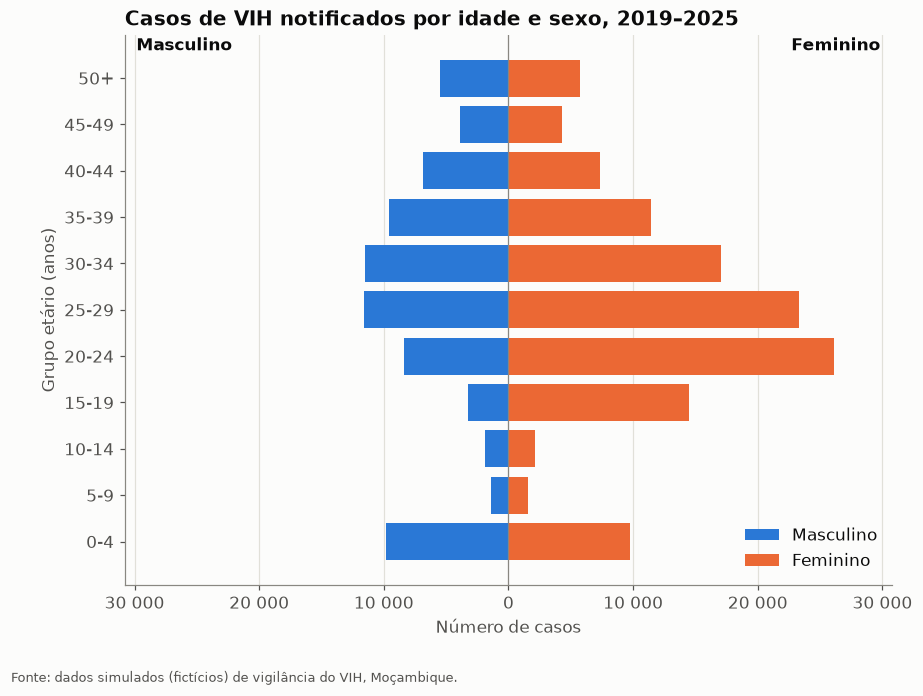

04:53:40 | INFO    |   → figura: 03_01_piramide_idade_sexo.png


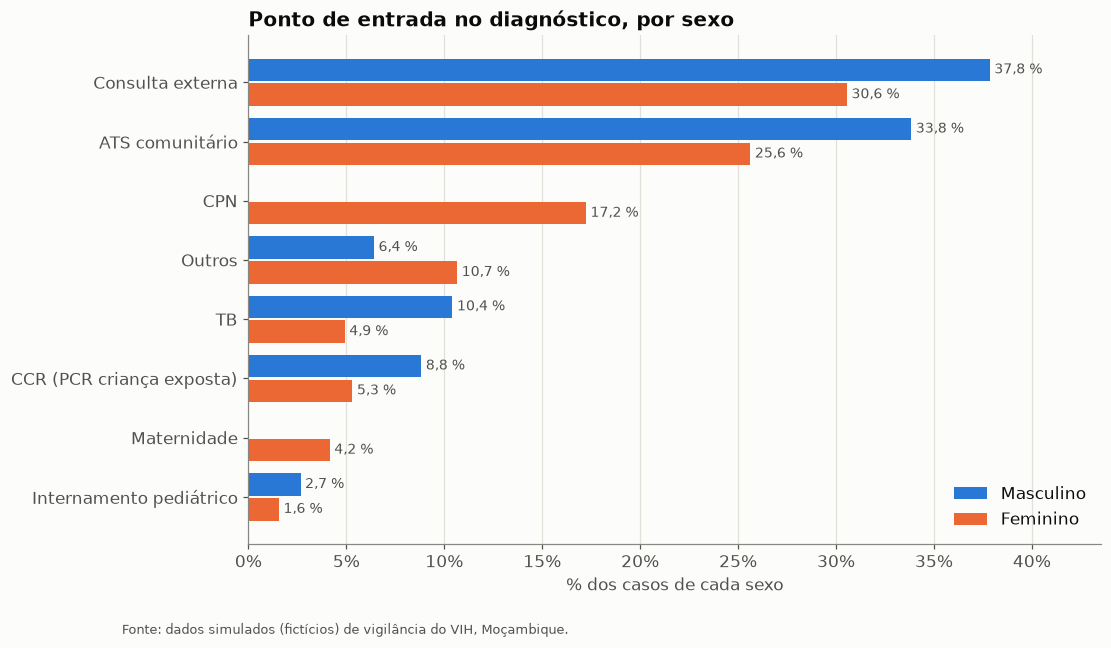

04:53:41 | INFO    |   → figura: 03_02_ponto_entrada_sexo.png


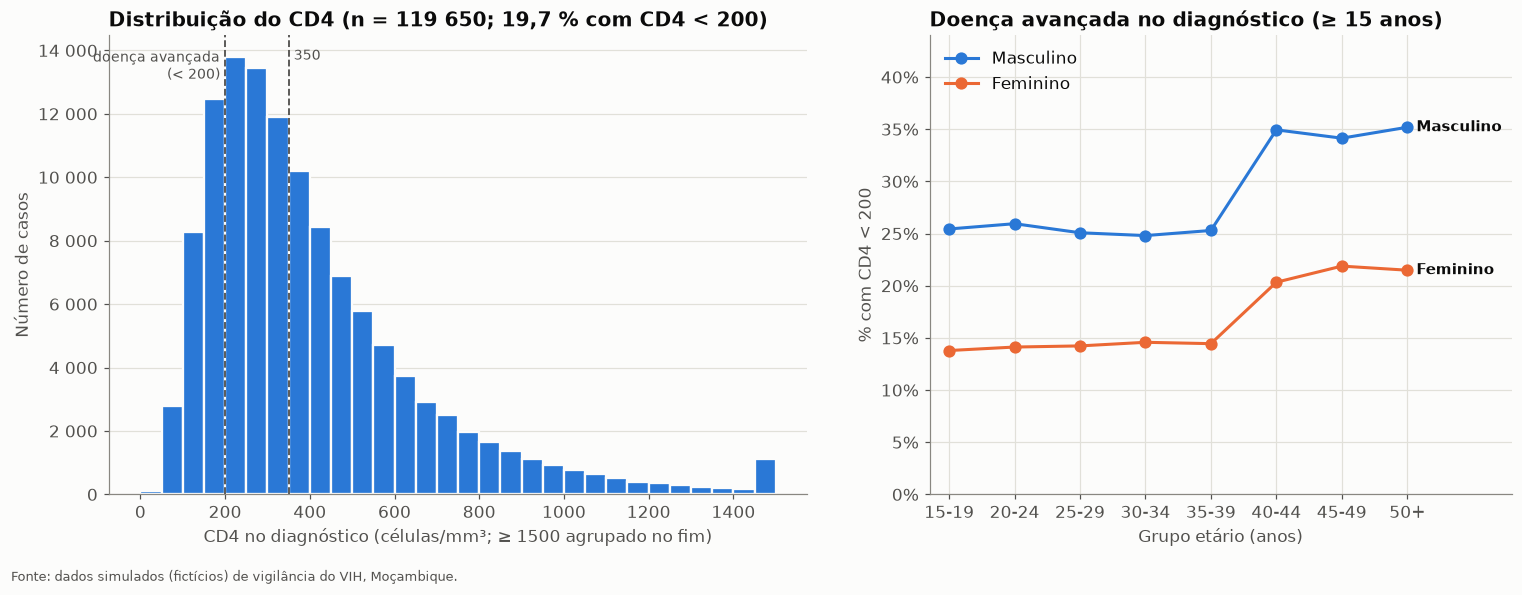

04:53:42 | INFO    |   → figura: 03_03_cd4_doenca_avancada.png
04:53:42 | INFO    | LUGAR
04:53:42 | INFO    |   → tabela: 03_casos_provincia_ano.csv


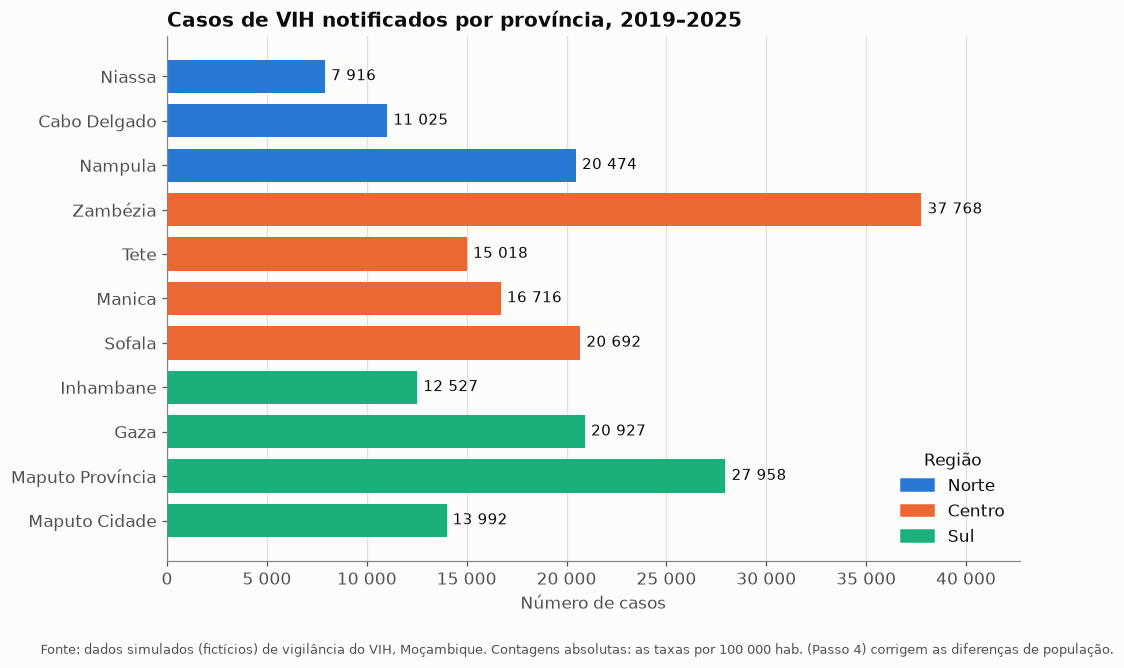

04:53:43 | INFO    |   → figura: 03_04_casos_provincia.png


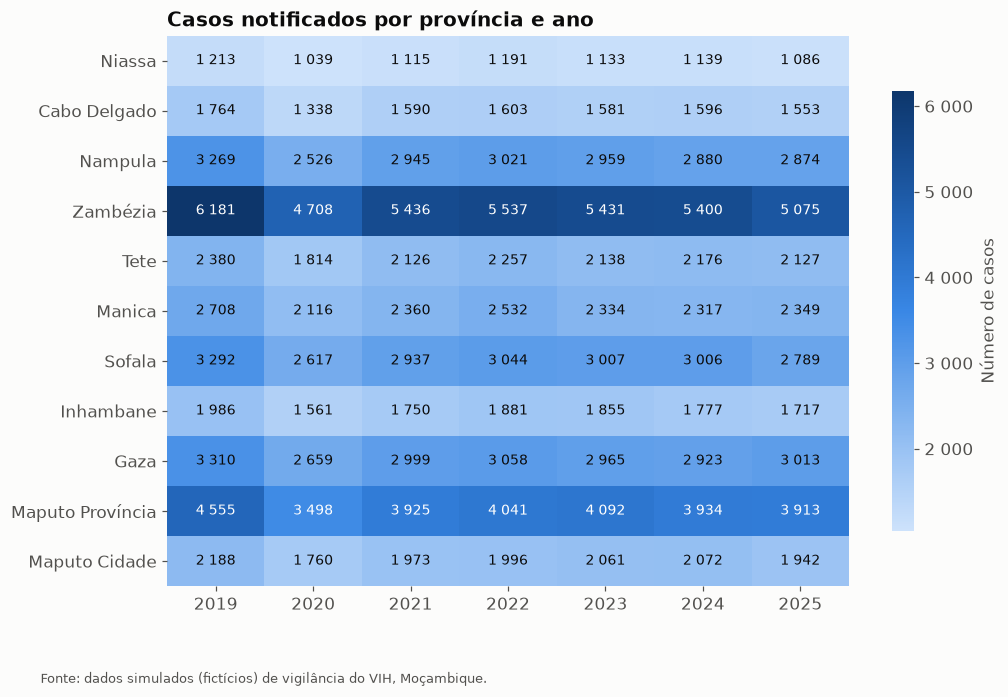

04:53:45 | INFO    |   → figura: 03_05_mapa_calor_provincia_ano.png
04:53:45 | INFO    | TEMPO


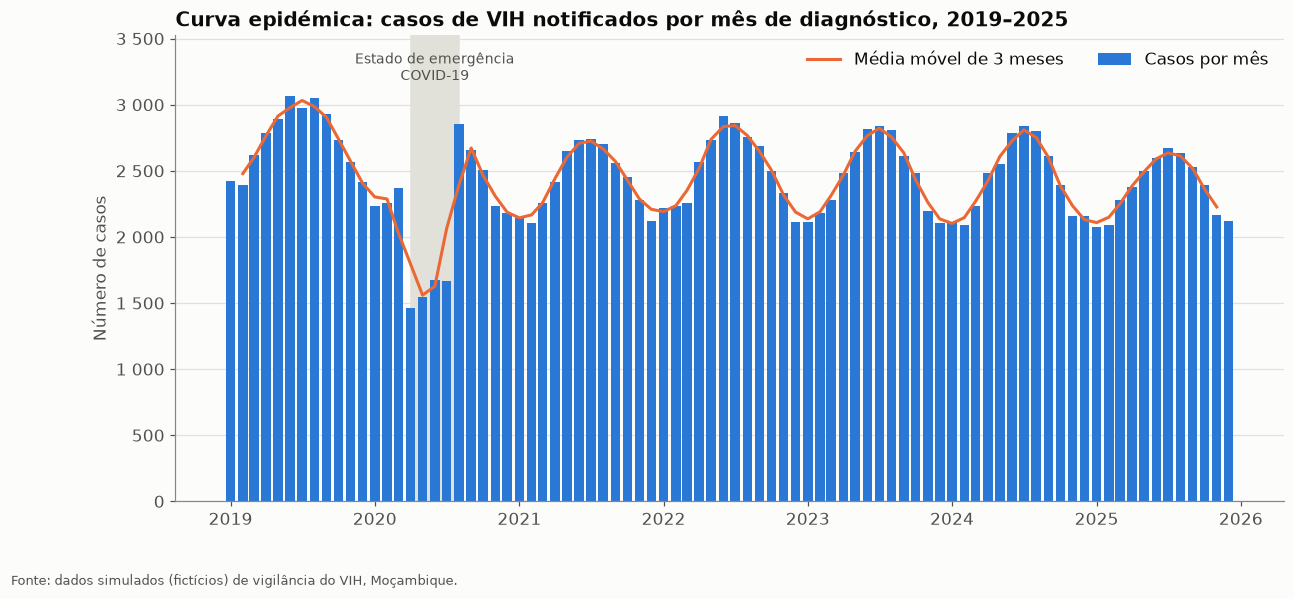

04:53:46 | INFO    |   → figura: 03_06_curva_epidemica_mensal.png
04:53:46 | INFO    |   → tabela: 03_casos_mensais.csv


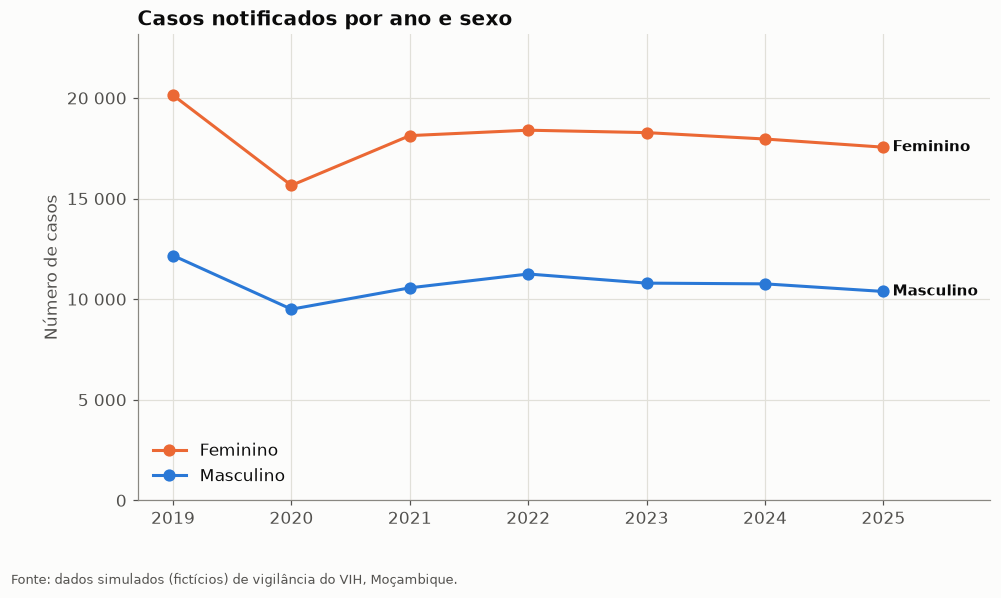

04:53:46 | INFO    |   → figura: 03_07_tendencia_anual_sexo.png
04:53:46 | INFO    |   Casos 2019: 32 302 → 2025: 27 932 (-13,5 %)
04:53:46 | INFO    |   Mês com menos casos: 04/2020 (1 459)
04:53:46 | INFO    | PTV
04:53:46 | INFO    |   → tabela: 03_ptv_cascata_anual.csv
04:53:46 | INFO    |   → tabela: 03_ptv_cascata_provincia_2025.csv
      %_cobertura_testagem  %_positividade  %_cobertura_tarv  %_cobertura_pcr_2meses  %_transmissao_vertical  relatorios_recebidos_%
ano                                                                                                                                 
2019                  93.0             8.2              84.8                    65.2                     4.4                    98.5
2020                  89.2             7.9              86.7                    68.3                     4.2                    95.5
2021                  89.9             7.8              88.7                    72.0                     3.9                   

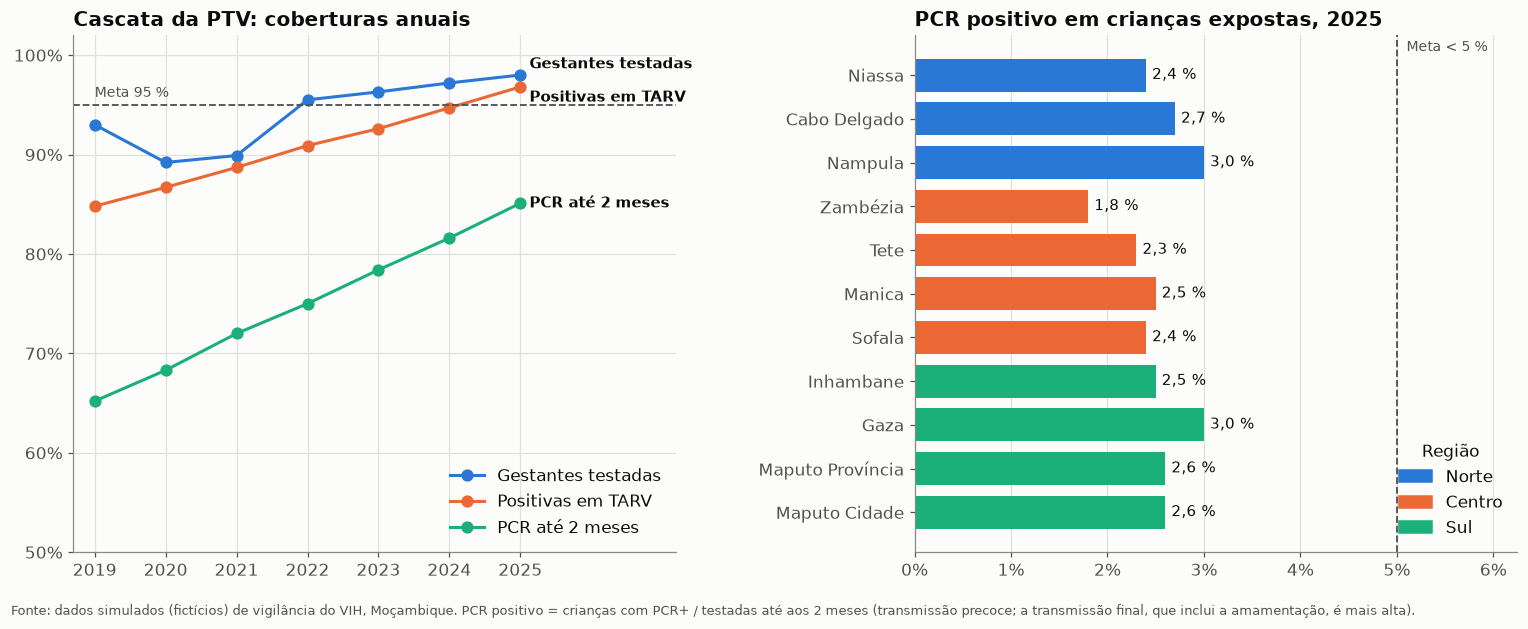

04:53:48 | INFO    |   → figura: 03_08_ptv_cascata.png
04:53:48 | INFO    | Passo 3 concluído.


In [28]:
dados["descritiva"] = passo3_descritiva(dados)

### Como interpretar

- **Os homens chegam mais tarde ao diagnóstico:** 27,7 % têm doença avançada (CD4 < 200), contra 15,2 % das
  mulheres, e a diferença cresce depois dos 40 anos.
- **Mulheres jovens:** dos 15 aos 24 anos há muito mais casos femininos do que masculinos.
- **COVID-19:** abril de 2020 foi o mês com menos diagnósticos.
- **Cuidado com a figura das províncias:** contagens absolutas — a Zambézia "lidera" só por ter mais população.

Tabela 1 (o Total inclui os casos sem sexo registado):

In [29]:
dados["descritiva"]["tabela_1"]

,Variável,Total,Masculino,Feminino
0,N,205 013,75 404,126 098
1,"Idade (anos), mediana [IIQ]",27 [20–36],30 [21–38],26 [20–34]
2,"CD4 no diagnóstico (células/mm³), mediana [IIQ]",337 [222–511],285 [190–430],369 [246–555]
3,"Atraso de notificação (dias), mediana [IIQ]",15 [7–23],15 [7–23],15 [7–23]
4,"Dias até início do TARV, mediana [IIQ]",5 [2–10],5 [2–10],5 [2–10]
5,"Faixa etária, n (%)",,,
6,Adulto (25+),"120 229 (60,0)","48 968 (66,4)","69 202 (56,2)"
7,Jovem (15-24),"52 974 (26,4)","11 579 (15,7)","40 602 (33,0)"
8,Criança (0-14),"27 136 (13,5)","13 157 (17,9)","13 408 (10,9)"
9,Em falta,4 674,1 700,2 886


---
## Passo 4 — Medidas epidemiológicas

**Taxa de notificação** (por 100 000 habitantes):

$$\text{taxa} = \frac{\text{casos}}{\text{pessoas-ano}} \times 100\,000$$

com **IC 95 % exato de Poisson** (método de Garwood), onde *d* = n.º de casos:

$$\text{IC}_{95\%} = \left[\tfrac{1}{2}\chi^2_{2d;\,0{,}025},\; \tfrac{1}{2}\chi^2_{2d+2;\,0{,}975}\right] \div \text{pessoas-ano} \times 100\,000$$

**Taxa padronizada por idade (método direto)** — *"qual seria a taxa se todas as províncias tivessem a mesma
estrutura etária?"*

$$\text{TP} = \sum_i w_i \, \frac{d_i}{n_i}, \qquad w_i = \text{peso do grupo etário } i \text{ na população-padrão}$$

- duas populações-padrão: **Moçambique 2019** (comparar províncias) e **OMS** (comparar com a literatura);
- IC 95 % de **Fay e Feuer** (aproximação gama, adequada para taxas ponderadas);
- casos sem idade são redistribuídos proporcionalmente.

**Proporções** (coberturas da PTV, % doença avançada…): IC 95 % de **Wilson**, bom mesmo com proporções pequenas.

> ✔ **Verificação automática:** no ano de referência (2019) a taxa padronizada tem de ser igual à bruta.

In [30]:
from scipy.stats import chi2
from statsmodels.stats.proportion import proportion_confint

ALFA = 1 - NIVEL_CONFIANCA

# População-padrão mundial da OMS (Ahmad et al., 2001), agregada aos nossos grupos.
# Pesos por 100 000; o grupo 50+ soma os grupos 50–54 até 100+.
PADRAO_OMS = pd.Series({
    "0-4": 8860, "5-9": 8690, "10-14": 8600, "15-19": 8470, "20-24": 8220,
    "25-29": 7930, "30-34": 7610, "35-39": 7150, "40-44": 6590, "45-49": 6040,
    "50+": 5370 + 4550 + 3720 + 2960 + 2210 + 1520 + 910 + 440 + 150 + 40 + 5,
}, name="peso")

### 4.1 Intervalos de confiança

In [31]:
def ic_poisson(casos, pessoas_ano, por=POR_HABITANTES):
    """IC exato de Poisson para uma taxa (funciona também com 0 casos)."""
    casos = np.asarray(casos, dtype=float)
    pessoas_ano = np.asarray(pessoas_ano, dtype=float)
    inf = np.where(casos == 0, 0, chi2.ppf(ALFA / 2, 2 * casos) / 2)
    sup = chi2.ppf(1 - ALFA / 2, 2 * casos + 2) / 2
    return inf / pessoas_ano * por, sup / pessoas_ano * por


def ic_proporcao(numerador, denominador):
    """Proporção (%) com IC 95 % de Wilson – bom mesmo com proporções pequenas."""
    numerador = np.asarray(numerador, dtype=float)
    denominador = np.asarray(denominador, dtype=float)
    inf, sup = proportion_confint(numerador, denominador, alpha=ALFA, method="wilson")
    return numerador / denominador * 100, inf * 100, sup * 100


def taxa_padronizada_fay_feuer(casos, populacao, pesos):
    """Taxa padronizada (método direto) + IC de Fay & Feuer (1997), por 100 000."""
    casos = np.asarray(casos, dtype=float)
    populacao = np.asarray(populacao, dtype=float)
    pesos = np.asarray(pesos, dtype=float) / np.sum(pesos)
    wi = pesos / populacao
    taxa = np.sum(wi * casos)
    var = np.sum(wi ** 2 * casos)
    wm = wi.max()
    inf = 0.0 if taxa == 0 else var / (2 * taxa) * chi2.ppf(ALFA / 2, 2 * taxa ** 2 / var)
    sup = (var + wm ** 2) / (2 * (taxa + wm)) * chi2.ppf(1 - ALFA / 2, 2 * (taxa + wm) ** 2 / (var + wm ** 2))
    return taxa * POR_HABITANTES, inf * POR_HABITANTES, sup * POR_HABITANTES

### 4.2 Taxas brutas e específicas

In [32]:
def _com_texto(df: pd.DataFrame, colunas) -> pd.DataFrame:
    """Converte categorias em texto para os 'joins' entre casos e população."""
    df = df.copy()
    for c in colunas:
        if c in df:
            df[c] = df[c].astype(str).where(df[c].notna())
    return df


def calcular_taxas(casos: pd.DataFrame, pop: pd.DataFrame, por: list[str]) -> pd.DataFrame:
    """Casos, pessoas-ano, taxa por 100 000 e IC 95 % para cada estrato de `por`."""
    c = _com_texto(casos, por)
    p = _com_texto(pop, por)
    sem_info = c[por].isna().any(axis=1)
    if sem_info.any():
        log.info(f"    taxas por {por}: {fmt_int(sem_info.sum())} casos "
                 f"({fmt_dec(sem_info.mean() * 100)} %) sem {'/'.join(por)} ficam de fora")
    n = c.loc[~sem_info].groupby(por).size().rename("casos")
    pa = p.groupby(por)["populacao"].sum().rename("pessoas_ano")
    df = pd.concat([n, pa], axis=1)
    df["casos"] = df["casos"].fillna(0).astype(int)
    df["taxa"] = df["casos"] / df["pessoas_ano"] * POR_HABITANTES
    df["ic_inf"], df["ic_sup"] = ic_poisson(df["casos"], df["pessoas_ano"])
    return df.round({"taxa": 1, "ic_inf": 1, "ic_sup": 1})

### 4.3 Taxas padronizadas por idade

In [33]:
def calcular_padronizadas(casos: pd.DataFrame, pop: pd.DataFrame, por: list[str],
                          padrao: pd.Series, sufixo: str) -> pd.DataFrame:
    """Taxa padronizada por idade para cada estrato de `por`.
    Casos sem idade são redistribuídos proporcionalmente (fator de correção)."""
    c = _com_texto(casos, por + ["grupo_etario"]).dropna(subset=por)
    p = _com_texto(pop, por + ["grupo_etario"])
    linhas = []
    for chave, pop_estrato in p.groupby(por):
        chave = chave if isinstance(chave, tuple) else (chave,)
        filtro = np.logical_and.reduce([c[col] == val for col, val in zip(por, chave)])
        casos_estrato = c.loc[filtro]
        com_idade = casos_estrato["grupo_etario"].notna().sum()
        fator = len(casos_estrato) / com_idade if com_idade else 1.0
        tabela = (pop_estrato.groupby("grupo_etario")["populacao"].sum().to_frame()
                  .join(casos_estrato.groupby("grupo_etario").size().rename("casos"))
                  .fillna(0).reindex(GRUPOS_ETARIOS))
        taxa, inf, sup = taxa_padronizada_fay_feuer(tabela["casos"], tabela["populacao"],
                                                    padrao.reindex(GRUPOS_ETARIOS))
        linhas.append(dict(zip(por, chave)) | {f"taxa_padr_{sufixo}": taxa * fator,
                                                f"ic_inf_{sufixo}": inf * fator,
                                                f"ic_sup_{sufixo}": sup * fator})
    return pd.DataFrame(linhas).set_index(por).round(1)

### 4.4 Indicadores da PTV e indicadores programáticos com IC

In [34]:
def indicadores_ptv_ic(ptv: pd.DataFrame, por: str) -> pd.DataFrame:
    linhas = []
    for nome, (num, den) in INDICADORES_PTV.items():
        ok = ptv[num].notna() & ptv[den].notna()
        soma = ptv.loc[ok].groupby(por)[[num, den]].sum()
        pct, inf, sup = ic_proporcao(soma[num], soma[den])
        linhas.append(pd.DataFrame({por: soma.index, "indicador": nome,
                                    "numerador": soma[num].to_numpy(),
                                    "denominador": soma[den].to_numpy(),
                                    "%": pct, "ic_inf": inf, "ic_sup": sup}))
    return pd.concat(linhas, ignore_index=True).round({"%": 1, "ic_inf": 1, "ic_sup": 1})


def indicadores_programaticos(casos: pd.DataFrame) -> pd.DataFrame:
    """Indicadores anuais da cascata de cuidados, com IC 95 %."""
    defs = {
        "doenca_avancada_cd4_menor_200": "doenca_avancada",
        "iniciou_tarv": "iniciou_tarv",
        "tarv_ate_7_dias": "tarv_ate_7_dias",
    }
    linhas = []
    for nome, col in defs.items():
        g = casos.dropna(subset=[col]).groupby("ano")[col].agg(numerador="sum", denominador="size")
        pct, inf, sup = ic_proporcao(g["numerador"], g["denominador"])
        linhas.append(g.assign(indicador=nome, **{"%": pct, "ic_inf": inf, "ic_sup": sup}).reset_index())
    return (pd.concat(linhas, ignore_index=True)
            [["ano", "indicador", "numerador", "denominador", "%", "ic_inf", "ic_sup"]]
            .round({"%": 1, "ic_inf": 1, "ic_sup": 1}))

### 4.5 Gráficos

In [35]:
def _barras_erro(ax, y, valor, inf, sup, cor, rotulo, marcador="o"):
    ax.errorbar(valor, y, xerr=[valor - inf, sup - valor], fmt=marcador, ms=7, color=cor,
                ecolor=cor, elinewidth=1.6, capsize=3, label=rotulo)


def fig_taxas_provincia(tab: pd.DataFrame, taxa_nacional: float) -> None:
    tab = tab.sort_values("taxa_padr_moz")          # a maior fica em cima
    y = np.arange(len(tab))
    fig, ax = plt.subplots(figsize=(10.5, 6.5))
    _barras_erro(ax, y + 0.17, tab["taxa"], tab["ic_inf"], tab["ic_sup"], CORES["principal"], "Taxa bruta")
    _barras_erro(ax, y - 0.17, tab["taxa_padr_moz"], tab["ic_inf_moz"], tab["ic_sup_moz"],
                 CORES["secundaria"], f"Padronizada por idade (Moçambique {ANO_REFERENCIA_PADRONIZACAO})", "D")
    ax.axvline(taxa_nacional, color=CORES["meta"], ls="--", lw=1.2)
    ax.text(taxa_nacional, -0.85, f" Moçambique (bruta): {fmt_dec(taxa_nacional)}",
            fontsize=9, color=CORES["texto_secundario"])
    ax.set_yticks(y, tab.index)
    ax.set_ylim(-1.1, len(tab) - 0.4)
    ax.set_xlim(0, tab[["ic_sup", "ic_sup_moz"]].to_numpy().max() * 1.12)
    ax.grid(axis="y", visible=False)
    ax.legend(loc="center right")
    ax.set_xlabel("Casos notificados por 100 000 habitantes por ano (IC 95 %)")
    ax.set_title(f"Taxa de notificação de VIH por província, {ANO_INICIO}–{ANO_FIM}")
    guardar_figura(fig, "04_01_taxas_provincia",
                   FONTE + " Taxas sobre pessoas-ano do período; províncias ordenadas pela taxa padronizada.")


def fig_taxas_idade_sexo(tab: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(11, 5.8))
    x = np.arange(len(GRUPOS_ETARIOS))
    finais = {s: tab.loc[(GRUPOS_ETARIOS[-1], s), "taxa"] for s in ["F", "M"]}
    for sexo in ["F", "M"]:
        t = tab.xs(sexo, level="sexo").reindex(GRUPOS_ETARIOS)
        ax.fill_between(x, t["ic_inf"], t["ic_sup"], color=CORES[sexo], alpha=0.18, lw=0)
        ax.plot(x, t["taxa"], marker="o", ms=7, color=CORES[sexo], label=SEXO_ROTULO[sexo])
        perto = abs(finais["F"] - finais["M"]) < tab["taxa"].max() * 0.05
        dy = 0 if not perto else (7 if finais[sexo] >= max(finais.values()) else -7)
        rotular_fim_linha(ax, x[-1], t["taxa"].iloc[-1], SEXO_ROTULO[sexo], CORES[sexo], dy=dy)
    ax.set_xticks(x, GRUPOS_ETARIOS)
    ax.set_xlim(-0.3, len(x) + 0.5)
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(EIXO_MILHARES)
    ax.legend(loc="upper right")
    ax.set_xlabel("Grupo etário (anos)")
    ax.set_ylabel("Casos por 100 000 hab./ano")
    ax.set_title(f"Taxa de notificação por idade e sexo, {ANO_INICIO}–{ANO_FIM} (IC 95 % sombreado)")
    guardar_figura(fig, "04_02_taxas_idade_sexo")


def fig_tendencia_taxas(nacional: pd.DataFrame, por_sexo: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(10.5, 5.8))
    anos = nacional.index.astype(int)
    series = [("F", por_sexo.xs("F", level="sexo"), CORES["F"], "-", "Feminino"),
              ("M", por_sexo.xs("M", level="sexo"), CORES["M"], "-", "Masculino"),
              ("T", nacional, CORES["texto_secundario"], "--", "Total")]
    for _, t, cor, estilo, rotulo in series:
        ax.fill_between(anos, t["ic_inf"], t["ic_sup"], color=cor, alpha=0.15, lw=0)
        ax.plot(anos, t["taxa"], ls=estilo, marker="o", ms=7, color=cor, label=rotulo)
        rotular_fim_linha(ax, anos[-1], t["taxa"].iloc[-1], rotulo, cor)
    ax.set_xticks(anos)
    ax.set_xlim(anos[0] - 0.3, anos[-1] + 0.9)
    ax.set_ylim(0, None)
    ax.legend(loc="lower left", ncols=3)
    ax.set_ylabel("Casos por 100 000 hab.")
    ax.set_title("Tendência da taxa de notificação de VIH, por sexo (IC 95 % sombreado)")
    guardar_figura(fig, "04_03_tendencia_taxas")


def fig_transmissao_ic(ind_prov: pd.DataFrame, valor_nacional: float) -> None:
    t = (ind_prov[ind_prov["indicador"] == "transmissao_vertical"]
         .set_index("provincia").reindex(ORDEM_PROVINCIAS[::-1]))
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(10, 6))
    for regiao in ["Norte", "Centro", "Sul"]:
        m = (t.index.map(PROVINCIAS) == regiao)
        _barras_erro(ax, y[m], t["%"][m], t["ic_inf"][m], t["ic_sup"][m], CORES[regiao], regiao)
    ax.axvline(META_TRANSMISSAO_VERTICAL * 100, color=CORES["meta"], ls="--", lw=1.2)
    ax.text(META_TRANSMISSAO_VERTICAL * 100, len(t) - 0.35, " Meta < 5 %", fontsize=9,
            color=CORES["texto_secundario"])
    ax.axvline(valor_nacional, color=CORES["eixos"], ls=":", lw=1.2)
    ax.text(valor_nacional, -0.9, f" Nacional: {fmt_dec(valor_nacional)} %", fontsize=9,
            color=CORES["texto_secundario"])
    ax.set_yticks(y, t.index)
    ax.set_ylim(-1.2, len(t) - 0.1)
    ax.set_xlim(0, max(t["ic_sup"].max(), META_TRANSMISSAO_VERTICAL * 100) * 1.15)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis="y", visible=False)
    ax.legend(title="Região", loc="lower left")
    ax.set_xlabel("% de crianças expostas com PCR positivo até aos 2 meses (IC 95 %)")
    ax.set_title(f"Transmissão vertical precoce por província, {ANO_FIM}")
    guardar_figura(fig, "04_04_transmissao_vertical_ic")

### 4.6 Função principal do Passo 4

In [36]:
def passo4_medidas(dados: dict) -> dict:
    log.info("=" * 70)
    log.info("PASSO 4 — MEDIDAS EPIDEMIOLÓGICAS")
    log.info("=" * 70)
    casos, pop, ptv = dados["casos"], dados["populacao"], dados["ptv"]
    padrao_moz = (pop[pop["ano"] == ANO_REFERENCIA_PADRONIZACAO]
                  .groupby("grupo_etario", observed=True)["populacao"].sum())
    padrao_moz.index = padrao_moz.index.astype(str)
    res = {}

    # a) Nacional por ano e por sexo
    log.info("Taxas brutas por ano")
    nacional = calcular_taxas(casos, pop, ["ano"])
    nacional.index = nacional.index.astype(int)
    padr_ano = calcular_padronizadas(casos, pop, ["ano"], padrao_moz, "moz")
    padr_ano.index = padr_ano.index.astype(int)
    nacional = nacional.join(padr_ano)
    por_sexo = calcular_taxas(casos, pop, ["ano", "sexo"])
    por_sexo.index = por_sexo.index.set_levels(por_sexo.index.levels[0].astype(int), level=0)
    print(nacional.to_string(), "\n")
    # Verificação: no ano de referência, taxa padronizada ≈ taxa bruta (mesma população)
    ref = nacional.loc[ANO_REFERENCIA_PADRONIZACAO]
    log.info(f"  Verificação {ANO_REFERENCIA_PADRONIZACAO}: bruta {fmt_dec(ref['taxa'])} vs. "
             f"padronizada {fmt_dec(ref['taxa_padr_moz'])} (devem ser quase iguais)")
    guardar_tabela(nacional.reset_index(), "04_taxas_nacionais_ano")
    guardar_tabela(por_sexo.reset_index(), "04_taxas_ano_sexo")

    # b) Por província (período completo = pessoas-ano somadas)
    log.info("Taxas por província (bruta e padronizada)")
    prov = (calcular_taxas(casos, pop, ["provincia"])
            .join(calcular_padronizadas(casos, pop, ["provincia"], padrao_moz, "moz"))
            .join(calcular_padronizadas(casos, pop, ["provincia"], PADRAO_OMS, "oms"))
            .reindex(ORDEM_PROVINCIAS))
    prov.insert(0, "regiao", prov.index.map(PROVINCIAS))
    prov["posicao_bruta"] = prov["taxa"].rank(ascending=False, method="min").astype(int)
    prov["posicao_padronizada"] = prov["taxa_padr_moz"].rank(ascending=False, method="min").astype(int)
    c_pais, p_pais = casos.assign(pais="Moçambique"), pop.assign(pais="Moçambique")
    nac = (calcular_taxas(c_pais, p_pais, ["pais"])
           .join(calcular_padronizadas(c_pais, p_pais, ["pais"], padrao_moz, "moz"))
           .join(calcular_padronizadas(c_pais, p_pais, ["pais"], PADRAO_OMS, "oms")))
    prov.loc["Moçambique"] = nac.iloc[0].reindex(prov.columns)
    prov.loc["Moçambique", "regiao"] = "—"
    prov = prov.astype({"casos": int, "pessoas_ano": int,
                        "posicao_bruta": "Int64", "posicao_padronizada": "Int64"})
    print(prov[["casos", "taxa", "ic_inf", "ic_sup", "taxa_padr_moz", "taxa_padr_oms",
                "posicao_bruta", "posicao_padronizada"]].to_string(), "\n")
    guardar_tabela(prov.reset_index(), "04_taxas_provincia")
    mudou = prov.dropna(subset=["posicao_bruta"]).query("posicao_bruta != posicao_padronizada")
    if len(mudou):
        log.info(f"  A padronização mudou a posição no ranking de: {', '.join(mudou.index)}")

    prov_ano = calcular_taxas(casos, pop, ["provincia", "ano"]).join(
        calcular_padronizadas(casos, pop, ["provincia", "ano"], padrao_moz, "moz"))
    guardar_tabela(prov_ano.reset_index(), "04_taxas_provincia_ano")

    # c) Por idade e sexo
    log.info("Taxas específicas por idade e sexo")
    idade_sexo = calcular_taxas(casos, pop, ["grupo_etario", "sexo"])
    guardar_tabela(idade_sexo.reset_index(), "04_taxas_idade_sexo")
    f2024 = idade_sexo.loc[("20-24", "F"), "taxa"]
    m2024 = idade_sexo.loc[("20-24", "M"), "taxa"]
    log.info(f"  20–24 anos: mulheres {fmt_dec(f2024)} vs. homens {fmt_dec(m2024)} por 100 000 "
             f"(razão F/M = {fmt_dec(f2024 / m2024, 2)})")

    # d) PTV e indicadores programáticos com IC
    log.info("Indicadores com IC 95 % (Wilson)")
    ptv_ano = indicadores_ptv_ic(ptv, "ano")
    ptv_prov = indicadores_ptv_ic(ptv[ptv["ano"] == ANO_FIM], "provincia")
    prog = indicadores_programaticos(casos)
    guardar_tabela(ptv_ano, "04_indicadores_ptv_ano_ic")
    guardar_tabela(ptv_prov, f"04_indicadores_ptv_provincia_{ANO_FIM}_ic")
    guardar_tabela(prog, "04_indicadores_programaticos_ic")
    tv = ptv_ano[(ptv_ano["indicador"] == "transmissao_vertical") & (ptv_ano["ano"] == ANO_FIM)].iloc[0]
    log.info(f"  Transmissão vertical precoce {ANO_FIM}: {fmt_dec(tv['%'])} % "
             f"(IC 95 %: {fmt_dec(tv['ic_inf'])}–{fmt_dec(tv['ic_sup'])})")

    # e) Gráficos
    fig_taxas_provincia(prov.drop(index="Moçambique"), prov.loc["Moçambique", "taxa"])
    fig_taxas_idade_sexo(idade_sexo)
    fig_tendencia_taxas(nacional, por_sexo)
    fig_transmissao_ic(ptv_prov, tv["%"])

    log.info("Passo 4 concluído.")
    res |= {"nacional": nacional, "por_sexo": por_sexo, "provincia": prov, "provincia_ano": prov_ano,
            "idade_sexo": idade_sexo, "ptv_ano": ptv_ano, "ptv_provincia": ptv_prov,
            "programaticos": prog}
    return res

### Executar o Passo 4

04:53:50 | INFO    | ======================================================================
04:53:50 | INFO    | PASSO 4 — MEDIDAS EPIDEMIOLÓGICAS
04:53:50 | INFO    | ======================================================================
04:53:50 | INFO    | Taxas brutas por ano
04:53:50 | INFO    |     taxas por ['ano', 'sexo']: 3 511 casos (1,7 %) sem ano/sexo ficam de fora
      casos  pessoas_ano   taxa  ic_inf  ic_sup  taxa_padr_moz  ic_inf_moz  ic_sup_moz
ano                                                                                   
2019  32846     28799997  114.0   112.8   115.3          114.0       112.8       115.3
2020  25636     29606398   86.6    85.5    87.7           86.6        85.5        87.7
2021  29156     30435372   95.8    94.7    96.9           95.8        94.7        96.9
2022  30161     31287563   96.4    95.3    97.5           96.4        95.3        97.5
2023  29556     32163619   91.9    90.8    92.9           91.9        90.8        93.0
2024  29220

C:\Users\User\AppData\Local\Temp\ipykernel_16932\1443832540.py:48: RuntimeWarning: Engine has switched to 'python' because numexpr does not support extension array dtypes. Please set your engine to python manually.
  mudou = prov.dropna(subset=["posicao_bruta"]).query("posicao_bruta != posicao_padronizada")


04:53:53 | INFO    |   → tabela: 04_taxas_provincia_ano.csv
04:53:53 | INFO    | Taxas específicas por idade e sexo
04:53:53 | INFO    |     taxas por ['grupo_etario', 'sexo']: 8 097 casos (3,9 %) sem grupo_etario/sexo ficam de fora
04:53:53 | INFO    |   → tabela: 04_taxas_idade_sexo.csv
04:53:53 | INFO    |   20–24 anos: mulheres 241,5 vs. homens 83,7 por 100 000 (razão F/M = 2,89)
04:53:53 | INFO    | Indicadores com IC 95 % (Wilson)
04:53:53 | INFO    |   → tabela: 04_indicadores_ptv_ano_ic.csv
04:53:53 | INFO    |   → tabela: 04_indicadores_ptv_provincia_2025_ic.csv
04:53:53 | INFO    |   → tabela: 04_indicadores_programaticos_ic.csv
04:53:53 | INFO    |   Transmissão vertical precoce 2025: 2,5 % (IC 95 %: 2,4–2,6)


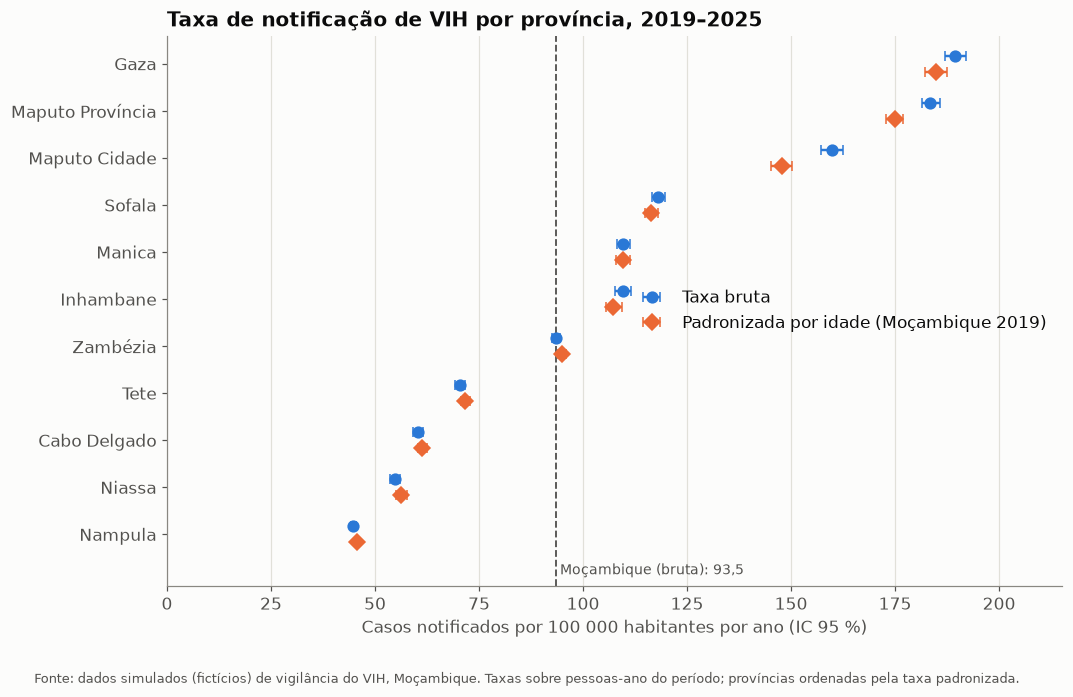

04:53:54 | INFO    |   → figura: 04_01_taxas_provincia.png


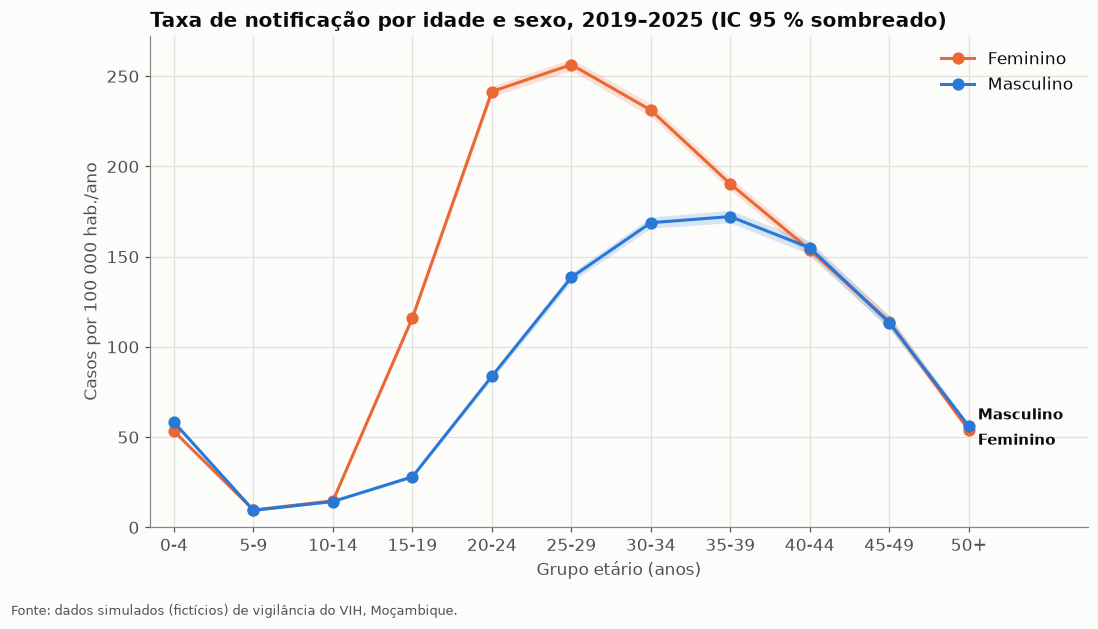

04:53:55 | INFO    |   → figura: 04_02_taxas_idade_sexo.png


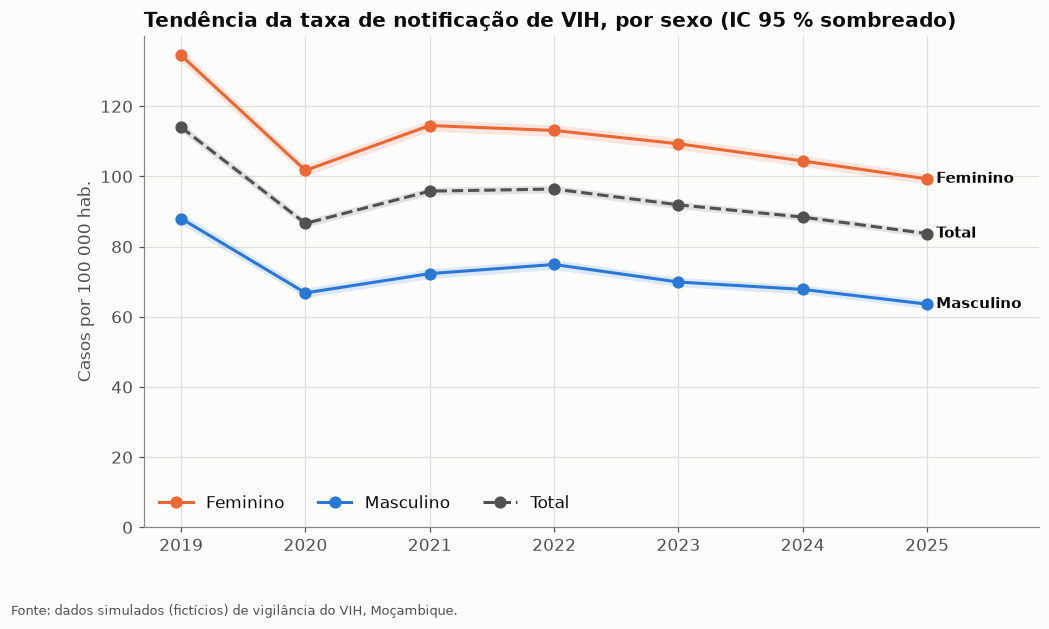

04:53:55 | INFO    |   → figura: 04_03_tendencia_taxas.png


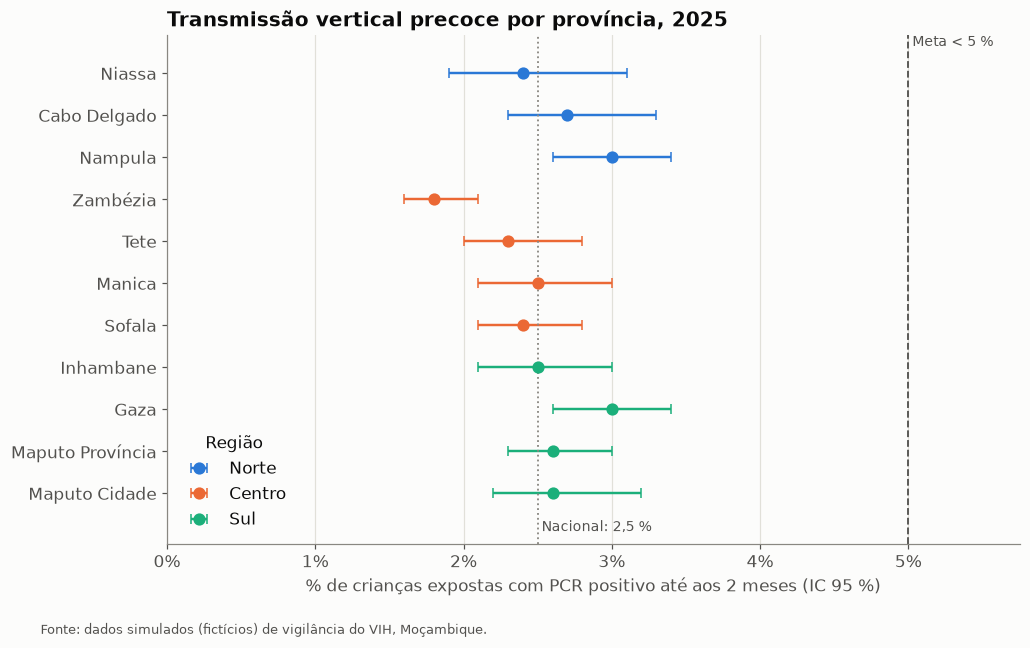

04:53:56 | INFO    |   → figura: 04_04_transmissao_vertical_ic.png
04:53:56 | INFO    | Passo 4 concluído.


In [37]:
dados["medidas"] = passo4_medidas(dados)

### Como interpretar

- **A padronização importa:** Maputo Cidade passa de 159,8 (bruta) para **147,7** por 100 000 (padronizada),
  porque tem mais adultos do que a média do país. As províncias do Norte, mais jovens, sobem ligeiramente.
- **Gaza** tem a taxa padronizada mais alta e **Nampula** a mais baixa.
- **Mulheres 20–24 anos:** taxa ≈ 2,9 vezes a dos homens da mesma idade.
- **Transmissão vertical precoce 2025:** 2,5 % (IC 95 %: 2,4–2,6), abaixo da meta de 5 % em todas as províncias.

Taxas por província (bruta e padronizada):

In [38]:
dados["medidas"]["provincia"][["casos", "taxa", "ic_inf", "ic_sup", "taxa_padr_moz", "taxa_padr_oms"]]

,casos,taxa,ic_inf,ic_sup,taxa_padr_moz,taxa_padr_oms
provincia,,,,,,
Niassa,7916,54.7,53.5,55.9,56.3,62.6
Cabo Delgado,11025,60.3,59.2,61.5,61.4,67.8
Nampula,20474,44.8,44.2,45.4,45.7,50.8
Zambézia,37768,93.6,92.6,94.5,94.9,106.2
Tete,15018,70.4,69.3,71.6,71.7,79.7
Manica,16716,109.7,108.1,111.4,109.5,121.9
Sofala,20692,118.1,116.5,119.7,116.4,129.1
Inhambane,12527,109.7,107.7,111.6,107.3,118.5
Gaza,20927,189.5,186.9,192.1,184.8,202.3


---
## Passo 5 — Análise de associação

### A) Regressão de Poisson (taxas, ≥ 15 anos)

$$\log(\mu) = \underbrace{\log(\text{população})}_{\text{offset}} + \beta_0 + \beta_1 X_1 + \dots
\qquad\Rightarrow\qquad \text{RR} = e^{\beta}$$

- Crianças < 15 anos ficam de fora: infetam-se sobretudo por **transmissão vertical** (outro mecanismo).
- **Sobredispersão:** se a dispersão (χ² de Pearson / gl) for > 1,5, usa-se a binomial negativa.
- **Interação sexo × idade** (modificação de efeito), testada pela **razão de verosimilhanças**.

> 💡 **Lição aprendida:** o modelo só com efeitos principais tinha dispersão **7,6** — parecia sobredispersão.
> Com a interação sexo × idade desceu para **1,05**. Faltava um termo no modelo! Por isso a dispersão é
> verificada no modelo **final**.

### B) Regressão logística (doença avançada = CD4 < 200, ≥ 15 anos)

$$\text{logit}(p) = \beta_0 + \beta X \qquad\Rightarrow\qquad \text{OR} = e^{\beta}$$

Comparamos **OR brutos** (uma variável de cada vez) com **OR ajustados** (todas juntas): quando mudam muito,
há **confundimento**.

In [39]:
import warnings
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy.stats import norm

Z = norm.ppf(1 - ALFA / 2)

# Categorias de referência (a primeira de cada lista é a referência)
REFERENCIAS = {
    "sexo": "M",                    # RR/OR das mulheres em relação aos homens
    "grupo_etario": "25-29",
    "provincia": "Nampula",         # província com a taxa mais baixa
    "ano": 2019,
    "idade_cat": "15-24",
    "ponto_entrada": "ATS comunitário",
    "regiao": "Sul",
}
NOMES_VARIAVEIS = {
    "sexo": "Sexo", "grupo_etario": "Grupo etário", "provincia": "Província",
    "ano": "Ano", "idade_cat": "Idade (anos)", "ponto_entrada": "Ponto de entrada",
    "regiao": "Região", "sexo_idade": "Mulheres vs. homens, por idade",
}
LIMIAR_SOBREDISPERSAO = 1.5

### 5.1 Funções de apoio

In [40]:
def fmt_p(p: float) -> str:
    return "<0,001" if p < 0.001 else fmt_dec(p, 3)


def preparar_categorias(df: pd.DataFrame, variaveis: list[str]) -> pd.DataFrame:
    """Converte em categorias com a referência em primeiro lugar."""
    df = df.copy()
    ordens = {"grupo_etario": GRUPOS_ETARIOS, "provincia": ORDEM_PROVINCIAS,
              "regiao": ["Norte", "Centro", "Sul"]}
    for v in variaveis:
        presentes = list(pd.unique(df[v].dropna()))
        ordem = [c for c in ordens.get(v, sorted(presentes, key=str)) if c in presentes]
        ref = REFERENCIAS[v]
        df[v] = pd.Categorical(df[v], categories=[ref] + [c for c in ordem if c != ref])
    return df


def rotulo_categoria(variavel: str, categoria) -> str:
    return SEXO_ROTULO.get(categoria, str(categoria)) if variavel == "sexo" else str(categoria)


def tabela_efeitos(resultado, variaveis: list[str], df: pd.DataFrame, nome: str) -> pd.DataFrame:
    """Transforma os coeficientes em RR/OR com IC 95 % (inclui as linhas de referência)."""
    params, ic, pv = resultado.params, resultado.conf_int(alpha=ALFA), resultado.pvalues
    linhas = []
    for v in variaveis:
        for k, cat in enumerate(df[v].cat.categories):
            termo = f"C({v})[T.{cat}]"
            if k == 0:
                linhas.append({"variavel": v, "categoria": cat, nome: 1.0,
                               "ic_inf": np.nan, "ic_sup": np.nan, "p": np.nan, "referencia": True})
            elif termo in params.index:
                linhas.append({"variavel": v, "categoria": cat, nome: np.exp(params[termo]),
                               "ic_inf": np.exp(ic.loc[termo, 0]), "ic_sup": np.exp(ic.loc[termo, 1]),
                               "p": pv[termo], "referencia": False})
    return pd.DataFrame(linhas)


def ajustar_glm_contagens(formula: str, dados: pd.DataFrame):
    """Poisson com offset; se houver sobredispersão, passa para binomial negativa."""
    poisson = smf.glm(formula, dados, family=sm.families.Poisson(),
                      offset=dados["log_pop"]).fit()
    dispersao = poisson.pearson_chi2 / poisson.df_resid
    if dispersao <= LIMIAR_SOBREDISPERSAO:
        return poisson, "Poisson", dispersao
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        nb = smf.negativebinomial(formula, dados, offset=dados["log_pop"]).fit(disp=0, maxiter=200)
    return nb, "Binomial negativa", dispersao

### 5.2 Regressão de Poisson

In [41]:
def dados_poisson(casos: pd.DataFrame, pop: pd.DataFrame, idade_min: int = 15) -> pd.DataFrame:
    por = ["provincia", "ano", "sexo", "grupo_etario"]
    c = _com_texto(casos, por).dropna(subset=por).groupby(por).size().rename("casos")
    p = _com_texto(pop, por).groupby(por)["populacao"].sum()
    df = pd.concat([c, p], axis=1).fillna({"casos": 0}).reset_index()
    grupos = [g for g, lim in zip(GRUPOS_ETARIOS, LIMITES_IDADE) if lim >= idade_min]
    df = df[df["grupo_etario"].isin(grupos)].copy()
    df["ano"] = df["ano"].astype(int)
    df["casos"] = df["casos"].astype(int)
    df["log_pop"] = np.log(df["populacao"])
    return preparar_categorias(df, por)


def rr_sexo_por_idade(resultado, df: pd.DataFrame) -> pd.DataFrame:
    """No modelo com interação: RR mulheres/homens em cada grupo etário.
    RR(F vs M | idade g) = exp(β_F + β_F×g)  → combinação linear dos coeficientes."""
    params, cov = resultado.params, resultado.cov_params()
    linhas = []
    for g in df["grupo_etario"].cat.categories:
        L = pd.Series(0.0, index=params.index)
        L["C(sexo)[T.F]"] = 1
        termo_int = f"C(sexo)[T.F]:C(grupo_etario)[T.{g}]"
        if termo_int in L.index:
            L[termo_int] = 1
        est = float(L @ params)
        ep = float(np.sqrt(L @ cov @ L))
        linhas.append({"grupo_etario": g, "rr_F_vs_M": np.exp(est),
                       "ic_inf": np.exp(est - Z * ep), "ic_sup": np.exp(est + Z * ep),
                       "p": 2 * norm.sf(abs(est / ep))})
    return pd.DataFrame(linhas).set_index("grupo_etario").reindex(
        [g for g in GRUPOS_ETARIOS if g in df["grupo_etario"].cat.categories])


def validar_com_parametros(resultado, df: pd.DataFrame, rr_sexo_idade: pd.DataFrame) -> pd.DataFrame | None:
    """Compara os RR estimados com os valores usados para simular os dados."""
    ficheiro = PASTAS["brutos"] / "parametros_verdadeiros.json"
    if not ficheiro.exists():
        return None
    par = json.loads(ficheiro.read_text(encoding="utf-8"))
    params, ic = resultado.params, resultado.conf_int(alpha=ALFA)
    ref_prov = REFERENCIAS["provincia"]
    linhas = []

    def add(tipo, rotulo, termo, verdadeiro):
        if termo not in params.index:
            return
        linhas.append({"tipo": tipo, "parametro": rotulo, "verdadeiro": verdadeiro,
                       "estimado": np.exp(params[termo]),
                       "ic_inf": np.exp(ic.loc[termo, 0]), "ic_sup": np.exp(ic.loc[termo, 1])})

    for prov, rr in par["rr_provincial"].items():
        add("Província", prov, f"C(provincia)[T.{prov}]", rr / par["rr_provincial"][ref_prov])
    for ano in df["ano"].cat.categories[1:]:
        verdadeiro = np.exp(par["tendencia_anual_log_rr"] * (ano - 2019)) * par["efeito_covid_rr"].get(str(ano), 1)
        add("Ano", str(ano), f"C(ano)[T.{ano}]", verdadeiro)
    # Sexo × idade: o modelo dá F/M; a simulação guarda M/F → inverter
    for g, rr_m in par["rr_homens_vs_mulheres"].items():
        if g in rr_sexo_idade.index:
            r = rr_sexo_idade.loc[g]
            linhas.append({"tipo": "Sexo (F/M) por idade", "parametro": g, "verdadeiro": 1 / rr_m,
                           "estimado": r["rr_F_vs_M"], "ic_inf": r["ic_inf"], "ic_sup": r["ic_sup"]})
    val = pd.DataFrame(linhas)
    val["dentro_do_ic"] = val["verdadeiro"].between(val["ic_inf"], val["ic_sup"])
    return val.round(3)

### 5.3 Regressão logística — doença avançada no diagnóstico

In [42]:
def dados_logistica(casos: pd.DataFrame) -> pd.DataFrame:
    d = casos[(casos["idade"] >= 15) & casos["doenca_avancada"].notna()].copy()
    d = d.dropna(subset=["sexo", "ponto_entrada", "regiao"])
    d["y"] = d["doenca_avancada"].astype(int)
    d["idade_cat"] = pd.cut(d["idade"].astype(float), [15, 25, 35, 50, 120], right=False,
                            labels=["15-24", "25-34", "35-49", "50+"]).astype(str)
    d["ano"] = d["ano"].astype(int)
    return preparar_categorias(d, ["sexo", "idade_cat", "ponto_entrada", "regiao", "ano"])

### 5.4 Gráficos

In [43]:
def fig_forest(tab: pd.DataFrame, col: str, titulo: str, eixo: str, nome: str,
               col_bruto: str | None = None, nota: str = FONTE, legenda: str = "upper right") -> None:
    """Forest plot: estimativa ajustada (e, opcionalmente, a bruta) com IC 95 %, escala log."""
    linhas = []
    for v, g in tab.groupby("variavel", sort=False):
        linhas.append({"texto": NOMES_VARIAVEIS.get(v, v), "cabecalho": True})
        for r in g.itertuples():
            linhas.append({"texto": "   " + rotulo_categoria(v, r.categoria), "cabecalho": False,
                           "ref": r.referencia, "est": getattr(r, col), "inf": r.ic_inf, "sup": r.ic_sup,
                           "bruto": getattr(r, col_bruto) if col_bruto else np.nan,
                           "b_inf": getattr(r, "ic_inf_bruto", np.nan), "b_sup": getattr(r, "ic_sup_bruto", np.nan)})
    n = len(linhas)
    fig, ax = plt.subplots(figsize=(10, 0.32 * n + 1.8))
    y = np.arange(n)[::-1].astype(float)
    desl = 0.17 if col_bruto else 0
    for yi, l in zip(y, linhas):
        if l["cabecalho"]:
            continue
        if l["ref"]:
            ax.plot(1, yi, marker="o", ms=7, mfc=CORES["fundo"], mec=CORES["texto_secundario"])
            ax.text(1.04, yi, "ref.", va="center", fontsize=9, color=CORES["texto_secundario"])
            continue
        ax.errorbar(l["est"], yi - desl, xerr=[[l["est"] - l["inf"]], [l["sup"] - l["est"]]], fmt="D",
                    ms=6, color=CORES["secundaria"], elinewidth=1.6, capsize=2.5)
        if col_bruto:
            ax.errorbar(l["bruto"], yi + desl, xerr=[[l["bruto"] - l["b_inf"]], [l["b_sup"] - l["bruto"]]],
                        fmt="o", ms=6, color=CORES["principal"], elinewidth=1.6, capsize=2.5)
    ax.axvline(1, color=CORES["eixos"], lw=1)
    ax.set_xscale("log")
    valores = pd.concat([tab["ic_inf"], tab["ic_sup"]] +
                        ([tab["ic_inf_bruto"], tab["ic_sup_bruto"]] if col_bruto else [])).dropna()
    ax.set_xlim(min(valores.min(), 0.9) / 1.15, max(valores.max(), 1.1) * 1.15)
    marcas = [m for m in [0.1, 0.2, 0.3, 0.5, 0.7, 1, 1.5, 2, 3, 4, 5, 7, 10, 20] if ax.get_xlim()[0] <= m <= ax.get_xlim()[1]]
    ax.set_xticks(marcas, [fmt_dec(m, 1).rstrip("0").rstrip(",") for m in marcas])
    ax.minorticks_off()
    ax.set_yticks(y, [l["texto"] for l in linhas])
    for rotulo, l in zip(ax.get_yticklabels(), linhas):
        if l["cabecalho"]:
            rotulo.set_fontweight("bold")
            rotulo.set_color(CORES["texto"])
    ax.set_ylim(-0.7, n - 0.3)
    ax.grid(axis="y", visible=False)
    if col_bruto:
        ax.errorbar([], [], fmt="o", color=CORES["principal"], label="Bruto")
        ax.errorbar([], [], fmt="D", color=CORES["secundaria"], label="Ajustado")
        ax.legend(loc=legenda)
    ax.set_xlabel(eixo)
    ax.set_title(titulo)
    guardar_figura(fig, nome, nota)


def fig_interacao(rr: pd.DataFrame, p_interacao: float) -> None:
    fig, ax = plt.subplots(figsize=(10, 5.5))
    x = np.arange(len(rr))
    ax.errorbar(x, rr["rr_F_vs_M"], yerr=[rr["rr_F_vs_M"] - rr["ic_inf"], rr["ic_sup"] - rr["rr_F_vs_M"]],
                fmt="o-", ms=7, color=CORES["F"], elinewidth=1.6, capsize=3)
    for xi, v in zip(x, rr["rr_F_vs_M"]):
        ax.annotate(fmt_dec(v, 2), (xi, v), xytext=(8, 4), textcoords="offset points", fontsize=9,
                    color=CORES["texto"])
    ax.axhline(1, color=CORES["eixos"], lw=1)
    ax.text(-0.2, 0.98, "RR = 1: sem diferença entre sexos", fontsize=9, ha="left", va="top",
            color=CORES["texto_secundario"])
    ax.set_yscale("log")
    marcas = [0.5, 0.75, 1, 1.5, 2, 3, 4, 5]
    ax.set_yticks(marcas, [fmt_dec(m, 2 if m < 1 else 1).rstrip("0").rstrip(",") for m in marcas])
    ax.minorticks_off()
    ax.set_ylim(min(0.7, rr["ic_inf"].min() * 0.9), rr["ic_sup"].max() * 1.15)
    ax.set_xticks(x, rr.index)
    ax.set_xlabel("Grupo etário (anos)")
    ax.set_ylabel("RR mulheres / homens (IC 95 %, escala log)")
    ax.set_title(f"Modificação de efeito: o risco relativo das mulheres muda com a idade "
                 f"(interação p {'< 0,001' if p_interacao < 0.001 else '= ' + fmt_dec(p_interacao, 3)})")
    guardar_figura(fig, "05_02_interacao_sexo_idade",
                   FONTE + " RR ajustado para província e ano (regressão de Poisson com interação sexo × idade).")


def fig_validacao(val: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(7.5, 7))
    estilos = {"Província": (CORES["principal"], "o"), "Ano": (CORES["secundaria"], "s"),
               "Sexo (F/M) por idade": (CORES["terciaria"], "D")}
    for tipo, g in val.groupby("tipo"):
        cor, marcador = estilos[tipo]
        ax.errorbar(g["verdadeiro"], g["estimado"],
                    yerr=[g["estimado"] - g["ic_inf"], g["ic_sup"] - g["estimado"]],
                    fmt=marcador, ms=7, color=cor, elinewidth=1.2, capsize=2, label=tipo)
    lim = [val[["verdadeiro", "ic_inf"]].min().min() / 1.2, val[["verdadeiro", "ic_sup"]].max().max() * 1.2]
    ax.plot(lim, lim, color=CORES["eixos"], ls="--", lw=1)
    ax.text(lim[1] / 1.1, lim[1] / 1.25, "estimado = verdadeiro", fontsize=9, ha="right",
            color=CORES["texto_secundario"], rotation=45)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(lim)
    ax.set_ylim(lim)
    marcas = [m for m in [0.5, 0.75, 1, 1.5, 2, 3, 4, 5] if lim[0] <= m <= lim[1]]
    for eixo in (ax.xaxis, ax.yaxis):
        eixo.set_major_locator(matplotlib.ticker.FixedLocator(marcas))
        eixo.set_major_formatter(FuncFormatter(lambda v, _: fmt_dec(v, 2).rstrip("0").rstrip(",")))
        eixo.set_minor_locator(matplotlib.ticker.NullLocator())
    ax.legend(loc="upper left")
    ax.set_xlabel("RR verdadeiro (usado na simulação)")
    ax.set_ylabel("RR estimado pelo modelo (IC 95 %)")
    ax.set_title(f"Validação: o modelo recupera os valores verdadeiros\n"
                 f"({val['dentro_do_ic'].sum()} de {len(val)} dentro do IC 95 %)")
    guardar_figura(fig, "05_03_validacao_modelo")

### 5.5 Função principal do Passo 5

In [44]:
def passo5_associacao(dados: dict) -> dict:
    log.info("=" * 70)
    log.info("PASSO 5 — ANÁLISE DE ASSOCIAÇÃO")
    log.info("=" * 70)
    casos, pop = dados["casos"], dados["populacao"]
    res = {}

    # ---------------- A) Regressão de Poisson ----------------
    log.info("A) Regressão de Poisson — taxas de notificação (≥ 15 anos)")
    dp = dados_poisson(casos, pop)
    log.info(f"  {len(dp):,} estratos (província × ano × sexo × idade); {fmt_int(dp['casos'].sum())} casos")
    variaveis = ["sexo", "grupo_etario", "provincia", "ano"]
    poisson = dict(family=sm.families.Poisson(), offset=dp["log_pop"])

    # 1) Modelo só com efeitos principais
    formula_a = "casos ~ " + " + ".join(f"C({v})" for v in variaveis)
    modelo_a = smf.glm(formula_a, dp, **poisson).fit()
    disp_a = modelo_a.pearson_chi2 / modelo_a.df_resid
    # 2) Modelo com interação sexo × idade
    formula_b = "casos ~ C(sexo) * C(grupo_etario) + C(provincia) + C(ano)"
    modelo_b = smf.glm(formula_b, dp, **poisson).fit()
    lr = 2 * (modelo_b.llf - modelo_a.llf)
    gl = len(modelo_b.params) - len(modelo_a.params)
    p_int = chi2.sf(lr, gl)
    log.info(f"  Modelo A (efeitos principais): AIC = {fmt_int(modelo_a.aic)}, dispersão = {fmt_dec(disp_a, 2)}")
    log.info(f"  Modelo B (+ sexo × idade):     AIC = {fmt_int(modelo_b.aic)}")
    log.info(f"  Teste da razão de verosimilhanças: LR = {fmt_dec(lr, 1)}, gl = {gl}, p {fmt_p(p_int)} "
             f"→ {'há modificação de efeito' if p_int < ALFA else 'sem evidência de interação'}")
    # 3) Modelo final: com interação se for significativa; verificar a dispersão NESTE modelo
    #    (uma dispersão alta num modelo incompleto é muitas vezes um termo em falta,
    #     não verdadeira sobredispersão)
    formula_final = formula_b if p_int < ALFA else formula_a
    modelo_final, familia, dispersao = ajustar_glm_contagens(formula_final, dp)
    log.info(f"  Modelo final: {familia}{' com interação' if p_int < ALFA else ''}; "
             f"dispersão = {fmt_dec(dispersao, 2)}")

    # Efeitos ajustados: província e ano saem diretamente; o sexo sai por grupo etário
    rr_int = rr_sexo_por_idade(modelo_final, dp) if p_int < ALFA else None
    var_principais = ["provincia", "ano"] if p_int < ALFA else variaveis
    tab_rr = tabela_efeitos(modelo_final, var_principais, dp, "rr")
    brutos = []
    for v in var_principais:
        m = smf.glm(f"casos ~ C({v})", dp, **poisson).fit()        # RR bruto = razão de taxas
        brutos.append(tabela_efeitos(m, [v], dp, "rr_bruto"))
    if rr_int is not None:
        tab_rr = pd.concat([pd.DataFrame({
            "variavel": "sexo_idade", "categoria": rr_int.index, "rr": rr_int["rr_F_vs_M"].to_numpy(),
            "ic_inf": rr_int["ic_inf"].to_numpy(), "ic_sup": rr_int["ic_sup"].to_numpy(),
            "p": rr_int["p"].to_numpy(), "referencia": False}), tab_rr], ignore_index=True)
        for g in rr_int.index:                                      # RR bruto F/M em cada idade
            sub = dp[dp["grupo_etario"] == g]
            m = smf.glm("casos ~ C(sexo)", sub, family=sm.families.Poisson(), offset=sub["log_pop"]).fit()
            t = tabela_efeitos(m, ["sexo"], sub, "rr_bruto").query("not referencia")
            brutos.append(t.assign(variavel="sexo_idade", categoria=g))
    brutos = (pd.concat(brutos).drop(columns="referencia")
              .rename(columns={"ic_inf": "ic_inf_bruto", "ic_sup": "ic_sup_bruto", "p": "p_bruto"}))
    tab_rr = tab_rr.merge(brutos, on=["variavel", "categoria"], how="left")
    tab_rr = tab_rr[["variavel", "categoria", "referencia", "rr_bruto", "ic_inf_bruto", "ic_sup_bruto",
                     "p_bruto", "rr", "ic_inf", "ic_sup", "p"]]
    guardar_tabela(tab_rr.round(3), "05_poisson_rr_bruto_ajustado")
    mostrar = tab_rr.copy()
    mostrar["RR bruto"] = ["1 (ref.)" if r.referencia else fmt_dec(r.rr_bruto, 2) for r in tab_rr.itertuples()]
    mostrar["RR ajustado (IC 95 %)"] = [
        "1 (ref.)" if r.referencia else f"{fmt_dec(r.rr, 2)} ({fmt_dec(r.ic_inf, 2)}–{fmt_dec(r.ic_sup, 2)})"
        for r in tab_rr.itertuples()]
    print(mostrar[["variavel", "categoria", "RR bruto", "RR ajustado (IC 95 %)"]].to_string(index=False), "\n")
    if rr_int is not None:
        guardar_tabela(rr_int.round(3).reset_index(), "05_poisson_rr_sexo_por_idade")

    validacao = validar_com_parametros(modelo_final, dp, rr_int) if rr_int is not None else None
    if validacao is not None:
        guardar_tabela(validacao, "05_validacao_modelo_poisson")
        log.info(f"  Validação: {validacao['dentro_do_ic'].sum()} de {len(validacao)} valores verdadeiros "
                 f"dentro do IC 95 % (esperado ≈ 95 %)")
    modelo_a_aic, modelo_b_aic = modelo_a.aic, modelo_b.aic

    # ---------------- B) Regressão logística ----------------
    log.info("B) Regressão logística — doença avançada (CD4 < 200), ≥ 15 anos")
    dl = dados_logistica(casos)
    n_elegiveis = ((casos["idade"] >= 15)).sum()
    log.info(f"  {fmt_int(len(dl))} casos com CD4 ({fmt_dec(len(dl) / n_elegiveis * 100)} % dos ≥ 15 anos); "
             f"{fmt_dec(dl['y'].mean() * 100)} % com doença avançada")
    log.info("  (análise de casos completos: se o CD4 em falta não for aleatório, pode haver viés)")
    var_log = ["sexo", "idade_cat", "ponto_entrada", "regiao", "ano"]
    modelo_log = smf.logit("y ~ " + " + ".join(f"C({v})" for v in var_log), dl).fit(disp=0)
    brutos = []
    for v in var_log:
        m = smf.logit(f"y ~ C({v})", dl).fit(disp=0)
        brutos.append(tabela_efeitos(m, [v], dl, "or_bruto").rename(
            columns={"ic_inf": "ic_inf_bruto", "ic_sup": "ic_sup_bruto", "p": "p_bruto"}))
    tab_or = tabela_efeitos(modelo_log, var_log, dl, "or_ajustado").merge(
        pd.concat(brutos).drop(columns="referencia"), on=["variavel", "categoria"])
    tab_or = tab_or[["variavel", "categoria", "referencia", "or_bruto", "ic_inf_bruto", "ic_sup_bruto",
                     "p_bruto", "or_ajustado", "ic_inf", "ic_sup", "p"]]
    guardar_tabela(tab_or.round(3), "05_logistica_or_bruto_ajustado")
    signif = tab_or[(~tab_or["referencia"]) & (tab_or["p"] < ALFA)]
    log.info("  Associações significativas (ajustadas):")
    for r in signif.itertuples():
        log.info(f"    {NOMES_VARIAVEIS[r.variavel]} {rotulo_categoria(r.variavel, r.categoria)}: "
                 f"OR {fmt_dec(r.or_ajustado, 2)} ({fmt_dec(r.ic_inf, 2)}–{fmt_dec(r.ic_sup, 2)})")
    log.info(f"  Pseudo-R² de McFadden = {fmt_dec(modelo_log.prsquared, 3)}")

    resumo = pd.DataFrame([
        {"modelo": "A: Poisson (efeitos principais)", "n": len(dp), "aic": modelo_a_aic,
         "dispersao": disp_a},
        {"modelo": "B: Poisson + sexo × idade", "n": len(dp), "aic": modelo_b_aic,
         "teste_interacao_p": p_int},
        {"modelo": f"Final: {familia}", "n": len(dp), "aic": modelo_final.aic, "dispersao": dispersao},
        {"modelo": "Logística — doença avançada", "n": len(dl), "aic": modelo_log.aic,
         "pseudo_r2": modelo_log.prsquared},
    ])
    guardar_tabela(resumo.round(4), "05_resumo_modelos")

    # ---------------- Gráficos ----------------
    fig_forest(tab_rr, "rr", "Fatores associados à taxa de notificação de VIH (≥ 15 anos)",
               "Razão de taxas (RR) com IC 95 %, escala logarítmica", "05_01_forest_poisson_rr",
               col_bruto="rr_bruto", legenda="lower right",
               nota=FONTE + f" Regressão {'de Poisson' if familia == 'Poisson' else 'binomial negativa'} "
                            "com offset log(população); ajustado = todas as variáveis no mesmo modelo.")
    if rr_int is not None:
        fig_interacao(rr_int, p_int)
    if validacao is not None:
        fig_validacao(validacao)
    fig_forest(tab_or, "or_ajustado", "Fatores associados à doença avançada no diagnóstico (CD4 < 200)",
               "Odds ratio (OR) com IC 95 %, escala logarítmica", "05_04_forest_logistica_or",
               col_bruto="or_bruto",
               nota=FONTE + " Regressão logística, casos ≥ 15 anos com CD4 registado.")

    log.info("Passo 5 concluído.")
    res |= {"poisson_rr": tab_rr, "rr_sexo_idade": rr_int, "validacao": validacao,
            "logistica_or": tab_or, "resumo_modelos": resumo}
    return res

### Executar o Passo 5

04:53:57 | INFO    | ======================================================================
04:53:57 | INFO    | PASSO 5 — ANÁLISE DE ASSOCIAÇÃO
04:53:57 | INFO    | ======================================================================
04:53:57 | INFO    | A) Regressão de Poisson — taxas de notificação (≥ 15 anos)
04:53:57 | INFO    |   1,232 estratos (província × ano × sexo × idade); 170 351 casos
04:53:57 | INFO    |   Modelo A (efeitos principais): AIC = 17 496, dispersão = 7,63
04:53:57 | INFO    |   Modelo B (+ sexo × idade):     AIC = 9 322
04:53:57 | INFO    |   Teste da razão de verosimilhanças: LR = 8187,4, gl = 7, p <0,001 → há modificação de efeito
04:53:58 | INFO    |   Modelo final: Poisson com interação; dispersão = 1,05
04:53:58 | INFO    |   → tabela: 05_poisson_rr_bruto_ajustado.csv
  variavel        categoria RR bruto RR ajustado (IC 95 %)
sexo_idade            15-19     4,14      4,14 (3,99–4,31)
sexo_idade            20-24     2,89      2,89 (2,81–2,96)
sexo_idade 

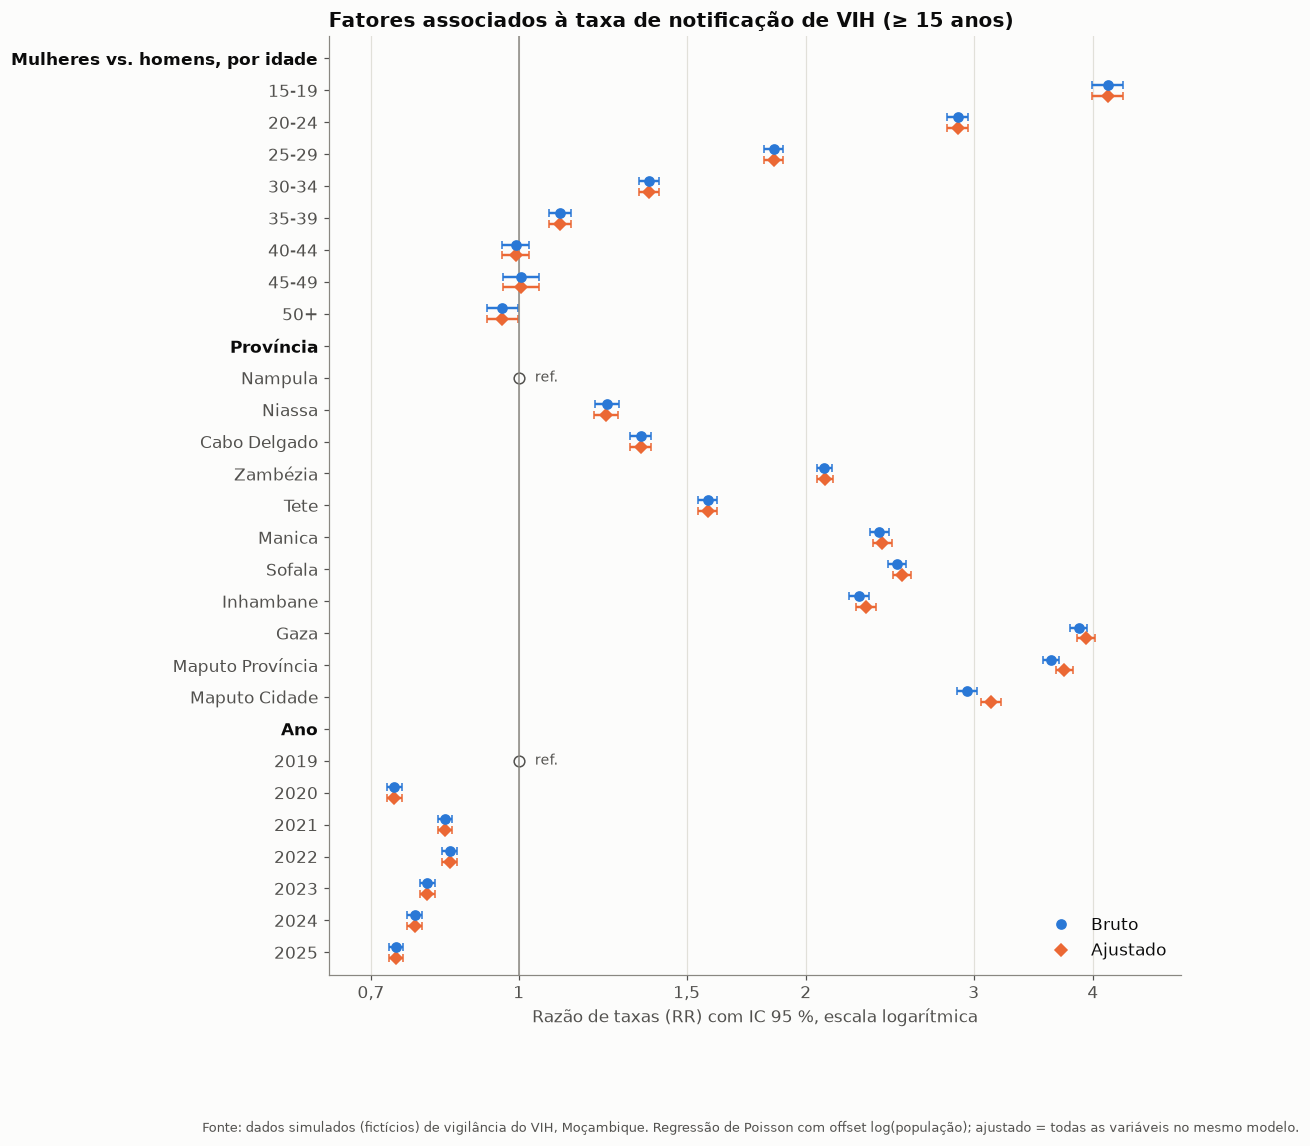

04:54:03 | INFO    |   → figura: 05_01_forest_poisson_rr.png


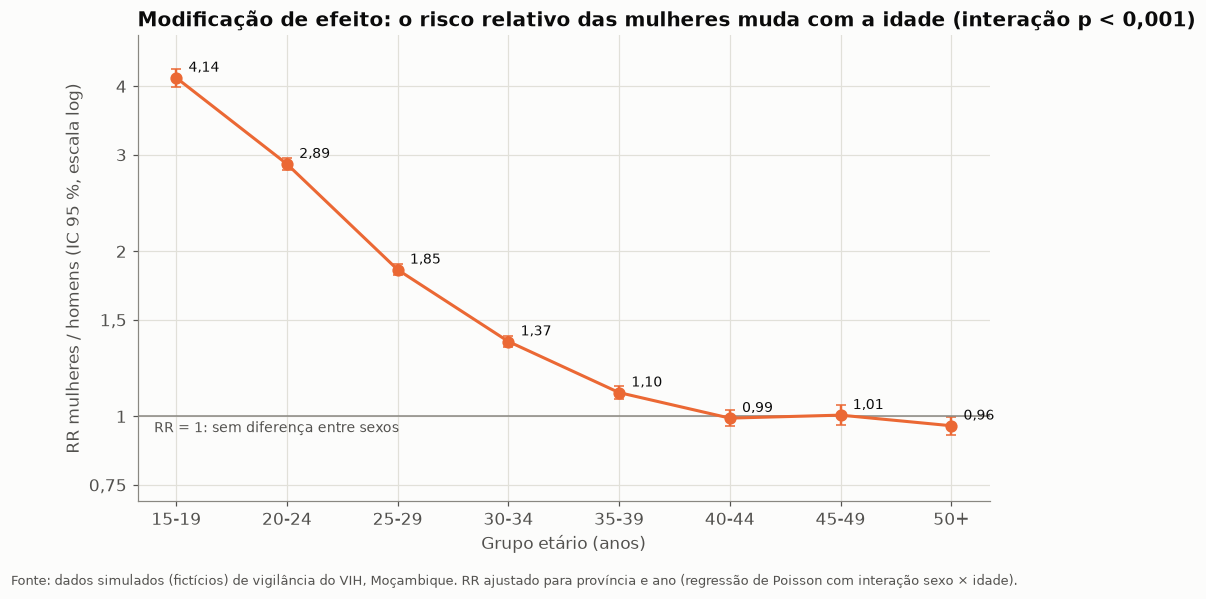

04:54:04 | INFO    |   → figura: 05_02_interacao_sexo_idade.png


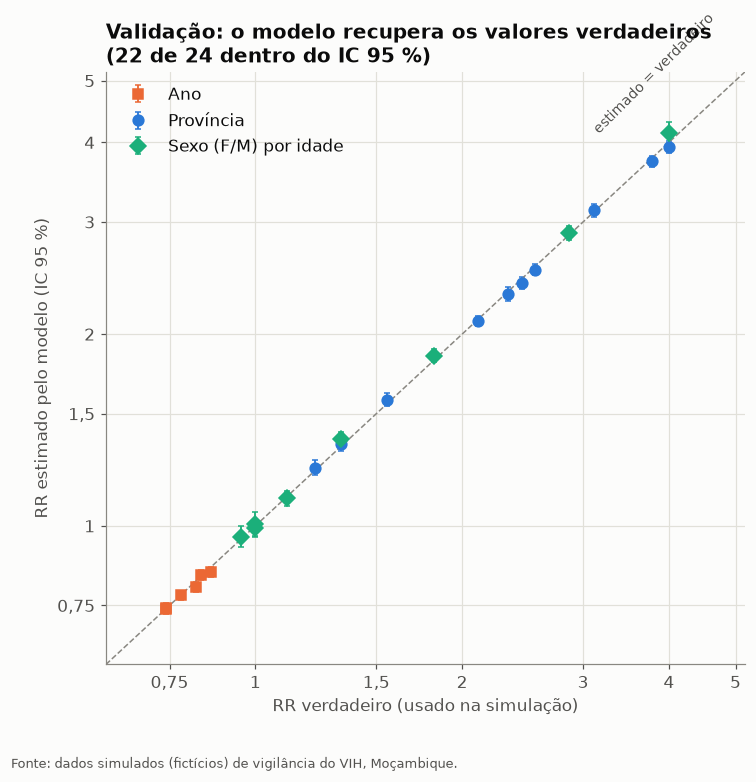

04:54:04 | INFO    |   → figura: 05_03_validacao_modelo.png


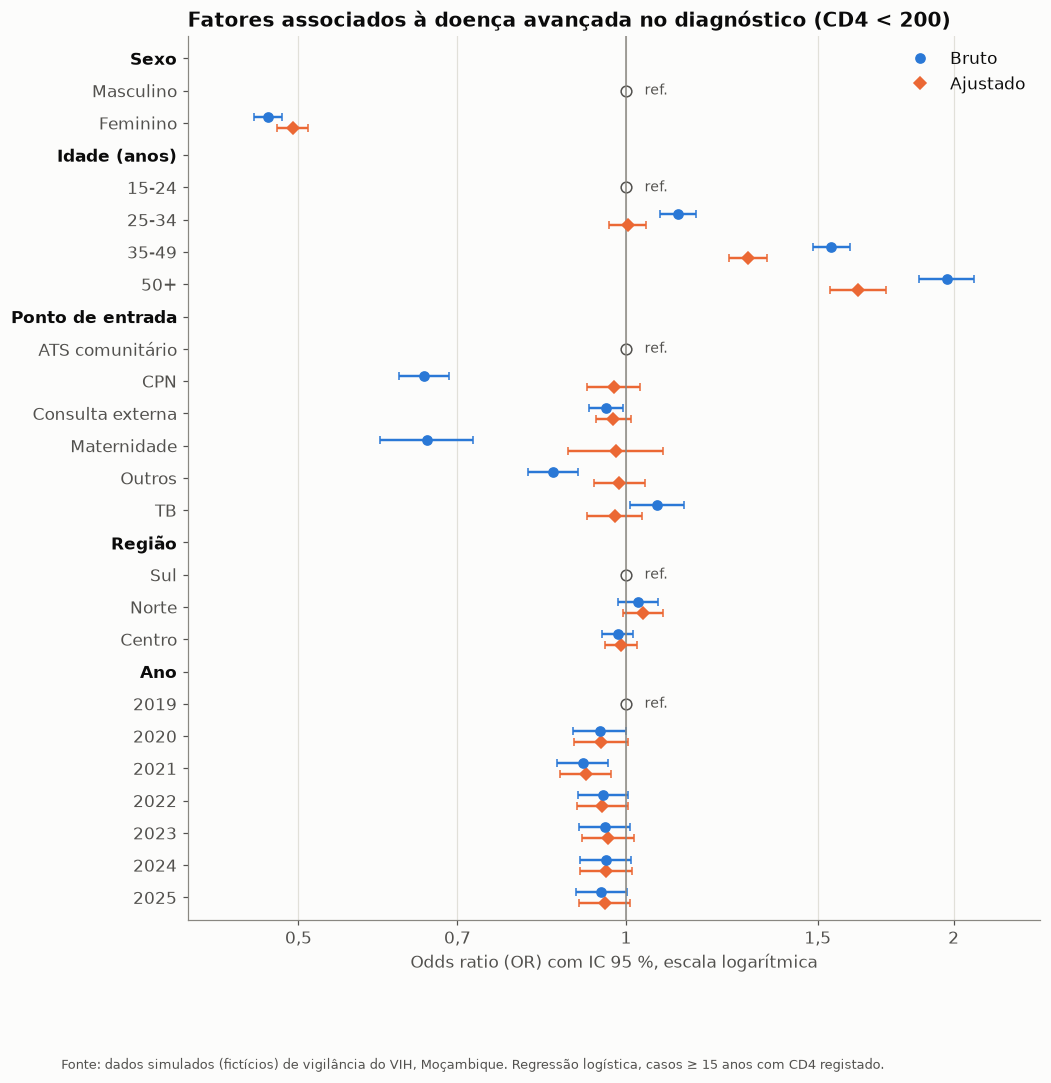

04:54:06 | INFO    |   → figura: 05_04_forest_logistica_or.png
04:54:06 | INFO    | Passo 5 concluído.


In [45]:
dados["associacao"] = passo5_associacao(dados)

### Como interpretar

- **Modificação de efeito:** o risco das mulheres em relação aos homens é **4,1×** aos 15–19 anos, 2,9× aos
  20–24, 1,4× aos 30–34 e **desaparece a partir dos 40**. Um único "RR do sexo" esconderia isto.
- **Validação:** 22 de 24 valores verdadeiros da simulação ficam dentro do IC 95 % (≈ 92 %; esperado ≈ 95 %).
- **Confundimento (logística):** a CPN parecia proteger contra a doença avançada (OR bruto ≈ 0,65), mas depois de
  ajustar fica ≈ 0,97. Não era a CPN — na CPN só há mulheres, e as mulheres chegam mais cedo ao diagnóstico.
- **Limitação:** o CD4 falta em ~40 % dos casos (análise de casos completos).

RR brutos e ajustados (Poisson):

In [46]:
dados["associacao"]["poisson_rr"].round(3)

,variavel,categoria,referencia,rr_bruto,ic_inf_bruto,ic_sup_bruto,p_bruto,rr,ic_inf,ic_sup,p
0,sexo_idade,15-19,False,4.144,3.989,4.305,0.000,4.144,3.989,4.305,0.000
1,sexo_idade,20-24,False,2.885,2.815,2.957,0.000,2.885,2.815,2.957,0.000
2,sexo_idade,25-29,False,1.851,1.810,1.893,0.000,1.851,1.810,1.893,0.000
3,sexo_idade,30-34,False,1.369,1.337,1.402,0.000,1.369,1.337,1.402,0.000
4,sexo_idade,35-39,False,1.105,1.075,1.135,0.000,1.105,1.075,1.135,0.000
5,sexo_idade,40-44,False,0.993,0.960,1.026,0.657,0.993,0.960,1.026,0.657
6,sexo_idade,45-49,False,1.005,0.963,1.050,0.818,1.005,0.963,1.050,0.818
7,sexo_idade,50+,False,0.961,0.926,0.998,0.037,0.961,0.926,0.998,0.037
8,provincia,Nampula,True,1.000,NaN,NaN,NaN,1.000,NaN,NaN,NaN
9,provincia,Niassa,False,1.239,1.204,1.275,0.000,1.234,1.200,1.270,0.000


---
## Passo 6 — Tendências e previsão até 2030

**Variação percentual anual (APC)**, a partir de uma Poisson com tendência linear no ano (escala log) e
indicadores para 2020–2021, para a quebra da COVID-19 não "puxar" a tendência:

$$\text{APC} = \left(e^{\beta_{\text{ano}}} - 1\right) \times 100$$

**Sazonalidade:** decomposição **STL** da série mensal = tendência + sazonal + resíduo.

**Previsão até 2030**

1. população projetada com o crescimento observado em cada estrato;
2. casos esperados = modelo × população;
3. incerteza por **2 000 simulações**: coeficientes sorteados + variação de ano para ano + variação de Poisson;
4. **validação retrospetiva:** treino até 2023, previsão de 2024–2025, comparação com o observado.

> 💡 Com poucos anos de dados, a variação entre anos sai subestimada e os intervalos ficam estreitos demais.
> Usamos um **mínimo prudente de ±2,5 % por ano** (`SIGMA_ANO_MINIMO`, em 6.1).

In [47]:
import patsy
from statsmodels.tsa.seasonal import STL

ANO_PREVISAO = 2030
N_SIMULACOES = 2000
# Com poucos anos de dados, a variação entre anos estimada é instável e tende a ser
# pequena demais → intervalos demasiado estreitos. Usamos um mínimo prudente de 2,5 %.
SIGMA_ANO_MINIMO = 0.025
SEMENTE_PREVISAO = 2026
ANOS_COVID = [2020, 2021]
GRUPOS_CRIANCAS = ["0-4", "5-9", "10-14"]
FORMULA_TENDENCIA = ("casos ~ C(sexo) * C(grupo_etario) + C(provincia) + ano_c + ano_c:menor15"
                     + "".join(f" + covid{a}" for a in ANOS_COVID))

### 6.1 Preparação dos dados e variação percentual anual (APC)

In [48]:
def preparar_tendencia(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["ano"] = df["ano"].astype(int)
    df["ano_c"] = df["ano"] - ANO_INICIO                  # ano centrado (0 = 1.º ano)
    df["menor15"] = df["grupo_etario"].astype(str).isin(GRUPOS_CRIANCAS).astype(int)
    for a in ANOS_COVID:
        df[f"covid{a}"] = (df["ano"] == a).astype(int)
    return df


def apc(beta: float, ep: float) -> tuple[float, float, float]:
    return tuple((np.exp(v) - 1) * 100 for v in (beta, beta - Z * ep, beta + Z * ep))


def apc_global(modelo) -> pd.DataFrame:
    p, cov = modelo.params, modelo.cov_params()
    linhas = []
    for rotulo, termos in [("≥ 15 anos", ["ano_c"]), ("< 15 anos", ["ano_c", "ano_c:menor15"])]:
        L = pd.Series(0.0, index=p.index)
        L[termos] = 1
        est, ep = float(L @ p), float(np.sqrt(L @ cov @ L))
        a, i, s = apc(est, ep)
        linhas.append({"grupo": rotulo, "apc_pct": a, "ic_inf": i, "ic_sup": s})
    return pd.DataFrame(linhas).round(2)


def apc_por_grupo(dados: pd.DataFrame, variavel: str) -> pd.DataFrame:
    """APC específica de cada categoria (tendência própria: C(var):ano_c), ≥ 15 anos."""
    d = dados[dados["menor15"] == 0].copy()
    d["grupo_etario"] = d["grupo_etario"].cat.remove_unused_categories()
    covid = "".join(f" + covid{a}" for a in ANOS_COVID)
    formula = f"casos ~ C(sexo) * C(grupo_etario) + C(provincia) + C({variavel}):ano_c{covid}"
    m = smf.glm(formula, d, family=sm.families.Poisson(), offset=d["log_pop"]).fit()
    linhas = []
    for cat in d[variavel].cat.categories:
        termo = f"C({variavel})[{cat}]:ano_c"
        a, i, s = apc(m.params[termo], m.bse[termo])
        linhas.append({variavel: cat, "apc_pct": a, "ic_inf": i, "ic_sup": s})
    return pd.DataFrame(linhas).round(2)

### 6.2 Sazonalidade (STL)

In [49]:
def decompor_sazonalidade(mensal: pd.Series) -> tuple[pd.DataFrame, pd.DataFrame]:
    stl = STL(mensal.astype(float), period=12, robust=True).fit()
    comp = pd.DataFrame({"observado": mensal, "tendencia": stl.trend,
                         "sazonal": stl.seasonal, "residuo": stl.resid})
    indice = (comp.assign(mes=comp.index.month)
              .groupby("mes").apply(lambda g: (g["sazonal"] / g["tendencia"]).mean() * 100)
              .rename("efeito_sazonal_%").round(1).reset_index())
    return comp, indice

### 6.3 Projeção da população e previsão por simulação

In [50]:
def projetar_populacao(pop: pd.DataFrame, ate: int) -> pd.DataFrame:
    """Cada estrato cresce à taxa média anual observada entre o 1.º e o último ano."""
    chave = ["provincia", "sexo", "grupo_etario"]
    p = _com_texto(pop, chave)
    ini = p[p["ano"] == ANO_INICIO].set_index(chave)["populacao"]
    fim = p[p["ano"] == ANO_FIM].set_index(chave)["populacao"]
    crescimento = (fim / ini) ** (1 / (ANO_FIM - ANO_INICIO)) - 1
    futuro = [(fim * (1 + crescimento) ** (a - ANO_FIM)).rename("populacao").reset_index().assign(ano=a)
              for a in range(ANO_FIM + 1, ate + 1)]
    return pd.concat(futuro, ignore_index=True)


def ajustar_e_prever(treino: pd.DataFrame, futuro: pd.DataFrame, rng) -> dict:
    """Ajusta o modelo de tendência e simula os casos futuros (por estrato)."""
    futuro = futuro.copy()
    futuro["casos"] = 0
    for v in ["provincia", "sexo", "grupo_etario"]:
        futuro[v] = pd.Categorical(futuro[v].astype(str), categories=treino[v].cat.categories)
    futuro["log_pop"] = np.log(futuro["populacao"])
    futuro = preparar_tendencia(futuro)
    for a in ANOS_COVID:
        futuro[f"covid{a}"] = 0

    tudo = pd.concat([treino.assign(_parte="treino"), futuro.assign(_parte="futuro")], ignore_index=True)
    for v in ["provincia", "sexo", "grupo_etario"]:
        tudo[v] = pd.Categorical(tudo[v].astype(str), categories=treino[v].cat.categories)
    y, X = patsy.dmatrices(FORMULA_TENDENCIA, tudo, return_type="dataframe")
    eh_treino = (tudo["_parte"] == "treino").to_numpy()
    modelo = sm.GLM(y[eh_treino], X[eh_treino], family=sm.families.Poisson(),
                    offset=tudo.loc[eh_treino, "log_pop"]).fit()
    dispersao = modelo.pearson_chi2 / modelo.df_resid

    # Variação de ano para ano que o modelo não explica (desvio dos totais anuais
    # observados em relação à tendência, excluindo os anos COVID que têm indicador próprio)
    treino_df = tudo.loc[eh_treino]
    tot = pd.DataFrame({"obs": treino_df["casos"].to_numpy(), "aj": modelo.fittedvalues.to_numpy(),
                        "ano": treino_df["ano"].to_numpy()}).groupby("ano").sum()
    tot = tot.drop(index=[a for a in ANOS_COVID if a in tot.index])
    desvios = np.log(tot["obs"] / tot["aj"])
    sigma_estimado = float(np.sqrt((desvios ** 2).sum() / max(len(desvios) - 2, 1)))
    sigma_ano = max(sigma_estimado, SIGMA_ANO_MINIMO)

    futuro_df = tudo.loc[~eh_treino]
    Xf = X[~eh_treino].to_numpy()
    offset_f = futuro_df["log_pop"].to_numpy()
    betas = rng.multivariate_normal(modelo.params, modelo.cov_params(), size=N_SIMULACOES)
    anos_f = np.sort(futuro_df["ano"].unique())
    choques = rng.normal(0, sigma_ano, size=(len(anos_f), N_SIMULACOES))   # 1 choque por ano
    idx_ano = np.searchsorted(anos_f, futuro_df["ano"].to_numpy())
    mu = np.exp(Xf @ betas.T + offset_f[:, None] + choques[idx_ano])   # estratos × simulações
    return {"modelo": modelo, "dispersao": dispersao, "sigma_ano": sigma_ano, "futuro": tudo.loc[~eh_treino].reset_index(drop=True),
            "mu_simulado": mu, "mu_central": np.exp(Xf @ modelo.params.to_numpy() + offset_f),
            "ajustado_treino": modelo.fittedvalues, "treino": tudo.loc[eh_treino].reset_index(drop=True)}


def resumir_previsao(prev: dict, por: str, rng) -> pd.DataFrame:
    """Soma os estratos por `por` e calcula intervalos de previsão (80 % e 95 %)."""
    futuro, mu = prev["futuro"], prev["mu_simulado"]
    linhas = []
    for valor, idx in futuro.groupby(por, observed=True).indices.items():
        mu_soma = mu[idx].sum(axis=0)                        # 1 valor por simulação
        casos_sim = rng.poisson(mu_soma)                     # + variação aleatória de Poisson
        pop = futuro.loc[idx, "populacao"].sum()
        q = np.percentile(casos_sim, [2.5, 10, 50, 90, 97.5])
        linhas.append({por: valor, "populacao": int(pop), "casos_previstos": prev["mu_central"][idx].sum(),
                       "ip95_inf": q[0], "ip80_inf": q[1], "mediana": q[2], "ip80_sup": q[3], "ip95_sup": q[4],
                       "taxa_prevista": prev["mu_central"][idx].sum() / pop * POR_HABITANTES,
                       "taxa_ip95_inf": q[0] / pop * POR_HABITANTES,
                       "taxa_ip95_sup": q[4] / pop * POR_HABITANTES})
    return pd.DataFrame(linhas).round(1)


def validacao_retrospetiva(dados: pd.DataFrame, pop: pd.DataFrame, rng, anos_teste: int = 2) -> pd.DataFrame:
    """Treina até ANO_FIM − anos_teste e prevê os anos seguintes, já observados."""
    corte = ANO_FIM - anos_teste
    treino = dados[dados["ano"] <= corte].copy()
    teste = dados[dados["ano"] > corte]
    futuro = _com_texto(pop, ["provincia", "sexo", "grupo_etario"])
    futuro = futuro[futuro["ano"] > corte][["provincia", "sexo", "grupo_etario", "ano", "populacao"]]
    prev = ajustar_e_prever(treino, futuro, rng)
    res = resumir_previsao(prev, "ano", rng).set_index("ano")
    res["observado"] = teste.groupby("ano")["casos"].sum()
    res["erro_pct"] = ((res["casos_previstos"] - res["observado"]) / res["observado"] * 100).round(1)
    res["observado_dentro_ip95"] = res["observado"].between(res["ip95_inf"], res["ip95_sup"])
    return res.reset_index()

### 6.4 Gráficos

In [51]:
def fig_apc_provincia(apc_prov: pd.DataFrame, apc_nac: float) -> None:
    t = apc_prov.set_index("provincia").reindex(ORDEM_PROVINCIAS[::-1])
    y = np.arange(len(t))
    fig, ax = plt.subplots(figsize=(10, 6))
    for regiao in ["Norte", "Centro", "Sul"]:
        m = t.index.map(PROVINCIAS) == regiao
        _barras_erro(ax, y[m], t["apc_pct"][m], t["ic_inf"][m], t["ic_sup"][m], CORES[regiao], regiao)
    ax.axvline(0, color=CORES["eixos"], lw=1)
    ax.axvline(apc_nac, color=CORES["meta"], ls="--", lw=1.2)
    ax.text(apc_nac, -0.9, f" Nacional (≥ 15 anos): {fmt_dec(apc_nac)} %/ano", fontsize=9,
            color=CORES["texto_secundario"])
    ax.set_yticks(y, t.index)
    ax.set_ylim(-1.2, len(t) - 0.4)
    lim = max(abs(t["ic_inf"].min()), abs(t["ic_sup"].max())) * 1.3
    ax.set_xlim(-lim, max(lim * 0.35, 1))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_dec(v, 0) + " %"))
    ax.grid(axis="y", visible=False)
    ax.legend(title="Região", loc="lower left")
    ax.set_xlabel("Variação percentual anual da taxa (APC) com IC 95 %")
    ax.set_title(f"Tendência da taxa de notificação por província, {ANO_INICIO}–{ANO_FIM}")
    guardar_figura(fig, "06_01_apc_provincia",
                   FONTE + " Poisson ajustada para sexo × idade, com indicadores para 2020–2021 (COVID-19).")


def fig_sazonalidade(comp: pd.DataFrame) -> None:
    fig, eixos = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True,
                              gridspec_kw={"height_ratios": [2, 1.2, 1]})
    ax = eixos[0]
    ax.plot(comp.index, comp["observado"], color=CORES["principal"], lw=1.5, label="Observado")
    ax.plot(comp.index, comp["tendencia"], color=CORES["secundaria"], lw=2.5, label="Tendência (STL)")
    ax.yaxis.set_major_formatter(EIXO_MILHARES)
    ax.set_ylabel("Casos/mês")
    ax.legend(loc="upper right", ncols=2)
    ax.set_title("Decomposição da série mensal: tendência, sazonalidade e resíduo")
    eixos[1].bar(comp.index, comp["sazonal"], width=24, color=CORES["principal"])
    eixos[1].axhline(0, color=CORES["eixos"], lw=0.8)
    eixos[1].set_ylabel("Sazonal")
    eixos[2].scatter(comp.index, comp["residuo"], s=14, color=CORES["texto_secundario"])
    eixos[2].axhline(0, color=CORES["eixos"], lw=0.8)
    eixos[2].set_ylabel("Resíduo")
    for e in eixos:
        e.grid(axis="x", visible=False)
    fig.tight_layout()
    guardar_figura(fig, "06_02_sazonalidade_stl",
                   FONTE + " STL robusta (período = 12 meses); a quebra de 2020 aparece no resíduo.")


def fig_previsao(observado: pd.Series, ajustado: pd.Series, prev: pd.DataFrame,
                 validacao: pd.DataFrame) -> None:
    fig, ax = plt.subplots(figsize=(12, 6))
    anos_f = prev["ano"].astype(int)
    ponte = [ANO_FIM] + list(anos_f)                      # liga o último ano observado à previsão
    ultimo = observado.iloc[-1]
    ax.fill_between(ponte, [ultimo] + list(prev["ip95_inf"]), [ultimo] + list(prev["ip95_sup"]),
                    color=CORES["secundaria"], alpha=0.15, lw=0, label="Intervalo de previsão 95 %")
    ax.fill_between(ponte, [ultimo] + list(prev["ip80_inf"]), [ultimo] + list(prev["ip80_sup"]),
                    color=CORES["secundaria"], alpha=0.30, lw=0, label="Intervalo de previsão 80 %")
    ax.plot(ponte, [ultimo] + list(prev["casos_previstos"]), color=CORES["secundaria"], ls="--",
            marker="o", ms=6, label="Previsão")
    ax.plot(observado.index, observado.values, color=CORES["principal"], marker="o", ms=7, label="Observado")
    ax.plot(ajustado.index, ajustado.values, color=CORES["texto_secundario"], lw=1.2, ls=":",
            label="Ajustado pelo modelo")
    for r in validacao.itertuples():
        ax.errorbar(r.ano + 0.12, r.casos_previstos, yerr=[[r.casos_previstos - r.ip95_inf],
                    [r.ip95_sup - r.casos_previstos]], fmt="s", ms=6, color=CORES["terciaria"], capsize=3)
    ax.errorbar([], [], fmt="s", color=CORES["terciaria"],
                label=f"Validação: previsto com dados até {int(validacao['ano'].min()) - 1}")
    fim = prev.iloc[-1]
    ax.annotate(f"{int(fim['ano'])}: {fmt_int(fim['casos_previstos'])}\n(IP 95 %: {fmt_int(fim['ip95_inf'])}–"
                f"{fmt_int(fim['ip95_sup'])})", (fim["ano"], fim["casos_previstos"]), xytext=(10, 18),
                textcoords="offset points", fontsize=9.5, color=CORES["texto"])
    ax.axvline(ANO_FIM + 0.5, color=CORES["eixos"], lw=0.8)
    ax.text(ANO_FIM + 0.55, ax.get_ylim()[1] * 0.98, "previsão →", fontsize=9, va="top",
            color=CORES["texto_secundario"])
    ax.set_xticks(range(ANO_INICIO, ANO_PREVISAO + 1))
    ax.set_xlim(ANO_INICIO - 0.4, ANO_PREVISAO + 1.4)
    ax.set_ylim(0, max(observado.max(), prev["ip95_sup"].max()) * 1.12)
    ax.yaxis.set_major_formatter(EIXO_MILHARES)
    ax.legend(loc="lower left", ncols=2, fontsize=9.5)
    ax.set_ylabel("Casos notificados por ano")
    ax.set_title(f"Previsão de casos de VIH notificados até {ANO_PREVISAO}")
    guardar_figura(fig, "06_03_previsao_casos",
                   FONTE + " Poisson com tendência log-linear, população projetada e 2 000 simulações. "
                           "Assume que a tendência recente se mantém.")

### 6.5 Função principal do Passo 6

In [52]:
def passo6_tendencias(dados: dict) -> dict:
    log.info("=" * 70)
    log.info("PASSO 6 — TENDÊNCIAS E PREVISÃO")
    log.info("=" * 70)
    casos, pop = dados["casos"], dados["populacao"]
    rng = np.random.default_rng(SEMENTE_PREVISAO)
    td = preparar_tendencia(dados_poisson(casos, pop, idade_min=0))

    # 6.1 APC
    log.info("Variação percentual anual (APC)")
    modelo = smf.glm(FORMULA_TENDENCIA, td, family=sm.families.Poisson(), offset=td["log_pop"]).fit()
    dispersao = modelo.pearson_chi2 / modelo.df_resid
    log.info(f"  Modelo de tendência: dispersão = {fmt_dec(dispersao, 2)}")
    apc_g = apc_global(modelo)
    apc_sexo = apc_por_grupo(td, "sexo")
    apc_prov = apc_por_grupo(td, "provincia")
    for r in apc_g.itertuples():
        log.info(f"  {r.grupo}: {fmt_dec(r.apc_pct, 2)} % por ano (IC 95 %: {fmt_dec(r.ic_inf, 2)} a {fmt_dec(r.ic_sup, 2)})")
    for r in apc_sexo.itertuples():
        log.info(f"  {SEXO_ROTULO[r.sexo]} (≥ 15): {fmt_dec(r.apc_pct, 2)} % por ano")
    ficheiro_par = PASTAS["brutos"] / "parametros_verdadeiros.json"
    if ficheiro_par.exists():
        verdade = json.loads(ficheiro_par.read_text(encoding="utf-8"))["variacao_anual_percent"]
        log.info(f"  Verificação: APC verdadeira da simulação (≥ 15 anos) = {fmt_dec(verdade, 2)} %")
    guardar_tabela(pd.concat([apc_g.assign(nivel="global"),
                              apc_sexo.rename(columns={"sexo": "grupo"}).assign(nivel="sexo (≥ 15)"),
                              apc_prov.rename(columns={"provincia": "grupo"}).assign(nivel="província (≥ 15)")]),
                   "06_apc_variacao_percentual_anual")

    # 6.2 Sazonalidade
    log.info("Sazonalidade (STL)")
    mensal = dados["descritiva"]["mensal"] if "descritiva" in dados else \
        casos.set_index("data_diagnostico").resample("MS").size()
    comp, indice = decompor_sazonalidade(mensal)
    guardar_tabela(comp.round(1).rename_axis("mes").reset_index(), "06_decomposicao_stl")
    guardar_tabela(indice, "06_indice_sazonal")
    pico, vale = indice.loc[indice["efeito_sazonal_%"].idxmax()], indice.loc[indice["efeito_sazonal_%"].idxmin()]
    log.info(f"  Pico sazonal no mês {int(pico['mes'])} ({fmt_dec(pico['efeito_sazonal_%'], 1)} %); "
             f"mínimo no mês {int(vale['mes'])} ({fmt_dec(vale['efeito_sazonal_%'], 1)} %)")

    # 6.3 Validação retrospetiva e previsão
    log.info("Validação retrospetiva")
    validacao = validacao_retrospetiva(td, pop, rng)
    guardar_tabela(validacao, "06_validacao_retrospetiva")
    for r in validacao.itertuples():
        log.info(f"  {r.ano}: previsto {fmt_int(r.casos_previstos)} vs. observado {fmt_int(r.observado)} "
                 f"(erro {fmt_dec(r.erro_pct)} %; {'dentro' if r.observado_dentro_ip95 else 'FORA'} do IP 95 %)")

    log.info(f"Previsão {ANO_FIM + 1}–{ANO_PREVISAO}")
    futuro = projetar_populacao(pop, ANO_PREVISAO)
    prev = ajustar_e_prever(td, futuro, rng)
    log.info(f"  Variação anual não explicada pela tendência usada nos intervalos: "
             f"±{fmt_dec(prev['sigma_ano'] * 100)} % (mínimo prudente {fmt_dec(SIGMA_ANO_MINIMO * 100)} %)")
    prev_ano = resumir_previsao(prev, "ano", rng)
    prev_prov = resumir_previsao({**prev, "futuro": prev["futuro"].assign(
        provincia_ano=prev["futuro"]["provincia"].astype(str) + "|" + prev["futuro"]["ano"].astype(str))},
        "provincia_ano", rng)
    prev_prov[["provincia", "ano"]] = prev_prov["provincia_ano"].str.split("|", expand=True)
    prev_prov = prev_prov[prev_prov["ano"] == str(ANO_PREVISAO)].drop(columns=["provincia_ano"])
    prev_prov = prev_prov.set_index("provincia").reindex(ORDEM_PROVINCIAS).reset_index()
    # O modelo usa só casos com província, sexo e idade; corrigir para o total notificado
    fator = len(casos) / td["casos"].sum()
    log.info(f"  Fator de correção para casos sem província/sexo/idade: ×{fmt_dec(fator, 3)}")
    colunas = ["casos_previstos", "ip95_inf", "ip80_inf", "mediana", "ip80_sup", "ip95_sup",
               "taxa_prevista", "taxa_ip95_inf", "taxa_ip95_sup"]
    for tab in (prev_ano, prev_prov):
        tab[colunas] = (tab[colunas] * fator).round(1)
    guardar_tabela(prev_ano, f"06_previsao_nacional_{ANO_PREVISAO}")
    guardar_tabela(prev_prov, f"06_previsao_provincia_{ANO_PREVISAO}")
    print(prev_ano[["ano", "casos_previstos", "ip95_inf", "ip95_sup", "taxa_prevista",
                    "taxa_ip95_inf", "taxa_ip95_sup"]].to_string(index=False), "\n")

    observado = casos.groupby("ano").size()
    ajustado = prev["treino"].assign(aj=prev["ajustado_treino"].to_numpy()).groupby("ano")["aj"].sum() * fator
    validacao_fig = validacao.assign(**{c: validacao[c] * fator for c in ["casos_previstos", "ip95_inf", "ip95_sup"]})

    fig_apc_provincia(apc_prov, apc_g.loc[0, "apc_pct"])
    fig_sazonalidade(comp)
    fig_previsao(observado, ajustado, prev_ano, validacao_fig)

    log.info("Passo 6 concluído.")
    return {"apc": apc_g, "apc_sexo": apc_sexo, "apc_provincia": apc_prov, "stl": comp,
            "indice_sazonal": indice, "validacao": validacao,
            "previsao_ano": prev_ano, "previsao_provincia": prev_prov}

### Executar o Passo 6

04:54:06 | INFO    | ======================================================================
04:54:06 | INFO    | PASSO 6 — TENDÊNCIAS E PREVISÃO
04:54:06 | INFO    | ======================================================================
04:54:06 | INFO    | Variação percentual anual (APC)
04:54:06 | INFO    |   Modelo de tendência: dispersão = 1,33
04:54:06 | INFO    |   ≥ 15 anos: -4,72 % por ano (IC 95 %: -4,97 a -4,47)
04:54:06 | INFO    |   < 15 anos: -7,01 % por ano (IC 95 %: -7,58 a -6,45)
04:54:06 | INFO    |   Masculino (≥ 15): -4,94 % por ano
04:54:06 | INFO    |   Feminino (≥ 15): -4,81 % por ano
04:54:06 | INFO    |   Verificação: APC verdadeira da simulação (≥ 15 anos) = -4,88 %
04:54:06 | INFO    |   → tabela: 06_apc_variacao_percentual_anual.csv
04:54:06 | INFO    | Sazonalidade (STL)
04:54:06 | INFO    |   → tabela: 06_decomposicao_stl.csv
04:54:06 | INFO    |   → tabela: 06_indice_sazonal.csv
04:54:06 | INFO    |   Pico sazonal no mês 7 (12,9 %); mínimo no mês 1 (-13,9 

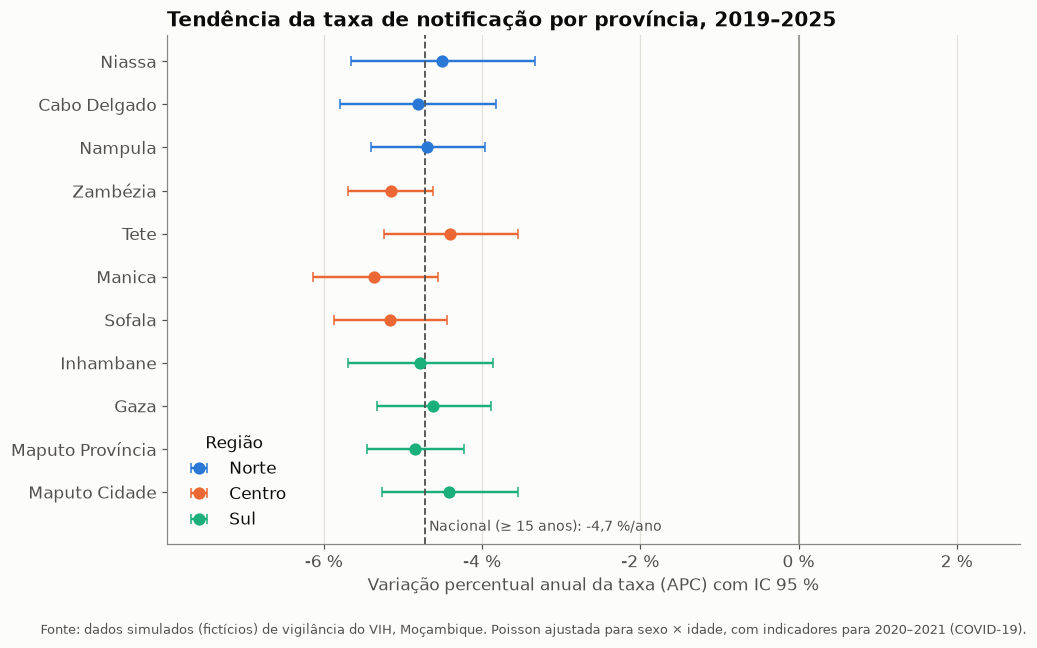

04:54:07 | INFO    |   → figura: 06_01_apc_provincia.png


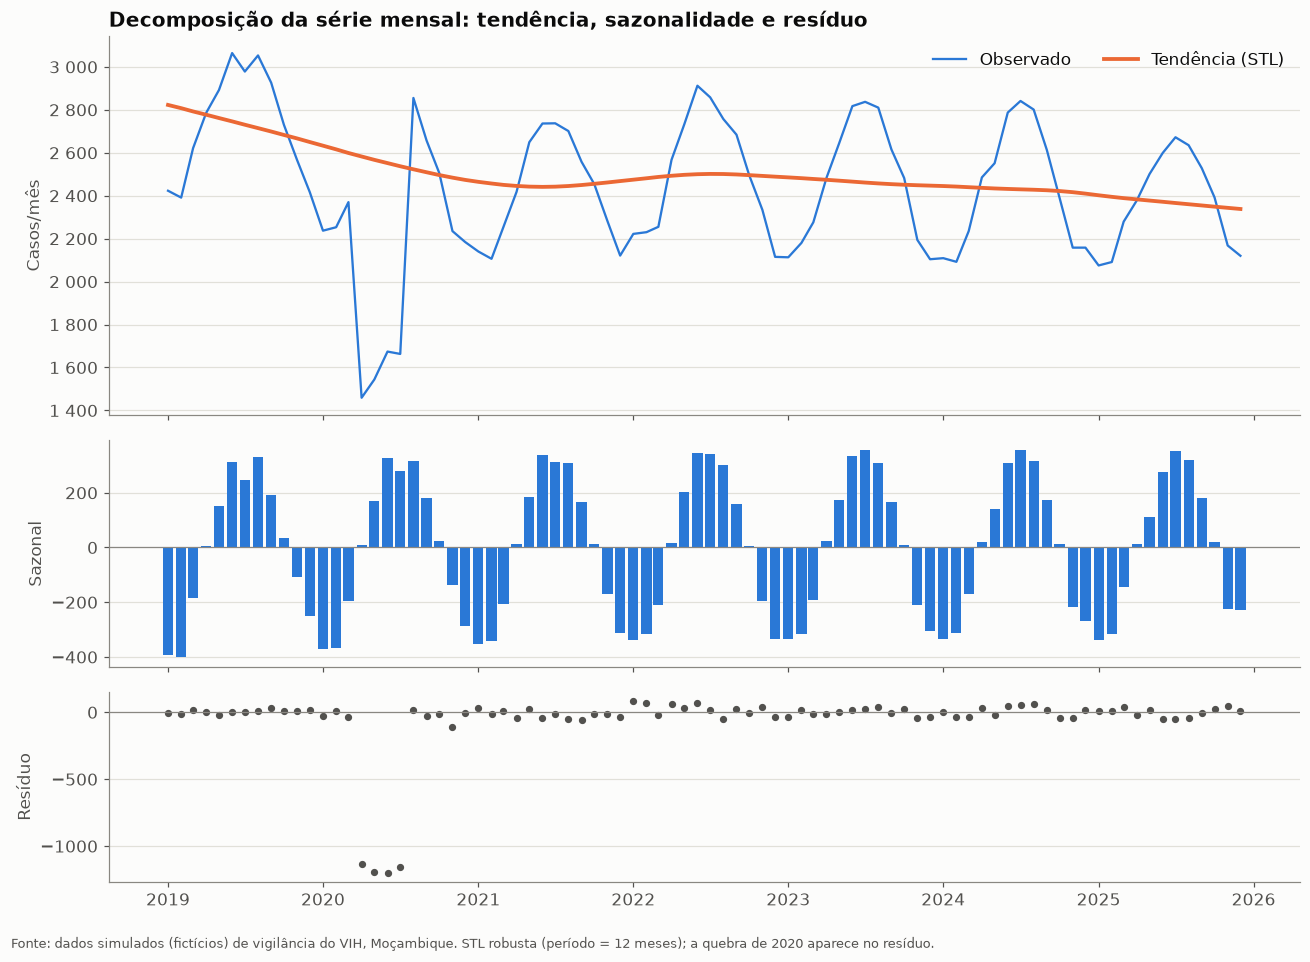

04:54:09 | INFO    |   → figura: 06_02_sazonalidade_stl.png


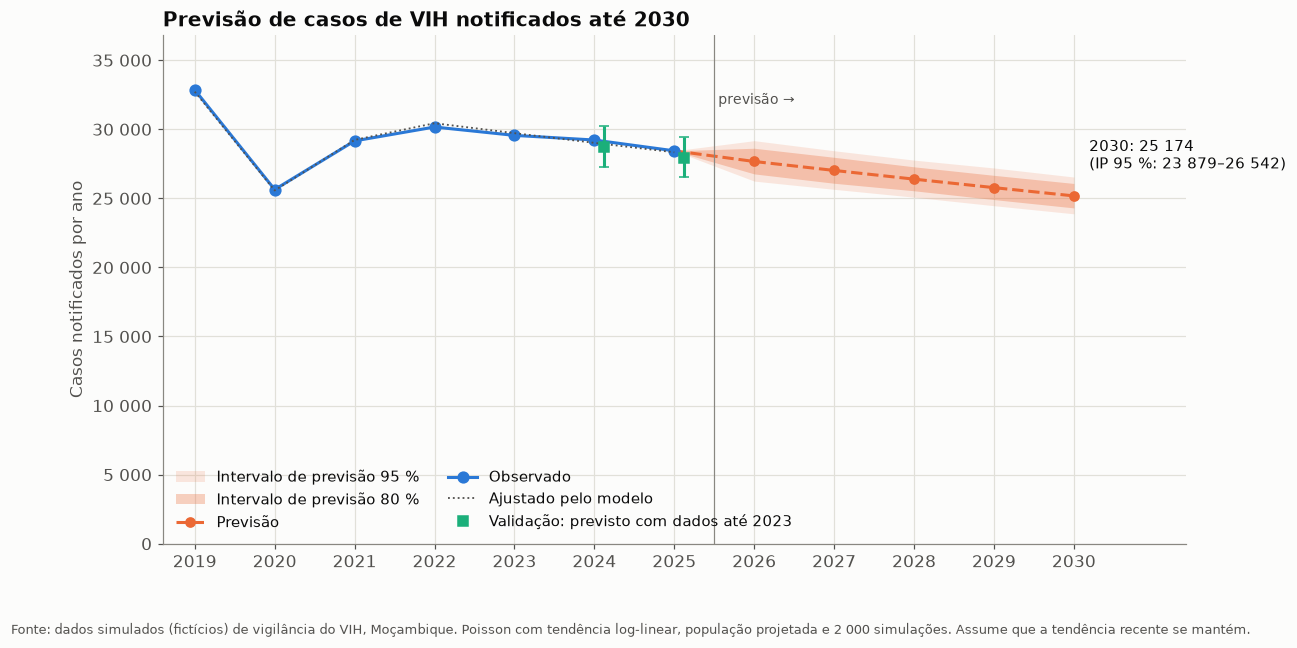

04:54:10 | INFO    |   → figura: 06_03_previsao_casos.png
04:54:10 | INFO    | Passo 6 concluído.


In [53]:
dados["tendencias"] = passo6_tendencias(dados)

### Como interpretar

- **≥ 15 anos: −4,7 % por ano** (IC 95 %: −5,0 a −4,5) — o valor verdadeiro da simulação é −4,88 %.
- **< 15 anos: −7,0 % por ano** — descem mais depressa, acompanhando a melhoria da PTV.
- **Sazonalidade:** pico em julho (+13 %) e mínimo em janeiro (−14 %); o confinamento de 2020 fica isolado no resíduo.
- **Validação retrospetiva:** erro de −1,8 %, com o observado dentro dos intervalos de previsão.
- **Premissas:** a tendência continua; notificação ≠ incidência.

Previsão nacional:

In [54]:
dados["tendencias"]["previsao_ano"]

,ano,populacao,casos_previstos,ip95_inf,ip80_inf,mediana,ip80_sup,ip95_sup,taxa_prevista,taxa_ip95_inf,taxa_ip95_sup
0,2026,34941721,27666.6,26246.6,26767.4,27678.7,28624.8,29173.2,79.2,75.1,83.5
1,2027,35920090,27018.8,25651.1,26090.3,27069.6,27968.6,28443.2,75.2,71.4,79.2
2,2028,36925853,26387.9,25081.6,25545.9,26401.7,27279.6,27765.8,71.4,67.9,75.2
3,2029,37959778,25773.2,24465.0,24908.6,25771.3,26663.4,27196.1,67.9,64.4,71.6
4,2030,39022652,25174.5,23878.8,24305.9,25189.9,26075.9,26541.7,64.5,61.2,68.0


---
## Passo 7 — Relatório final (HTML)

Junta tudo num **único ficheiro HTML** (as figuras ficam embutidas — basta enviar um ficheiro). Os números do
resumo são **calculados**: se os dados mudarem, o texto muda também.

Aqui só **definimos** as funções. O relatório é gerado **no fim do notebook**, depois do Passo 8, para incluir os
mapas (se existirem). Muda `AUTOR` para o teu nome.

In [55]:
import base64
import html as html_lib
import platform

FICHEIRO_RELATORIO = PASTA_PROJETO / "resultados" / "relatorio_vih_vigilancia.html"
AUTOR = "[O teu nome]"          # ← muda aqui

### 7.1 Peças do relatório

In [56]:
def esc(texto) -> str:
    return html_lib.escape(str(texto))


def figura_html(nome: str, legenda: str) -> str:
    caminho = PASTAS["figuras"] / f"{nome}.png"
    if not caminho.exists():
        return ""
    dados = base64.b64encode(caminho.read_bytes()).decode("ascii")
    return (f'<figure><img src="data:image/png;base64,{dados}" alt="{esc(legenda)}">'
            f"<figcaption>{esc(legenda)}</figcaption></figure>")


def tabela_html(df: pd.DataFrame, colunas: dict | None = None, decimais: dict | None = None) -> str:
    """DataFrame → tabela HTML com números em formato português (números alinhados à direita)."""
    df = df.copy()
    if colunas:
        df = df[list(colunas)].rename(columns=colunas)
    decimais = decimais or {}
    numericas = set()
    for c in df.columns:
        if pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map({True: "Sim", False: "Não"})
        elif pd.api.types.is_float_dtype(df[c]):
            casas = decimais.get(c, 1)
            df[c] = df[c].map(lambda v: "—" if pd.isna(v) else (fmt_int(v) if casas == 0 else fmt_dec(v, casas)))
            numericas.add(c)
        elif pd.api.types.is_integer_dtype(df[c]):
            if str(c).lower() != "ano":
                df[c] = df[c].map(lambda v: "—" if pd.isna(v) else fmt_int(v))
                numericas.add(c)
        else:   # texto que parece número (ex.: Tabela 1) também à direita
            if df[c].astype(str).str.match(r"^[\d\s—<.,()%\[\]–-]+$").mean() > 0.6:
                numericas.add(c)
    cab = "".join(f'<th class="{"n" if c in numericas else ""}">{esc(c)}</th>' for c in df.columns)
    linhas = "".join(
        "<tr>" + "".join(
            f'<td class="{"n" if c in numericas else ("sub" if str(v).startswith("   ") else "")}">'
            f'{esc("—" if pd.isna(v) else str(v).strip())}</td>'
            for c, v in zip(df.columns, row)) + "</tr>"
        for row in df.itertuples(index=False))
    return f'<div class="tabela"><table><thead><tr>{cab}</tr></thead><tbody>{linhas}</tbody></table></div>'


def ic_txt(v, i, s, casas=1, sufixo="") -> str:
    sep = " a " if i < 0 else "–"          # evita "-5,0–-4,5"
    return f"{fmt_dec(v, casas)}{sufixo} (IC 95 %: {fmt_dec(i, casas)}{sep}{fmt_dec(s, casas)}{sufixo})"


def efeitos_legiveis(tab: pd.DataFrame, col: str) -> pd.DataFrame:
    t = tab.copy()
    t["Variável"] = t["variavel"].map(NOMES_VARIAVEIS)
    t["Categoria"] = [rotulo_categoria(v, c) for v, c in zip(t["variavel"], t["categoria"])]
    t["Bruto"] = ["1 (ref.)" if r else fmt_dec(v, 2) for r, v in zip(t["referencia"], t[f"{col}_bruto"])]
    t["Ajustado (IC 95 %)"] = ["1 (ref.)" if r.referencia else
                               f"{fmt_dec(getattr(r, col if col == 'rr' else 'or_ajustado'), 2)} "
                               f"({fmt_dec(r.ic_inf, 2)}–{fmt_dec(r.ic_sup, 2)})" for r in t.itertuples()]
    t["p"] = ["—" if pd.isna(p) else fmt_p(p) for p in t["p"]]
    return t[["Variável", "Categoria", "Bruto", "Ajustado (IC 95 %)", "p"]]


CSS = """
:root{--fundo:#fcfcfb;--texto:#0b0b0b;--sec:#52514e;--linha:#e1e0d9;--realce:#2a78d6;--aviso:#fff4e5}
*{box-sizing:border-box}
body{margin:0;background:var(--fundo);color:var(--texto);font:16px/1.6 system-ui,-apple-system,"Segoe UI",Roboto,sans-serif}
main{max-width:980px;margin:0 auto;padding:24px 16px 64px}
h1{font-size:1.9rem;line-height:1.25;margin:0 0 4px}
h2{font-size:1.35rem;margin:48px 0 8px;padding-top:8px;border-top:1px solid var(--linha)}
h3{font-size:1.05rem;margin:28px 0 6px}
.sub{color:var(--sec);margin:0 0 16px}
.aviso{background:var(--aviso);border-left:4px solid #eb6834;padding:10px 14px;margin:16px 0;border-radius:4px}
.kpis{display:grid;grid-template-columns:repeat(auto-fit,minmax(165px,1fr));gap:12px;margin:16px 0}
.kpi{border:1px solid var(--linha);border-radius:8px;padding:12px 14px;background:#fff}
.kpi b{display:block;font-size:1.5rem;line-height:1.2}
.kpi span{color:var(--sec);font-size:.9rem}
figure{margin:20px 0}
figure img{max-width:100%;height:auto;border:1px solid var(--linha);border-radius:6px;background:#fff}
figcaption{color:var(--sec);font-size:.9rem;margin-top:4px}
.tabela{overflow-x:auto;margin:12px 0}
table{border-collapse:collapse;font-size:.88rem;min-width:60%}
th,td{padding:5px 10px;border-bottom:1px solid var(--linha);text-align:left;vertical-align:top}
th.n,td.n{text-align:right;white-space:nowrap}
td.sub{padding-left:28px;color:#33322f}
th{background:#f3f2ee;font-weight:600}
nav ol{columns:2;padding-left:20px;color:var(--sec)}
nav a{color:var(--realce);text-decoration:none}
ul.achados li{margin-bottom:6px}
footer{margin-top:48px;color:var(--sec);font-size:.85rem;border-top:1px solid var(--linha);padding-top:12px}
@media (max-width:600px){nav ol{columns:1}h1{font-size:1.5rem}}
"""

### 7.2 Construção do relatório

In [57]:
def construir_relatorio(dados: dict) -> str:
    casos = dados["casos"]
    med, ass, ten, desc = dados["medidas"], dados["associacao"], dados["tendencias"], dados["descritiva"]
    nac, prov = med["nacional"], med["provincia"].drop(index="Moçambique")
    rr_si, tab_or = ass["rr_sexo_idade"], ass["logistica_or"]
    apc_g = ten["apc"].set_index("grupo")
    prev = ten["previsao_ano"].set_index("ano")
    ptv = med["ptv_ano"]
    tv = ptv[(ptv["indicador"] == "transmissao_vertical") & (ptv["ano"] == ANO_FIM)].iloc[0]
    tarv = ptv[(ptv["indicador"] == "cobertura_tarv") & (ptv["ano"] == ANO_FIM)].iloc[0]
    or_mulher = tab_or.query("variavel == 'sexo' and categoria == 'F'").iloc[0]
    topo = prov["taxa_padr_moz"].idxmax()
    base = prov["taxa_padr_moz"].idxmin()
    t_ini, t_fim = nac.loc[ANO_INICIO], nac.loc[ANO_FIM]
    fluxo = pd.read_csv(PASTAS["tabelas"] / "02_fluxo_registos.csv", encoding="utf-8-sig")
    prev_fim = prev.loc[ANO_PREVISAO]

    kpis = [
        (fmt_int(len(casos)), f"casos notificados, {ANO_INICIO}–{ANO_FIM}"),
        (fmt_dec(t_fim["taxa"]), f"casos por 100 000 hab. em {ANO_FIM} ({fmt_dec(t_ini['taxa'])} em {ANO_INICIO})"),
        (f"{fmt_dec(apc_g.loc['≥ 15 anos', 'apc_pct'])} %", "variação anual da taxa (≥ 15 anos)"),
        (f"{fmt_dec(tv['%'])} %", f"transmissão vertical precoce em {ANO_FIM}"),
        (fmt_int(prev_fim["casos_previstos"]), f"casos previstos em {ANO_PREVISAO}"),
    ]
    achados = [
        f"A taxa de notificação desceu de <b>{fmt_dec(t_ini['taxa'])}</b> para <b>{fmt_dec(t_fim['taxa'])}</b> "
        f"casos por 100 000 hab. entre {ANO_INICIO} e {ANO_FIM}; nas pessoas com ≥ 15 anos a variação anual foi "
        f"de {ic_txt(*apc_g.loc['≥ 15 anos', ['apc_pct', 'ic_inf', 'ic_sup']], casas=1, sufixo=' %')}.",
        f"Em 2020 os diagnósticos caíram de forma marcada (estado de emergência COVID-19), com recuperação parcial em 2021.",
        f"Depois de padronizar por idade, <b>{esc(topo)}</b> tem a taxa mais alta "
        f"({fmt_dec(prov.loc[topo, 'taxa_padr_moz'])} por 100 000) e <b>{esc(base)}</b> a mais baixa "
        f"({fmt_dec(prov.loc[base, 'taxa_padr_moz'])}).",
        f"As raparigas de 15–19 anos têm uma taxa <b>{fmt_dec(rr_si.loc['15-19', 'rr_F_vs_M'], 1)} vezes</b> superior "
        f"à dos rapazes da mesma idade; a diferença desaparece a partir dos 40 anos (modificação de efeito, "
        f"p &lt; 0,001).",
        f"Os homens chegam mais tarde ao diagnóstico: as mulheres têm menos doença avançada (CD4 &lt; 200), "
        f"OR ajustado {fmt_dec(or_mulher['or_ajustado'], 2)} ({fmt_dec(or_mulher['ic_inf'], 2)}–"
        f"{fmt_dec(or_mulher['ic_sup'], 2)}).",
        f"Na PTV, {fmt_dec(tarv['%'])} % das gestantes positivas estavam em TARV em {ANO_FIM} e a transmissão "
        f"vertical precoce foi {ic_txt(tv['%'], tv['ic_inf'], tv['ic_sup'], sufixo=' %')}, abaixo da meta de 5 %.",
        f"Se a tendência se mantiver, prevêem-se cerca de <b>{fmt_int(prev_fim['casos_previstos'])}</b> casos em "
        f"{ANO_PREVISAO} (IP 95 %: {fmt_int(prev_fim['ip95_inf'])}–{fmt_int(prev_fim['ip95_sup'])}).",
    ]

    geo = dados.get("geoespacial")
    secao_geo, n_lim = "", 9
    if geo:
        n_lim = 10
        mt = geo["moran"].iloc[0]
        lisa_txt = ", ".join(f"{r.provincia} ({r.lisa})" for r in geo["geo"].itertuples() if r.lisa != "Não significativo")
        secao_geo = f"""
<h2 id="geo">9. Análise geoespacial</h2>
<p>A taxa padronizada por idade tem um I de Moran de <b>{fmt_dec(mt['I_moran'], 2)}</b>
(p {fmt_p(mt['p_permutacao'])}; vizinhança por contiguidade).
{'Agrupamentos locais (LISA): ' + esc(lisa_txt) + '.' if lisa_txt else 'Nenhum agrupamento local significativo.'}
Com 11 províncias o poder estatístico é baixo: estes resultados são sobretudo descritivos.</p>
{tabela_html(geo["moran"], {"indicador": "Indicador", "I_moran": "I de Moran", "I_esperado": "I esperado", "p_permutacao": "p"}, {"I de Moran": 3, "I esperado": 3, "p": 3})}
{figura_html("08_01_mapas_indicadores", "Figura 17. Indicadores por província.")}
{figura_html("08_02_mapas_por_ano", "Figura 18. Taxa padronizada por ano (mesma escala).")}
{figura_html("08_03_moran_lisa", "Figura 19. Gráfico de Moran e agrupamentos locais (LISA).")}"""
    sec = []
    sec.append(f"""
<h1>Análise epidemiológica da vigilância do VIH em Moçambique, {ANO_INICIO}–{ANO_FIM}</h1>
<p class="sub">Incluindo prevenção da transmissão vertical (PTV) e previsão até {ANO_PREVISAO} ·
{esc(AUTOR)} · gerado a {datetime.now():%d/%m/%Y}</p>
<div class="aviso"><b>Dados simulados.</b> Todos os números deste relatório vêm de dados fictícios,
criados para desenvolver e validar o código. Não representam a situação real do país.</div>
<div class="kpis">{''.join(f'<div class="kpi"><b>{v}</b><span>{esc(r)}</span></div>' for v, r in kpis)}</div>
<nav><ol>
<li><a href="#achados">Principais achados</a></li><li><a href="#metodos">Métodos</a></li>
<li><a href="#qualidade">Qualidade dos dados</a></li><li><a href="#descritiva">Pessoa, lugar e tempo</a></li>
<li><a href="#taxas">Taxas e padronização</a></li><li><a href="#ptv">PTV</a></li>
<li><a href="#associacao">Fatores associados</a></li><li><a href="#tendencias">Tendências e previsão</a></li>
{'<li><a href="#geo">Análise geoespacial</a></li>' if secao_geo else ''}<li><a href="#limitacoes">Limitações</a></li></ol></nav>

<h2 id="achados">1. Principais achados</h2>
<ul class="achados">{''.join(f'<li>{a}</li>' for a in achados)}</ul>

<h2 id="metodos">2. Métodos</h2>
<p><b>Fontes:</b> lista nominal de casos notificados, relatório mensal agregado da PTV por província e
população por província, ano, sexo e grupo etário (denominadores).</p>
<p><b>Limpeza:</b> remoção de duplicados e re-notificações (mantida a primeira notificação), normalização de
códigos, valores impossíveis passados a "em falta", imputações explícitas e assinaladas (sexo a partir de
gestação/CPN; data de diagnóstico = data mais antiga entre notificação e início de TARV).</p>
<p><b>Medidas:</b> taxas por 100 000 pessoas-ano com IC 95 % exato de Poisson; taxas padronizadas por idade
(método direto; populações-padrão de Moçambique {ANO_REFERENCIA_PADRONIZACAO} e OMS) com IC de Fay e Feuer;
proporções com IC de Wilson.</p>
<p><b>Associação:</b> regressão de Poisson com offset log(população), ≥ 15 anos, com teste da interação
sexo × idade (razão de verosimilhanças) e verificação da sobredispersão; regressão logística para doença
avançada (CD4 &lt; 200), com OR brutos e ajustados.</p>
<p><b>Tendências e previsão:</b> variação percentual anual (APC) por Poisson com indicadores para 2020–2021;
decomposição STL da série mensal; previsão até {ANO_PREVISAO} com população projetada e
{fmt_int(N_SIMULACOES)} simulações; validação retrospetiva com os 2 últimos anos.</p>

<h2 id="qualidade">3. Qualidade dos dados</h2>
<h3>Fluxo de registos</h3>
{tabela_html(fluxo, {"etapa": "Etapa", "n": "n", "excluidos": "Excluídos"})}
<h3>Problemas encontrados e ações</h3>
{tabela_html(dados["qualidade"].query("n_registos > 0"),
             {"tabela": "Tabela", "problema": "Problema", "n_registos": "n", "%": "%", "acao": "Ação"},
             {"%": 2})}

<h2 id="descritiva">4. Pessoa, lugar e tempo</h2>
<h3>Tabela 1. Características dos casos, por sexo</h3>
{tabela_html(desc["tabela_1"])}
{figura_html("03_01_piramide_idade_sexo", "Figura 1. Casos por idade e sexo.")}
{figura_html("03_02_ponto_entrada_sexo", "Figura 2. Ponto de entrada no diagnóstico, por sexo.")}
{figura_html("03_03_cd4_doenca_avancada", "Figura 3. CD4 no diagnóstico e doença avançada por idade e sexo.")}
{figura_html("03_05_mapa_calor_provincia_ano", "Figura 4. Casos por província e ano.")}
{figura_html("03_06_curva_epidemica_mensal", "Figura 5. Curva epidémica mensal.")}

<h2 id="taxas">5. Taxas e padronização</h2>
{tabela_html(med["provincia"].reset_index(),
             {"provincia": "Província", "casos": "Casos", "taxa": "Taxa bruta", "ic_inf": "IC inf.",
              "ic_sup": "IC sup.", "taxa_padr_moz": "Padronizada (Moç.)", "taxa_padr_oms": "Padronizada (OMS)"})}
{figura_html("04_01_taxas_provincia", "Figura 6. Taxa bruta e padronizada por idade, por província.")}
{figura_html("04_02_taxas_idade_sexo", "Figura 7. Taxas específicas por idade e sexo.")}
{figura_html("04_03_tendencia_taxas", "Figura 8. Tendência da taxa de notificação por sexo.")}

<h2 id="ptv">6. Prevenção da transmissão vertical</h2>
{tabela_html(ptv.pivot(index="ano", columns="indicador", values="%").reset_index()
             .rename(columns={"ano": "Ano", "cobertura_testagem": "Testagem (%)", "positividade": "Positividade (%)",
                              "cobertura_tarv": "TARV (%)", "cobertura_pcr_2meses": "PCR ≤ 2 meses (%)",
                              "transmissao_vertical": "Transmissão (%)"}))}
{figura_html("03_08_ptv_cascata", "Figura 9. Cascata da PTV e transmissão por província.")}
{figura_html("04_04_transmissao_vertical_ic", "Figura 10. Transmissão vertical precoce por província, com IC 95 %.")}

<h2 id="associacao">7. Fatores associados</h2>
<h3>Regressão de Poisson — taxa de notificação (≥ 15 anos)</h3>
{tabela_html(efeitos_legiveis(ass["poisson_rr"], "rr").replace({"Mulheres vs. homens, por idade": "Mulheres/homens"}))}
{figura_html("05_02_interacao_sexo_idade", "Figura 11. Razão de taxas mulheres/homens por grupo etário.")}
{figura_html("05_03_validacao_modelo", "Figura 12. Validação: RR estimados vs. valores usados na simulação.")}
<h3>Regressão logística — doença avançada no diagnóstico</h3>
{tabela_html(efeitos_legiveis(tab_or, "or"))}
{figura_html("05_04_forest_logistica_or", "Figura 13. OR brutos e ajustados para doença avançada.")}

<h2 id="tendencias">8. Tendências e previsão</h2>
{tabela_html(ten["apc"], {"grupo": "Grupo", "apc_pct": "APC (%)", "ic_inf": "IC inf.", "ic_sup": "IC sup."}, {"APC (%)": 2, "IC inf.": 2, "IC sup.": 2})}
{figura_html("06_01_apc_provincia", "Figura 14. Variação percentual anual por província.")}
{figura_html("06_02_sazonalidade_stl", "Figura 15. Decomposição STL da série mensal.")}
{tabela_html(ten["previsao_ano"], {"ano": "Ano", "casos_previstos": "Casos previstos", "ip95_inf": "IP 95 % inf.",
             "ip95_sup": "IP 95 % sup.", "taxa_prevista": "Taxa por 100 000"},
             {"Casos previstos": 0, "IP 95 % inf.": 0, "IP 95 % sup.": 0})}
{figura_html("06_03_previsao_casos", f"Figura 16. Previsão de casos notificados até {ANO_PREVISAO}.")}

{secao_geo}
<h2 id="limitacoes">{n_lim}. Limitações</h2>
<ul>
<li>Casos notificados não são o mesmo que infeções novas: dependem do esforço de testagem e da completude da notificação.</li>
<li>O CD4 falta em {fmt_dec(casos['cd4_diagnostico'].isna().mean() * 100, 0)} % dos casos; a regressão logística usa casos
completos e pode ter viés se a falta não for aleatória.</li>
<li>Casos sem província, sexo ou idade ficam fora das taxas específicas (corrigido de forma proporcional nas
taxas padronizadas e na previsão).</li>
<li>A previsão assume que a tendência recente continua; mudanças de política, de testagem ou choques
(como a COVID-19) não são previstos.</li>
<li>A transmissão vertical medida pelo PCR até aos 2 meses é a transmissão <i>precoce</i>; a final, que inclui
a amamentação, é mais alta.</li>
</ul>
<footer>Gerado automaticamente por <code>analise_vih_vigilancia.py</code> · Python {platform.python_version()} ·
pandas {pd.__version__} · statsmodels {sm.__version__} · semente da simulação de previsão: {SEMENTE_PREVISAO}</footer>
""")
    corpo = "\n".join(sec)
    return (f'<!doctype html><html lang="pt"><head><meta charset="utf-8">'
            f'<meta name="viewport" content="width=device-width,initial-scale=1">'
            f"<title>Vigilância do VIH – relatório</title><style>{CSS}</style></head>"
            f"<body><main>{corpo}</main></body></html>")


def passo7_relatorio(dados: dict) -> Path:
    log.info("=" * 70)
    log.info("PASSO 7 — RELATÓRIO FINAL")
    log.info("=" * 70)
    FICHEIRO_RELATORIO.write_text(construir_relatorio(dados), encoding="utf-8")
    log.info(f"  Relatório: {FICHEIRO_RELATORIO} ({FICHEIRO_RELATORIO.stat().st_size / 1e6:.1f} MB)")
    log.info("  Abre o ficheiro com duplo clique (abre no browser).")
    log.info("Passo 7 concluído. Análise completa! ✔")
    return FICHEIRO_RELATORIO

---
## Passo 8 — Análise geoespacial (nível provincial)

**Precisa de um ficheiro com os limites das províncias** em `dados/mapas/` (GeoJSON, GeoPackage ou Shapefile).
Fontes possíveis: geoBoundaries (também no GitHub: `wmgeolab/geoBoundaries` → `releaseData/gbOpen/MOZ/ADM1`),
HDX/OCHA (`cod-ab-moz`), Natural Earth (Admin 1) ou GADM. O script:

- descobre a coluna com os nomes das províncias e corrige grafias ("Zambezia", "Maputo City");
- se o ficheiro tiver vários países, fica só com Moçambique.

**Sem o ficheiro (ou sem `geopandas`), este passo é ignorado** e o resto do notebook corre normalmente.

**Autocorrelação espacial** — províncias vizinhas têm valores parecidos?

$$I = \frac{n}{\sum_{ij} w_{ij}} \cdot \frac{\sum_{i}\sum_{j} w_{ij}\,(x_i-\bar x)(x_j-\bar x)}{\sum_i (x_i-\bar x)^2}$$

- vizinhança por **contiguidade Queen** (partilham fronteira ou vértice);
- I > 0 → agrupamento; I ≈ −1/(n−1) → padrão aleatório; p-valor por 9 999 permutações;
- **LISA** identifica agrupamentos locais (Alto-Alto, Baixo-Baixo…).

> ⚠️ Com **11 províncias** o poder estatístico é baixo: os resultados são sobretudo descritivos.
> Se usares outra fonte de limites, muda `CREDITO_LIMITES`.

In [58]:
import difflib
from matplotlib import patheffects

PASTA_MAPAS = PASTA_PROJETO / "dados" / "mapas"
CREDITO_LIMITES = "Limites: geoBoundaries (gbOpen, CC BY 4.0)."   # muda se usares outra fonte
PERMUTACOES = 9999
SEMENTE_MORAN = 2026

# Grafias frequentes nos ficheiros de limites (forma normalizada → nome oficial)
SINONIMOS_MAPA = {
    "maputo city": "Maputo Cidade", "cidade de maputo": "Maputo Cidade", "maputo cidade": "Maputo Cidade",
    "maputo province": "Maputo Província", "provincia de maputo": "Maputo Província",
    "maputo": "Maputo Província",          # quando a cidade aparece em separado
    "zambezia": "Zambézia",
}

### 8.1 Leitura dos limites e correspondência de nomes

In [59]:
def encontrar_ficheiro_mapa() -> Path | None:
    if not PASTA_MAPAS.exists():
        return None
    for padrao in ("*.geojson", "*.json", "*.gpkg", "*.shp"):
        ficheiros = sorted(PASTA_MAPAS.glob(padrao))
        if ficheiros:
            return ficheiros[0]
    return None


def ler_limites(caminho: Path, gpd):
    g = gpd.read_file(caminho)
    if g.crs is None:
        g = g.set_crs(4326)
    g = g.to_crs(4326)
    # Ficheiros com vários países (Natural Earth, GADM mundial…): ficar só com Moçambique
    for col in ["admin", "ADMIN", "adm0_a3", "ADM0_A3", "iso_a2", "ISO_A2", "GID_0", "shapeGroup",
                "COUNTRY", "adm0_name", "ADM0_EN", "ADM0_PT", "geonunit"]:
        if col in g.columns:
            eh_moz = g[col].map(normalizar_texto).isin({"mozambique", "mocambique", "moz", "mz"})
            if eh_moz.any() and not eh_moz.all():
                log.info(f"  Ficheiro com vários países: ficam {eh_moz.sum()} polígonos de Moçambique "
                         f"(coluna '{col}')")
                g = g[eh_moz].copy()
            break
    mapa = MAPA_PROVINCIAS | {normalizar_texto(k): v for k, v in SINONIMOS_MAPA.items()}

    def traduzir(valor):
        n = normalizar_texto(valor)
        if n is None:
            return None
        if n in mapa:
            return mapa[n]
        parecido = difflib.get_close_matches(n, list(mapa), n=1, cutoff=0.85)
        return mapa[parecido[0]] if parecido else None

    # Qual coluna tem os nomes das províncias? A que tiver mais correspondências.
    candidatas = [c for c in g.columns
                  if c != "geometry" and (g[c].dtype == object or pd.api.types.is_string_dtype(g[c]))]
    pontuacao = {c: g[c].map(traduzir).notna().sum() for c in candidatas}
    coluna = max(pontuacao, key=pontuacao.get)
    g["provincia"] = g[coluna].map(traduzir)
    log.info(f"  Ficheiro: {caminho.name} | coluna dos nomes: '{coluna}' | {len(g)} polígonos")
    for original, oficial in zip(g[coluna], g["provincia"]):
        if oficial is None:
            log.warning(f"  ! '{original}' não corresponde a nenhuma província (fica de fora)")
        elif normalizar_texto(original) != normalizar_texto(oficial):
            log.info(f"    '{original}' → {oficial}")
    g = g.dropna(subset=["provincia"]).dissolve(by="provincia").reset_index()[["provincia", "geometry"]]
    em_falta = set(ORDEM_PROVINCIAS) - set(g["provincia"])
    if em_falta:
        log.warning(f"  ! Províncias sem polígono no mapa: {sorted(em_falta)}")
    g["regiao"] = g["provincia"].map(PROVINCIAS)
    return g

### 8.2 Indicadores por província

In [60]:
def indicadores_provinciais(dados: dict) -> pd.DataFrame:
    med, ten, casos = dados["medidas"], dados["tendencias"], dados["casos"]
    ind = med["provincia"].drop(index="Moçambique")[["taxa", "taxa_padr_moz"]].copy()
    ind["apc"] = ten["apc_provincia"].set_index("provincia")["apc_pct"]
    ptv = med["ptv_provincia"].pivot(index="provincia", columns="indicador", values="%")
    ind["transmissao_vertical"] = ptv["transmissao_vertical"]
    ind["cobertura_tarv_gestantes"] = ptv["cobertura_tarv"]
    adultos = casos[(casos["idade"] >= 15)].dropna(subset=["doenca_avancada"])
    ind["doenca_avancada"] = adultos.groupby("provincia")["doenca_avancada"].mean() * 100
    ind["taxa_prevista_2030"] = ten["previsao_provincia"].set_index("provincia")["taxa_prevista"]
    return ind.rename_axis("provincia").reset_index()


INDICADORES_MAPA = [   # coluna, título, unidade, casas decimais
    ("taxa_padr_moz", f"Taxa padronizada por idade, {ANO_INICIO}–{ANO_FIM}", "por 100 000", 0),
    ("apc", "Variação anual da taxa (≥ 15 anos)", "% por ano", 1),
    ("doenca_avancada", "Doença avançada no diagnóstico (CD4 < 200)", "% dos casos ≥ 15", 1),
    ("transmissao_vertical", f"Transmissão vertical precoce, {ANO_FIM}", "%", 1),
    ("cobertura_tarv_gestantes", f"Gestantes positivas em TARV, {ANO_FIM}", "%", 1),
    ("taxa_prevista_2030", f"Taxa prevista para {ANO_PREVISAO}", "por 100 000", 0),
]

### 8.3 Desenho dos mapas

In [61]:
MAPA_SEQUENCIAL = LinearSegmentedColormap.from_list("seq_azul", ESCALA_SEQUENCIAL)
HALO = [patheffects.withStroke(linewidth=2.5, foreground="white")]


def desenhar_mapa(ax, g, coluna, casas=1, vmin=None, vmax=None, rotulos=True, barra=True, unidade=""):
    vmin = g[coluna].min() if vmin is None else vmin
    vmax = g[coluna].max() if vmax is None else vmax
    g.plot(column=coluna, cmap=MAPA_SEQUENCIAL, vmin=vmin, vmax=vmax, ax=ax,
           edgecolor=CORES["fundo"], linewidth=0.8,
           missing_kwds={"color": CORES["grelha"], "hatch": "///", "label": "sem dados"})
    if rotulos:
        for r in g.itertuples():
            if pd.isna(getattr(r, coluna)):
                continue
            texto = fmt_dec(getattr(r, coluna), casas)
            p = r.geometry.representative_point()
            if r.provincia == "Maputo Cidade":            # demasiado pequena: rótulo fora, com seta
                ax.annotate(f"Maputo Cidade\n{texto}", (p.x, p.y), xytext=(p.x + 2.4, p.y - 0.6),
                            fontsize=7.5, color=CORES["texto"], ha="left", va="center",
                            arrowprops=dict(arrowstyle="-", color=CORES["texto_secundario"], lw=0.8))
            else:
                ax.text(p.x, p.y, texto, fontsize=8, ha="center", va="center",
                        color=CORES["texto"], path_effects=HALO)
    if barra:
        sm_ = plt.cm.ScalarMappable(cmap=MAPA_SEQUENCIAL, norm=plt.Normalize(vmin, vmax))
        cb = plt.colorbar(sm_, ax=ax, orientation="horizontal", fraction=0.04, pad=0.02, shrink=0.8)
        cb.outline.set_visible(False)
        cb.ax.tick_params(labelsize=7.5)
        cb.ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: fmt_dec(v, 0 if casas == 0 else 1)))
        if unidade:
            cb.set_label(unidade, fontsize=8, color=CORES["texto_secundario"])
    ax.set_axis_off()


def fig_painel_indicadores(g) -> None:
    fig, eixos = plt.subplots(2, 3, figsize=(14, 11))
    for ax, (col, titulo, unidade, casas) in zip(eixos.flat, INDICADORES_MAPA):
        desenhar_mapa(ax, g, col, casas=casas, unidade=unidade)
        ax.set_title(titulo, fontsize=10.5, loc="left")
    fig.suptitle("Indicadores de VIH por província", x=0.01, ha="left", fontsize=14, fontweight="bold")
    fig.tight_layout(rect=(0, 0.01, 1, 0.97))
    guardar_figura(fig, "08_01_mapas_indicadores", FONTE + " " + CREDITO_LIMITES)


def fig_mapas_por_ano(g, prov_ano: pd.DataFrame) -> None:
    t = prov_ano.reset_index()
    t["ano"] = t["ano"].astype(int)
    vmin, vmax = t["taxa_padr_moz"].min(), t["taxa_padr_moz"].max()
    anos = sorted(t["ano"].unique())
    fig, eixos = plt.subplots(2, 4, figsize=(15, 9.5))
    for ax, ano in zip(eixos.flat, anos):
        gg = g[["provincia", "geometry"]].merge(t[t["ano"] == ano][["provincia", "taxa_padr_moz"]],
                                                on="provincia", how="left")
        desenhar_mapa(ax, gg, "taxa_padr_moz", casas=0, vmin=vmin, vmax=vmax, rotulos=False, barra=False)
        ax.set_title(str(ano), fontsize=12, loc="left")
    ultimo = eixos.flat[len(anos)]
    ultimo.set_axis_off()
    sm_ = plt.cm.ScalarMappable(cmap=MAPA_SEQUENCIAL, norm=plt.Normalize(vmin, vmax))
    cb = plt.colorbar(sm_, ax=ultimo, orientation="vertical", fraction=0.5, shrink=0.8)
    cb.outline.set_visible(False)
    cb.set_label("Taxa padronizada por 100 000", color=CORES["texto_secundario"])
    fig.suptitle("Evolução da taxa de notificação padronizada por idade (mesma escala em todos os anos)",
                 x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0.01, 1, 0.96))
    guardar_figura(fig, "08_02_mapas_por_ano", FONTE + " " + CREDITO_LIMITES)


CORES_LISA = {"Alto-Alto": CORES["secundaria"], "Baixo-Baixo": CORES["principal"],
              "Alto-Baixo": "#f2b49a", "Baixo-Alto": "#9ec5f4", "Não significativo": CORES["grelha"]}


def fig_moran(g, coluna: str, moran, lisa, titulo: str) -> None:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6.5), gridspec_kw={"width_ratios": [1, 1.1]})
    z = (g[coluna] - g[coluna].mean()) / g[coluna].std(ddof=0)
    lag = pd.Series(lisa.w.sparse @ z.to_numpy(), index=g.index)   # média dos vizinhos (padronizada)
    cores = g["lisa"].map(CORES_LISA)
    ax1.scatter(z, lag, s=70, c=cores, edgecolor=CORES["texto_secundario"], linewidth=0.6, zorder=3)
    for zi, li, nome in zip(z, lag, g["provincia"]):
        ax1.annotate(nome, (zi, li), xytext=(5, 4), textcoords="offset points", fontsize=8.5,
                     color=CORES["texto"])
    lim = max(abs(z).max(), abs(lag).max()) * 1.25
    xs = np.array([-lim, lim])
    ax1.plot(xs, moran.I * xs, color=CORES["secundaria"], lw=1.6)
    ax1.axhline(0, color=CORES["eixos"], lw=0.8)
    ax1.axvline(0, color=CORES["eixos"], lw=0.8)
    ax1.set_xlim(-lim, lim)
    ax1.set_ylim(-lim, lim)
    ax1.set_xlabel(f"{titulo} (padronizado)")
    ax1.set_ylabel("Média dos vizinhos (desfasamento espacial)")
    ax1.set_title(f"I de Moran = {fmt_dec(moran.I, 2)} (p {'< 0,001' if moran.p_sim < 0.001 else '= ' + fmt_dec(moran.p_sim, 3)}, "
                  f"{fmt_int(PERMUTACOES)} permutações)", fontsize=11)
    for x, y, txt in [(0.97, 0.97, "Alto-Alto"), (0.03, 0.03, "Baixo-Baixo"),
                      (0.97, 0.03, "Alto-Baixo"), (0.03, 0.97, "Baixo-Alto")]:
        ax1.text(x, y, txt, transform=ax1.transAxes, fontsize=8.5, color=CORES["texto_secundario"],
                 ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom")

    g.plot(color=cores, ax=ax2, edgecolor=CORES["fundo"], linewidth=0.8)
    for r in g.itertuples():
        p = r.geometry.representative_point()
        if r.provincia != "Maputo Cidade":
            ax2.text(p.x, p.y, r.provincia, fontsize=7.5, ha="center", va="center",
                     color=CORES["texto"], path_effects=HALO)
    ax2.legend(handles=[Patch(color=c, label=k) for k, c in CORES_LISA.items()],
               loc="lower right", fontsize=9, title="LISA (p < 0,05)")
    ax2.set_axis_off()
    ax2.set_title("Agrupamentos locais (LISA)", fontsize=11)
    fig.suptitle(f"Autocorrelação espacial — {titulo}", x=0.01, ha="left", fontsize=13, fontweight="bold")
    fig.tight_layout(rect=(0, 0.01, 1, 0.95))
    guardar_figura(fig, "08_03_moran_lisa",
                   FONTE + " " + CREDITO_LIMITES + " Vizinhança: contiguidade Queen. "
                   "Com 11 províncias, o poder estatístico é baixo.")

### 8.4 Função principal do Passo 8

In [62]:
def passo8_geoespacial(dados: dict) -> dict | None:
    log.info("=" * 70)
    log.info("PASSO 8 — ANÁLISE GEOESPACIAL (PROVÍNCIAS)")
    log.info("=" * 70)
    try:
        import geopandas as gpd
        from libpysal.weights import KNN, Queen, attach_islands
        from esda.moran import Moran, Moran_Local
    except ImportError:
        log.warning("  Faltam bibliotecas. Instala com:  pip install geopandas libpysal esda")
        log.warning("  Passo 8 ignorado.")
        return None
    caminho = encontrar_ficheiro_mapa()
    if caminho is None:
        log.warning(f"  Não há ficheiro de limites em {PASTA_MAPAS}")
        log.warning("  Descarrega 'Mozambique ADM1' (GeoJSON) em https://www.geoboundaries.org "
                    "e guarda-o nessa pasta. Passo 8 ignorado.")
        return None

    g = ler_limites(caminho, gpd)
    ind = indicadores_provinciais(dados)
    g = g.merge(ind, on="provincia", how="left")
    g = g.set_index("provincia").reindex([p for p in ORDEM_PROVINCIAS if p in set(g["provincia"])]).reset_index()
    g = gpd.GeoDataFrame(g, geometry="geometry", crs=4326)
    guardar_tabela(ind.round(2), "08_indicadores_provinciais")
    try:
        g.to_file(PASTAS["tabelas"] / "08_indicadores_provinciais.geojson", driver="GeoJSON")
        log.info("  → mapa com indicadores: 08_indicadores_provinciais.geojson (abre no QGIS)")
    except Exception as erro:                      # não é essencial
        log.warning(f"  ! não foi possível gravar o GeoJSON: {erro}")

    # Vizinhança (províncias que partilham fronteira ou vértice)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        w = Queen.from_dataframe(g, use_index=False)
        if w.islands:      # ex.: ilhas ou falhas no ficheiro → liga ao vizinho mais próximo
            log.warning(f"  ! Sem fronteira comum: {[g.loc[i, 'provincia'] for i in w.islands]} "
                        "→ ligada(s) à província mais próxima")
            centros = g.to_crs(32737).geometry.representative_point()
            w = attach_islands(w, KNN.from_dataframe(gpd.GeoDataFrame(geometry=centros), k=1))
    w.transform = "r"
    log.info("  Vizinhos: " + "; ".join(
        f"{g.loc[i, 'provincia']} ({len(v)})" for i, v in w.neighbors.items()))

    # I de Moran global para cada indicador
    linhas = []
    for col, titulo, _, _ in INDICADORES_MAPA:
        y = g[col].to_numpy(dtype=float)
        if np.isnan(y).any():
            continue
        np.random.seed(SEMENTE_MORAN)                 # permutações reprodutíveis
        m = Moran(y, w, permutations=PERMUTACOES)
        linhas.append({"indicador": titulo, "I_moran": m.I, "I_esperado": m.EI, "p_permutacao": m.p_sim})
    moran_tab = pd.DataFrame(linhas).round(3)
    guardar_tabela(moran_tab, "08_moran_global")
    print(moran_tab.to_string(index=False), "\n")

    # LISA para a taxa padronizada
    col_principal = "taxa_padr_moz"
    y = g[col_principal].to_numpy(dtype=float)
    np.random.seed(SEMENTE_MORAN)
    moran = Moran(y, w, permutations=PERMUTACOES)
    lisa = Moran_Local(y, w, permutations=PERMUTACOES, seed=SEMENTE_MORAN)
    nomes_q = {1: "Alto-Alto", 2: "Baixo-Alto", 3: "Baixo-Baixo", 4: "Alto-Baixo"}
    g["lisa"] = [nomes_q[q] if p < ALFA else "Não significativo" for q, p in zip(lisa.q, lisa.p_sim)]
    g["lisa_p"] = lisa.p_sim
    guardar_tabela(g[["provincia", col_principal, "lisa", "lisa_p"]].round(3), "08_lisa_taxa_padronizada")
    log.info(f"  I de Moran (taxa padronizada) = {fmt_dec(moran.I, 3)}, p {fmt_p(moran.p_sim)} "
             f"→ {'agrupamento espacial' if moran.p_sim < ALFA else 'sem evidência de agrupamento'}")
    agrup = g[g["lisa"] != "Não significativo"]
    for r in agrup.itertuples():
        log.info(f"    LISA: {r.provincia} = {r.lisa} (p {fmt_p(r.lisa_p)})")

    fig_painel_indicadores(g)
    fig_mapas_por_ano(g, dados["medidas"]["provincia_ano"])
    fig_moran(g, col_principal, moran, lisa, "taxa padronizada por idade")

    log.info("Passo 8 concluído.")
    return {"geo": g, "moran": moran_tab, "fonte_limites": caminho.name}

### Executar o Passo 8

04:54:10 | INFO    | ======================================================================
04:54:10 | INFO    | PASSO 8 — ANÁLISE GEOESPACIAL (PROVÍNCIAS)
04:54:10 | INFO    | ======================================================================
04:54:13 | INFO    |   Ficheiro: geoBoundaries-MOZ-ADM1.geojson | coluna dos nomes: 'shapeName' | 10 polígonos
04:54:13 | INFO    |     'Maputo' → Maputo Província
04:54:13 | WARNING |   ! Províncias sem polígono no mapa: ['Maputo Cidade']
04:54:13 | INFO    |   → tabela: 08_indicadores_provinciais.csv
04:54:14 | INFO    |   → mapa com indicadores: 08_indicadores_provinciais.geojson (abre no QGIS)
04:54:14 | INFO    |   Vizinhos: Niassa (3); Cabo Delgado (2); Nampula (3); Zambézia (4); Tete (3); Manica (4); Sofala (4); Inhambane (3); Gaza (3); Maputo Província (1)
04:54:16 | INFO    |   → tabela: 08_moran_global.csv
                                 indicador  I_moran  I_esperado  p_permutacao
     Taxa padronizada por idade, 2019–2025    0.69

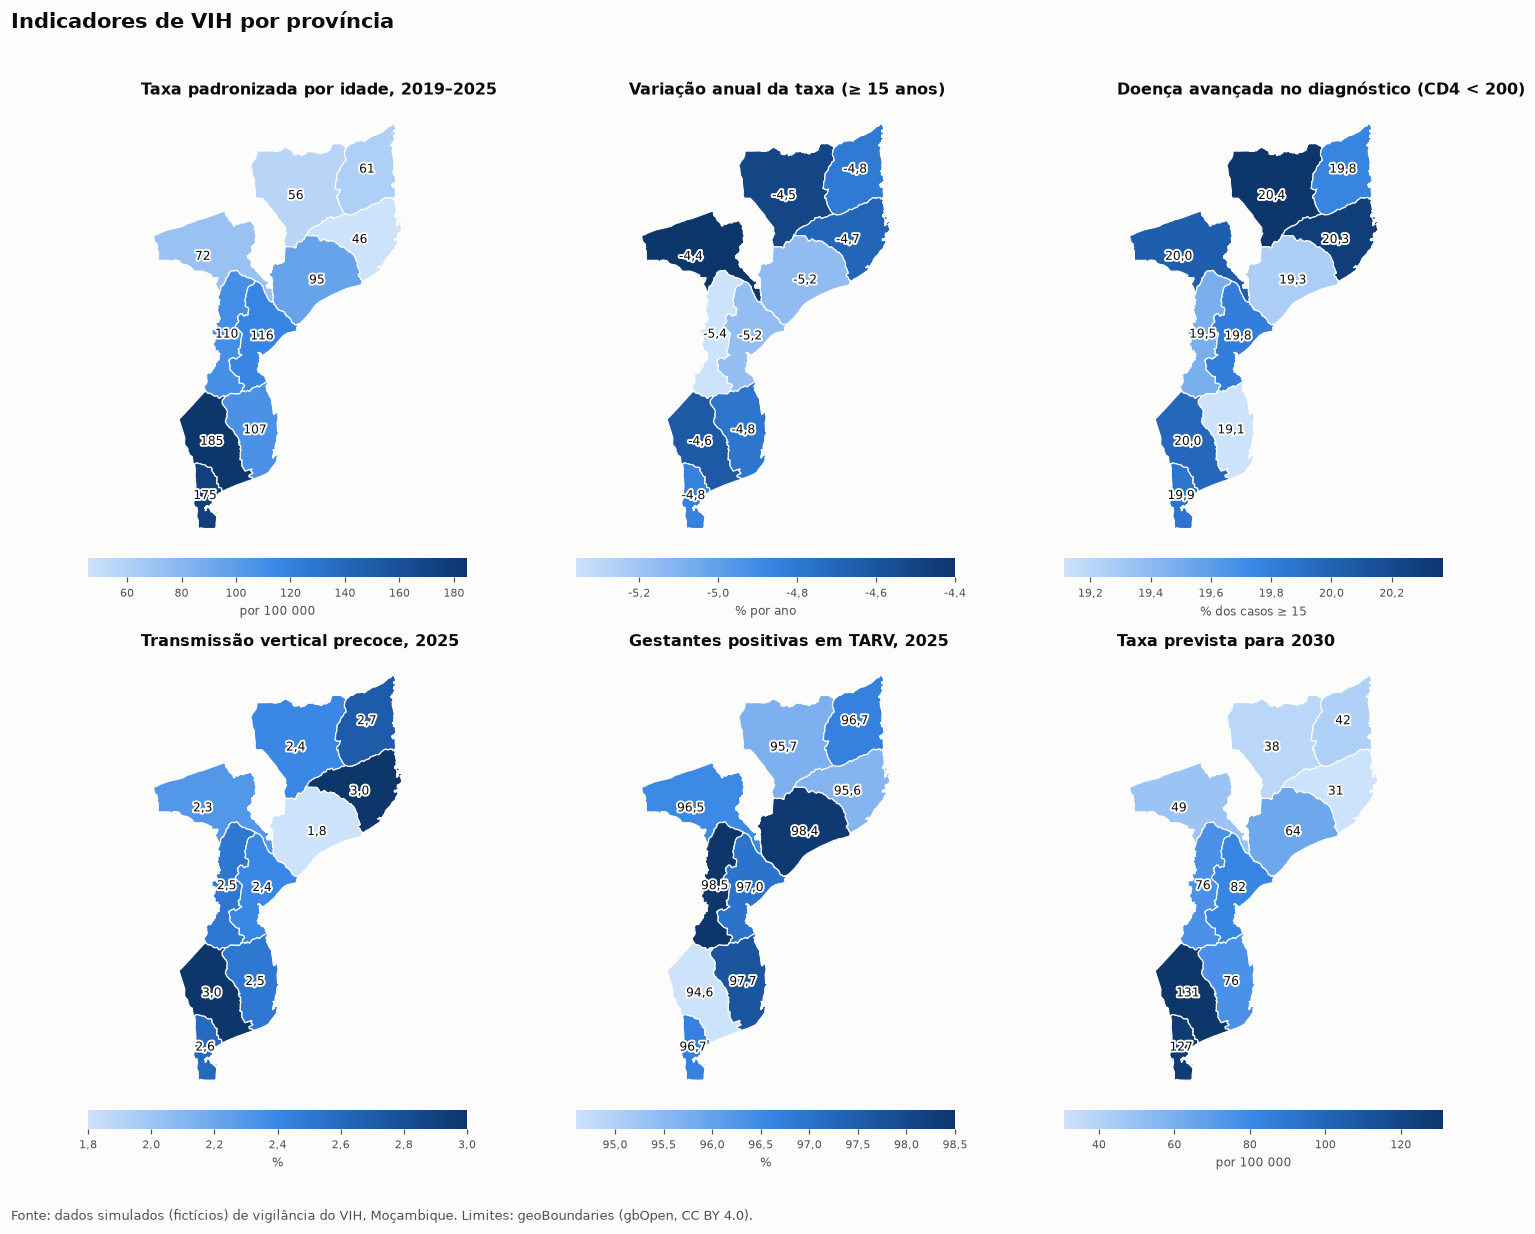

04:54:52 | INFO    |   → figura: 08_01_mapas_indicadores.png


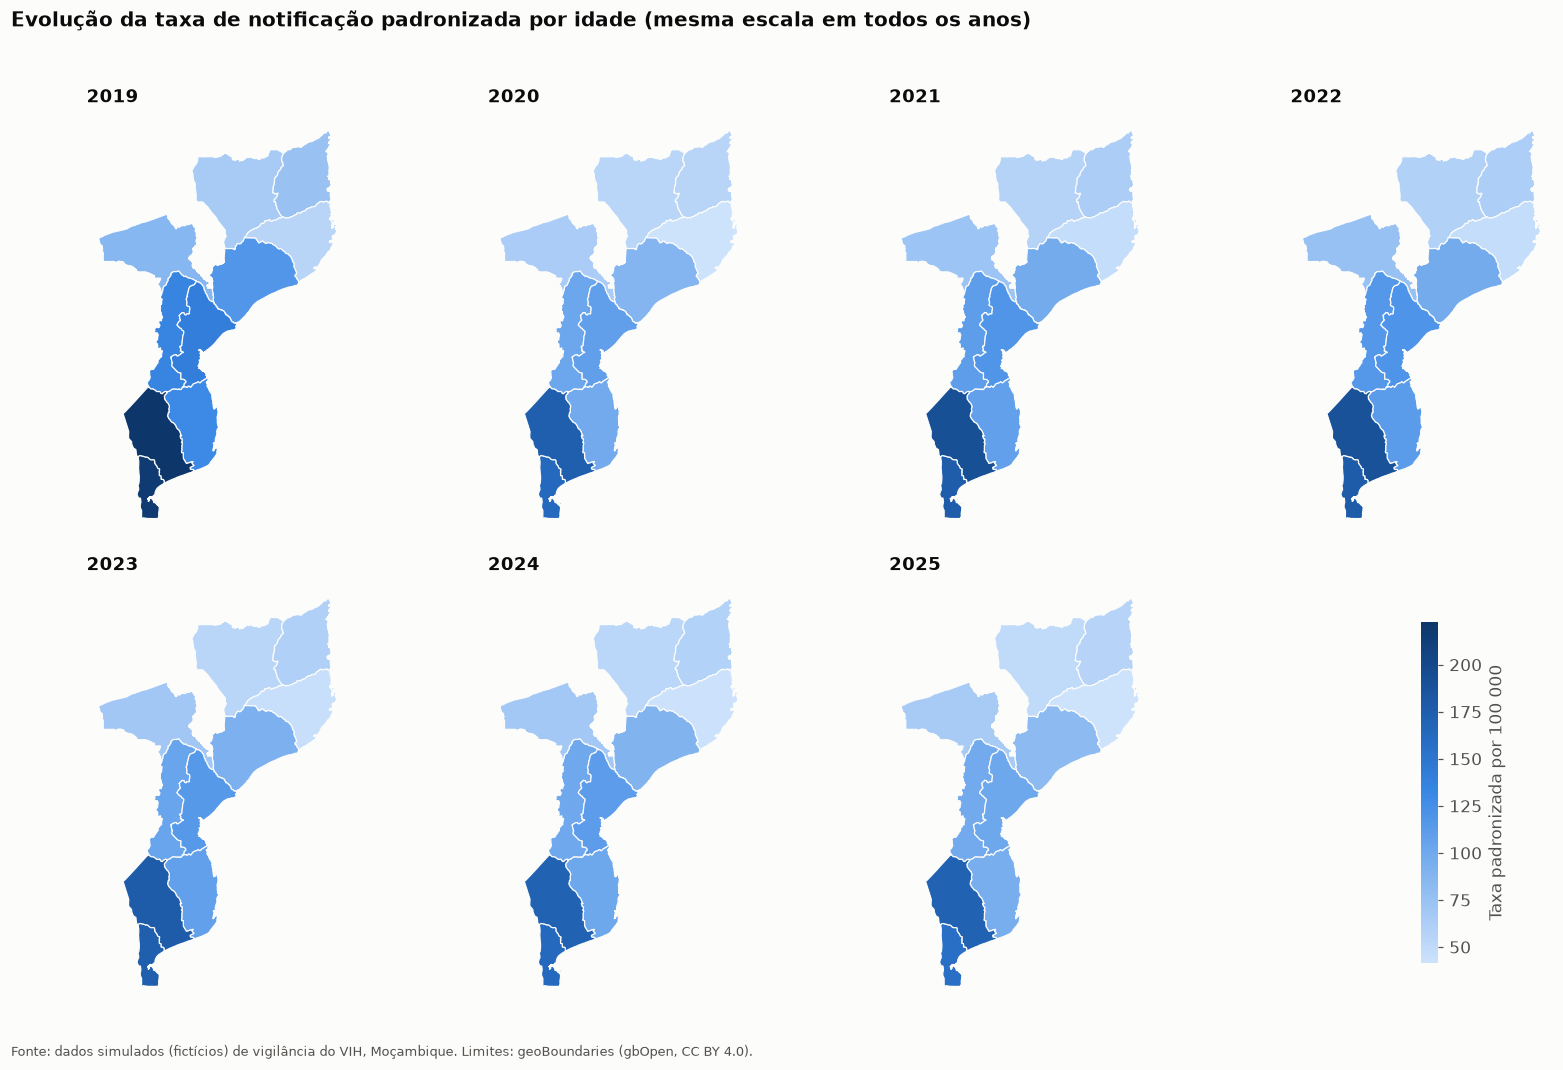

04:54:58 | INFO    |   → figura: 08_02_mapas_por_ano.png


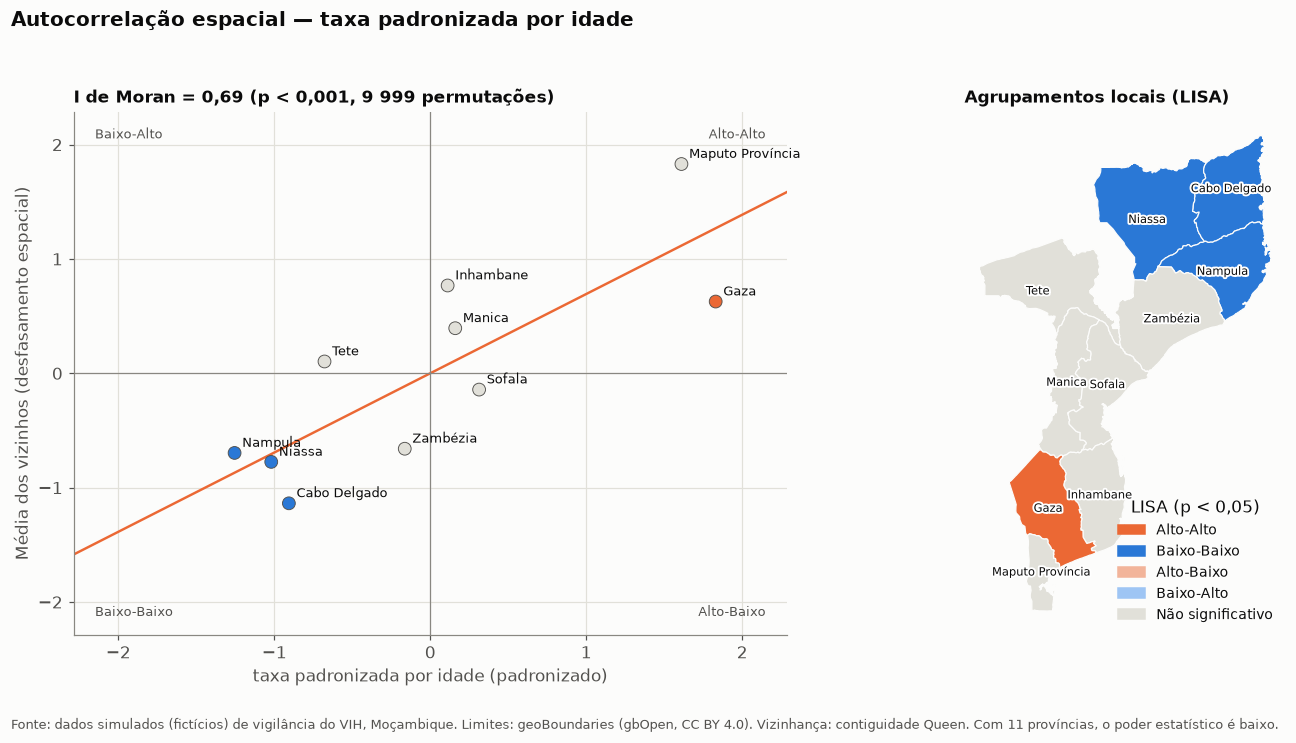

04:54:59 | INFO    |   → figura: 08_03_moran_lisa.png
04:54:59 | INFO    | Passo 8 concluído.


In [63]:
dados["geoespacial"] = passo8_geoespacial(dados)

---
## Gerar o relatório final

O relatório fica em `resultados/relatorio_vih_vigilancia.html`

In [64]:
dados["relatorio"] = passo7_relatorio(dados)
log.info(f"Registo guardado em: {ficheiro_log}")

04:54:59 | INFO    | ======================================================================
04:54:59 | INFO    | PASSO 7 — RELATÓRIO FINAL
04:54:59 | INFO    | ======================================================================
04:55:00 | INFO    |   Relatório: C:\Users\User\Downloads\projeto_vih_vigilancia_notebook\projeto_vih_vigilancia\resultados\relatorio_vih_vigilancia.html (5.0 MB)
04:55:00 | INFO    |   Abre o ficheiro com duplo clique (abre no browser).
04:55:00 | INFO    | Passo 7 concluído. Análise completa! ✔
04:55:00 | INFO    | Registo guardado em: C:\Users\User\Downloads\projeto_vih_vigilancia_notebook\projeto_vih_vigilancia\resultados\registos\analise_20261025_045325.log
